In [1287]:
import numpy as np
import pandas as pd
import random

In [1289]:
###NOTE NOTE NOTE

#this is first running the base model at the beginning of the day (no - disruption)
#then based on DST (disruption start time) determining the remaining nodes (both the truck and the drone nodes)
#determining the truck and the drone location at the time of DST
#since after the disruption it is not a TSP rather it is a hamiltonian path, we need to add a dummy node for concorde solution
#we add this dummy node 
#then we get the concorde solution 
#we delete the dummy node from the concorde TSP solution and provide this concorde solution to the disruption scenario as an input
#then we run the disruption scenario and check the feasibility (currently this part is not in this notebook) 


In [1291]:
#############details of the code 

In [1294]:
def t_pathcost(route, V):
    """
    Calculates total travel time for a truck-only TSP route.

    Parameters:
    - route: list of node indices in order (e.g., [0, 2, 3, 1])
    - V: dictionary mapping node index to (x, y) coordinates

    Returns:
    - Total truck travel time (float)
    """

    total = 0
    n = len(route)
    
    for i in range(n):
        current_node = route[i]
        next_node = route[(i + 1) % n]  # Loop back to start
        total += t_cost(V[current_node], V[next_node])
    
    return total


In [1296]:
#generating_functions.py
#This file contains functions to generate test cases — that is, sets of coordinates for the depot and customer nodes used in TSP-D problems.
def generate_coordinates_square(n, lower=0, upper=100):
    """
    Generates `n` random 2D coordinates within a square [lower, upper] x [lower, upper].

    Parameters:
    - n: number of customer locations (excluding depot)
    - lower: lower bound of coordinate values
    - upper: upper bound of coordinate values

    Returns:
    - V: dictionary of node index to (x, y) coordinates
         depot is always assigned index 0
    """
    V = {0: (random.uniform(lower, upper), random.uniform(lower, upper))}  # depot

    for i in range(1, n + 1):
        V[i] = (random.uniform(lower, upper), random.uniform(lower, upper))

    return V


In [1298]:
generate_coordinates_square(n=5, lower=0, upper=20)

{0: (16.888437030500963, 15.159088058806049),
 1: (8.4114316166169, 5.178335005859267),
 2: (10.22549442737217, 8.098682749008287),
 3: (15.675971780695452, 6.066254521578549),
 4: (9.531939083047117, 11.667640789100624),
 5: (18.162257703906704, 10.093737116347805)}

In [1300]:
V1 = [[5.84, 3.26],
 [8.89, 6.26],
 [8.19, 5.47],
 [4.17, 7.43],
 [3.7, 0.75],
 [7.75, 2.19],
 [0.79, 4.87],
 [1.54, 8.28],
 [1.91, 2.7],
 [5.61, 9.02],
 [8.52, 4.18],
 [3.93, 0.16],
 [2.99, 3.54],
 [5.84, 3.26]]

In [1302]:
tsp1 = [0, 12, 11, 4, 8, 6, 7, 3, 9, 2, 1, 10, 5, 13]

In [1304]:
len(tsp1)

14

In [1306]:
'''
##########additional  generating txt file for concorde NO NEED FOR THIS NOW
#########THIS FORMAT IS IN x-y coordinates use L1 (manhattan) or L2 (euclidean) when loaded to CONCORDE 
from pathlib import Path

# Replace this with your node list, for example: V1 = [[x1, y1], [x2, y2], ...]
V1 = [
    [7.57, 8.71],
    [1.17, 4.72],
    [7.90, 3.27],
    [4.54, 6.59],
    [2.82, 8.93],
    [8.82, 8.16],
    [9.37, 5.69],
    [6.67, 7.03],
    [6.36, 9.69],
    [6.62, 1.93],
    [9.67, 0.68],
    [5.14, 6.25],
    [5.04, 0.70],
    [7.57, 8.71],  # repeated first node
]

def create_concorde_l1_file(coords, output_path, scale=100):
    """
    Creates a Concorde-compatible xy file for 'xy list, distances measured in L1 norm'.

    Format written:
    first line  -> number of nodes
    next lines  -> integer x y coordinates

    Parameters
    ----------
    coords : list of [x, y]
        Input coordinates.
    output_path : str or Path
        Full path of the txt file to create.
    scale : int
        Multiplies decimal coordinates before rounding to integers.
    """
    if not coords:
        raise ValueError("Coordinate list is empty.")

    # Remove duplicated last node if same as first
    cleaned = coords[:]
    if len(cleaned) > 1 and cleaned[0] == cleaned[-1]:
        cleaned = cleaned[:-1]

    # Convert to integer coordinates
    int_coords = []
    for pt in cleaned:
        if len(pt) != 2:
            raise ValueError(f"Invalid point: {pt}. Each node must have exactly 2 values.")
        x, y = pt
        int_x = int(round(float(x) * scale))
        int_y = int(round(float(y) * scale))
        int_coords.append((int_x, int_y))

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(f"{len(int_coords)}\n")
        for x, y in int_coords:
            f.write(f"{x} {y}\n")

    print("File created successfully:")
    print(output_path)
    print("\nCreated file contents:\n")
    with open(output_path, "r", encoding="utf-8") as f:
        print(f.read())


# Full file path
file_path = r"H:\Documents\recourse model\MEETING 2026\March182026\concorde_xy_L1_V1.txt"

# Create the file
create_concorde_l1_file(V1, file_path)
##########additional  generating txt file for concorde NO NEED FOR THIS NOW
#########THIS FORMAT IS IN x-y coordinates use L1 (manhattan) or L2 (euclidean) when loaded to CONCORDE 
'''

'\n##########additional  generating txt file for concorde NO NEED FOR THIS NOW\n#########THIS FORMAT IS IN x-y coordinates use L1 (manhattan) or L2 (euclidean) when loaded to CONCORDE \nfrom pathlib import Path\n\n# Replace this with your node list, for example: V1 = [[x1, y1], [x2, y2], ...]\nV1 = [\n    [7.57, 8.71],\n    [1.17, 4.72],\n    [7.90, 3.27],\n    [4.54, 6.59],\n    [2.82, 8.93],\n    [8.82, 8.16],\n    [9.37, 5.69],\n    [6.67, 7.03],\n    [6.36, 9.69],\n    [6.62, 1.93],\n    [9.67, 0.68],\n    [5.14, 6.25],\n    [5.04, 0.70],\n    [7.57, 8.71],  # repeated first node\n]\n\ndef create_concorde_l1_file(coords, output_path, scale=100):\n    """\n    Creates a Concorde-compatible xy file for \'xy list, distances measured in L1 norm\'.\n\n    Format written:\n    first line  -> number of nodes\n    next lines  -> integer x y coordinates\n\n    Parameters\n    ----------\n    coords : list of [x, y]\n        Input coordinates.\n    output_path : str or Path\n        Full pat

In [1308]:
# https://github.com/kaito2399/TSP-D-algorithms/blob/master/other_functions/solving_TSP.py
#this is named solving_TSP.py
import heapq
from basic_functions2 import t_cost
import itertools

## these algorithms return the routes

# 2-approximation algorithm using minimum spanning tree
def two_approximation_for_TSP(V):
    n = len(V)
    #prim
    mst = {i:[] for i in range(n)} # MST の隣接リスト
    X = set()
    heap = []
    for i in range(1,n):
        heapq.heappush(heap,(t_cost(V[0],V[i]),0,i))
    while len(heap)>0:
        (d,u,i)=heapq.heappop(heap)
        if i not in X:
            X.add(i)
            mst[u].append(i)
            mst[i].append(u)
            for w in range(n):
                if w not in X: heapq.heappush(heap,(t_cost(V[i],V[w]),i,w))
    #dfs
    res = []
    stack = [0]
    visited = [False]*n
    while len(stack)>0:
        i = stack.pop()
        if visited[i]: continue
        visited[i]=True
        res.append(i)
        for u in mst[i]: stack.append(u)
    return res

# 2-opt algorithm using edge swap
def two_opt_for_TSP(V):
    n = len(V)
    res = list(range(n))
    update = True
    while update:
        update = False
        for (i,j) in itertools.combinations(range(n),2):
            if ((t_cost(V[res[i]],V[res[i+1]])+t_cost(V[res[j]],V[res[(j+1)%n]]))>
                (t_cost(V[res[i]],V[res[j]])+t_cost(V[res[i+1]],V[res[(j+1)%n]]))):
                res[i+1:j+1] = res[j:i:-1]
                update = True
    return res

# dynamic programming
def DP_for_TSP(V):
    length = {} # length[(u,S)]: u を始点とし S の点すべてを回る最小経路長、ディクショナリ
    route = {} # route[(u,S)]: 最小経路長を達成するためのルート、ディクショナリ
    v = V[0]
    n = len(V)
    for i in range(1,n+1):
        for a in itertools.combinations(range(n),i):
            S = frozenset(a)
            for j in S:
                u = V[j]
                if i==1:
                    length[(j,S)] = t_cost(v,u)
                    route[(j,S)] = [j]
                else:
                    Sj = S-set([j]) # S から j を除いたもの
                    k=min(Sj,key=lambda k: length[(k,Sj)]+t_cost(V[k],u))#Sjの中でlength[(k,Sj)]+dist(V[k],u)が最小のものを返している
                    length[(j,S)] = length[(k,Sj)]+t_cost(V[k],u)
                    route[(j,S)] = route[(k,Sj)]+[j]
    return route[(0,frozenset(range(n)))]

In [1310]:
#https://github.com/kaito2399/TSP-D-algorithms/blob/master/other_functions/route_drawing.py
##this is named route_drawing.py
import matplotlib.pyplot as plt

# red for truck, blue for drone
def drawing_routes_for_DP(V,path,depot,drone_nodes):
  n = len(V)
  text_dict = dict(boxstyle = "round",fc = "silver", ec = "mediumblue")
  for i in range(n):
      plt.scatter(V[depot][0],V[depot][1],c='k')
      plt.annotate("DEPOT",size = 6, xy = (V[depot][0],V[depot][1]), bbox = text_dict)
      plt.scatter(V[i][0],V[i][1],c='k')
      if i in drone_nodes:
        plt.annotate(f"d{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
      elif i != 0:
        plt.annotate(f"t{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
  for i in range(len(path)):
      if len(path[i])>=3:
          for j in range(len(path[i])-2):
              truck_x=[V[path[i][j]][0],V[path[i][j+1]][0]]
              truck_y=[V[path[i][j]][1],V[path[i][j+1]][1]]
              plt.plot(truck_x, truck_y,c='red')
          truck_x=[V[path[i][-2]][0],V[path[(i+1)%len(path)][0]][0]]
          truck_y=[V[path[i][-2]][1],V[path[(i+1)%len(path)][0]][1]]
          drone_x1=[V[path[i][0]][0],V[path[i][-1][0]][0]]
          drone_y1=[V[path[i][0]][1],V[path[i][-1][0]][1]]
          drone_x2=[V[path[i][-1][0]][0],V[path[i][-2]][0]]
          drone_y2=[V[path[i][-1][0]][1],V[path[i][-2]][1]]
          plt.plot(truck_x,truck_y,c='red')
          plt.plot(drone_x1,drone_y1, c='blue')
          plt.plot(drone_x2,drone_y2, c='blue')
      elif len(path[i])==1:
          truck_x=[V[path[i][0]][0],V[path[i+1][0]][0]]
          truck_y=[V[path[i][0]][1],V[path[i+1][0]][1]]
          plt.plot(truck_x,truck_y, c='red')
      else:
          truck_x=[V[path[i][-2]][0],V[path[(i+1)%len(path)][0]][0]]
          truck_y=[V[path[i][-2]][1],V[path[(i+1)%len(path)][0]][1]]
          drone_x1=[V[path[i-1][0]][0],V[path[i][-1][0]][0]]
          drone_y1=[V[path[i-1][0]][1],V[path[i][-1][0]][1]]
          drone_x2=[V[path[i][-1][0]][0],V[path[i][-2]][0]]
          drone_y2=[V[path[i][-1][0]][1],V[path[i][-2]][1]]
          plt.plot(truck_x,truck_y,c='red')
          plt.plot(drone_x1,drone_y1, c='blue')
          plt.plot(drone_x2,drone_y2, c='blue')
  plt.show()

def drawing_routes_using_labels(V,label,depot,drone_nodes):
    tsp_route = [i for i in label.keys()]
    n = len(V)
    text_dict = dict(boxstyle = "round",fc = "silver", ec = "mediumblue")
    for i in range(n):
        plt.scatter(V[depot][0],V[depot][1],c='k')
        plt.annotate("DEPOT",size = 6, xy = (V[depot][0],V[depot][1]), bbox = text_dict)
        plt.scatter(V[i][0],V[i][1],c='k')
        if i in drone_nodes:
          plt.annotate(f"d{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
        elif i != 0:
          plt.annotate(f"t{i}",size = 6, xy = (V[i][0],V[i][1]),bbox = text_dict)
    for i in range(n):
      if label[tsp_route[i]] == "combined":
        if label[tsp_route[(i+1)%n]] == "combined":
          truck_x = (V[tsp_route[i]][0],V[tsp_route[(i+1)%n]][0])
          truck_y = (V[tsp_route[i]][1],V[tsp_route[(i+1)%n]][1])
          plt.plot(truck_x,truck_y,c="red")
        else:
          cnt = 1
          while label[tsp_route[(i+cnt)%n]] != "drone":
            cnt += 1
          drone_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
          drone_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
          plt.plot(drone_x,drone_y,c="blue")
          cnt = 1
          while label[tsp_route[(i+cnt)%n]] == "drone":
            cnt += 1
          truck_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
          truck_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
          plt.plot(truck_x,truck_y,c="red")
      elif label[tsp_route[i]] == "drone":
        cnt = 1
        while label[tsp_route[(i+cnt)%n]] != "combined":
          cnt += 1
        drone_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
        drone_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
        plt.plot(drone_x,drone_y,c="blue")
      else:
        cnt = 1
        while label[tsp_route[(i+cnt)%n]] == "drone":
          cnt += 1
        truck_x = (V[tsp_route[i]][0],V[tsp_route[(i+cnt)%n]][0])
        truck_y = (V[tsp_route[i]][1],V[tsp_route[(i+cnt)%n]][1])
        plt.plot(truck_x,truck_y,c="red")  
    plt.show()

In [1312]:
#https://github.com/kaito2399/TSP-D-algorithms/blob/master/other_functions/generating_functions.py
##named generating_functions.py
import random
import math
import numpy
random.seed(0)

# customers are located uniformly
def testcase_uniform(n):
    V=[(random.uniform(0,100),random.uniform(0,100)) for i in range(n)]
    return V

# customers are located in the shape of donut
def testcase_donuts(n):
    V=[]
    for i in range(n):
        angle=random.uniform(0,2*math.pi)
        V.append((25*random.uniform(0.9,1.1)*math.cos(angle)+50,25*random.uniform(0.9,1.1)*math.sin(angle)+50))
    return V

# customers are located in the shape of donuts but depot is in the center
def testcase_donuts_center(n):
    V=[(50,50)]
    for i in range(n-1):
        angle=random.uniform(0,2*math.pi)
        V.append((25*random.uniform(0.9,1.1)*math.cos(angle)+50,25*random.uniform(0.9,1.1)*math.sin(angle)+50))
    return V

# customers are located in more in center but less in outsides
def testcase_center(n):
    V=[]
    for i in range(n):
        angle=random.uniform(0,2*math.pi)
        r=numpy.random.normal(0,25)
        V.append((r*math.cos(angle)+50,r*math.sin(angle)+50))
    return V

In [1314]:
#https://github.com/kaito2399/TSP-D-algorithms/blob/master/heuristics/iterative_improvement_procedure.py
#named iterative_improvement_procedure.py

import itertools

# iとjの順番を入れ替える
# swap index i and j
def two_points_move(lis,i,j):
    if i<j:
      new_list=lis[:i]+[lis[j]]+lis[(i+1):j]+[lis[i]]+lis[(j+1):]
    else:
      new_list=lis[:j]+[lis[i]]+lis[(j+1):i]+[lis[j]]+lis[(i+1):]
    return new_list

# 2辺を入れ替える
# swap two edges
def two_opt_move(lis,i,j):
    if i<j:
      new_list=lis[:i+1]+lis[j:(i+1)%len(lis)-1:-1]+lis[(j+1):]
    else:
      new_list=[lis[i]]+lis[j::-1]+lis[:(i+1)%len(lis)-1:-1]+lis[j+1:i]
    return new_list

# iをj番目に挿入する
# insert i to j
def one_point_move(lis,i,j):
    if i<j:
      new_list=lis[:i]+lis[(i+1):(j+1)]+[lis[i]]+lis[(j+1):]
    else:
      new_list=lis[:j]+[lis[i]]+lis[j:i]+lis[(i+1):]
    return new_list

# improving procedure using one of the moves
def improve(move,heuristic,lis,depot,V,alpha):
    n=len(lis)
    initial=lis
    f=heuristic(initial,depot)[0]
    update=True
    while update:
        update=False
        for (i,j) in itertools.permutations(range(n),2):
            newroute=move(lis,i,j)
            if f>heuristic(V,newroute,depot,alpha)[0]:
                update=True
                initial=newroute
                f=heuristic(V,newroute,depot,alpha)[0]
        if update:
            lis=initial
    return initial

# improving procedure using all of the moves
'''
def improve_all(heuristic,lis,depot,V,alpha):
    n=len(lis)
    initial=lis
    f=heuristic(V,initial,depot,alpha)[0]
    update=True
    while update:
        update=False
        for (i,j) in itertools.permutations(range(n),2):
            #moves=[two_points_move(lis,i,j),two_opt_move(lis,i,j),one_point_move(lis,i,j)]
            moves=[one_point_move(lis,i,j)] #v1 we want it to use only one-point move so updated
            for newroute in moves:
                if f>heuristic(V,newroute,depot,alpha)[0]:
                    update=True
                    initial=newroute
                    f=heuristic(V,newroute,depot,alpha)[0]
        if update:
            lis=initial
    return initial
'''


'\ndef improve_all(heuristic,lis,depot,V,alpha):\n    n=len(lis)\n    initial=lis\n    f=heuristic(V,initial,depot,alpha)[0]\n    update=True\n    while update:\n        update=False\n        for (i,j) in itertools.permutations(range(n),2):\n            #moves=[two_points_move(lis,i,j),two_opt_move(lis,i,j),one_point_move(lis,i,j)]\n            moves=[one_point_move(lis,i,j)] #v1 we want it to use only one-point move so updated\n            for newroute in moves:\n                if f>heuristic(V,newroute,depot,alpha)[0]:\n                    update=True\n                    initial=newroute\n                    f=heuristic(V,newroute,depot,alpha)[0]\n        if update:\n            lis=initial\n    return initial\n'

In [1316]:
##############details of the code 

In [1319]:
#5555
##new updated one (travel times) 
def compute_truck_times_manhattan(V):
    n = len(V)
    tT = {}
    for i in range(n):
        xi, yi = V[i]
        for j in range(n):
            xj, yj = V[j]
            dist_ij = abs(xi - xj) + abs(yi - yj)
            tT[(i, j)] = float(dist_ij)
            tT[(i, j)] = ((float(dist_ij))*60)/25
    return tT


def compute_drone_times_euclidean(V, alpha=1.0):
    n = len(V)
    dT = {}
    for i in range(n):
        xi, yi = V[i]
        for j in range(n):
            xj, yj = V[j]
            dx = xi - xj
            dy = yi - yj
            dist_ij = (dx*dx + dy*dy) ** 0.5
            #dT[(i, j)] = (float(alpha * dist_ij))*60
            dT[(i, j)] = ((float(alpha * dist_ij))*60)/35
    return dT


In [1321]:
alpha = 1.0
tT = compute_truck_times_manhattan(V1)
dT = compute_drone_times_euclidean(V1,alpha = 1)
tT

{(0, 0): 0.0,
 (0, 1): 14.520000000000003,
 (0, 2): 10.943999999999999,
 (0, 3): 14.015999999999998,
 (0, 4): 11.159999999999998,
 (0, 5): 7.152,
 (0, 6): 15.984000000000002,
 (0, 7): 22.368000000000002,
 (0, 8): 10.776,
 (0, 9): 14.376,
 (0, 10): 8.639999999999999,
 (0, 11): 12.024,
 (0, 12): 7.512,
 (0, 13): 0.0,
 (1, 0): 14.520000000000003,
 (1, 1): 0.0,
 (1, 2): 3.5760000000000023,
 (1, 3): 14.136000000000001,
 (1, 4): 25.68,
 (1, 5): 12.504000000000001,
 (1, 6): 22.776000000000003,
 (1, 7): 22.488000000000003,
 (1, 8): 25.296,
 (1, 9): 14.495999999999999,
 (1, 10): 5.880000000000003,
 (1, 11): 26.544,
 (1, 12): 20.688000000000002,
 (1, 13): 14.520000000000003,
 (2, 0): 10.943999999999999,
 (2, 1): 3.5760000000000023,
 (2, 2): 0.0,
 (2, 3): 14.351999999999999,
 (2, 4): 22.103999999999996,
 (2, 5): 8.927999999999999,
 (2, 6): 19.2,
 (2, 7): 22.703999999999997,
 (2, 8): 21.719999999999995,
 (2, 9): 14.711999999999998,
 (2, 10): 3.888,
 (2, 11): 22.968000000000004,
 (2, 12): 17.112,
 

In [1324]:
OnlyTruck = 0
for i in range (len(tsp1) -1):
    OnlyTruck += tT[tsp1[i],tsp1[i+1]]
OnlyTruck
    

100.272

In [1327]:
##THIS IS MY OWN DEFINITION OF COST FUNCTIONS
#THIS IS UPDATED t-cost and d-cost

# cost(time) of trucks
def t_cost(s, t):
    return ((60/25)*(abs(s[0] - t[0]) + abs(s[1] - t[1])))
    
# cost(time) of drones
def d_cost(s,t,alpha): 
  return (1/alpha)*(60/35)*(((s[0]-t[0])**2+(s[1]-t[1])**2)**(0.5))

## t_cost > d_cost holds


def t_pathcost(a,b,route,V):
    pathcost=0
    if a<b:
        for i in range(a,b):
            pathcost=pathcost+t_cost(V[route[i]],V[route[(i+1)%len(route)]])
    if a>b:
        for i in range(a,len(route)):
            pathcost=pathcost+t_cost(V[route[i]],V[route[(i+1)%len(route)]])
        for i in range(b):
            pathcost=pathcost+t_cost(V[route[i]],V[route[(i+1)%len(route)]])
    if a==b:
        pathcost=0
            
    return pathcost

In [1329]:

# cost(time) of trucks
def t_cost(s, t):
    return ((60/25)*(abs(s[0] - t[0]) + abs(s[1] - t[1])))
    
# cost(time) of drones
def d_cost(s,t,alpha): 
  return (1/alpha)*(60/35)*(((s[0]-t[0])**2+(s[1]-t[1])**2)**(0.5))


In [1331]:
#############

In [1334]:
'''
# ================================
# TSP-D base model (requires ready tT/dT)
# Greedy partition (MakeFly/PushLeft/PushRight)
# Schedule + True Makespan (truck path + waits + SL + SR)
# Linearized labels along 0 -> ... -> end depot
# ================================

import sys, time as _time
import numpy as _np
import numpy
from collections import OrderedDict, defaultdict
from typing import Dict, Tuple, List

# ---------- You provide ----------
# V1 : List[List[float]]
# tT : dict {(i,j): truck travel time}
# dT : dict {(i,j): drone travel time}
# optional: tsp1 initial tour (Concorde)
# ---------------------------------

# ---------- Reproducibility ----------
SEED = 1040
SAMPLE_RATIO = 0.05  # for tour local search (sampled neighbors)

# ---------- Service times ----------
SL = 1.0   # launch service (0 at depot)
SR = 1.0   # recovery service at rendezvous

# ---------- Mission energy/feasibility limit (time) ----------
E_LIMIT = 20.0 #for 12-customer instances

# ---------- Optional drawing ----------
DRAW_ROUTES = True
sys.path.append("../")
try:
    from route_drawing import drawing_routes_using_labels
except Exception:
    drawing_routes_using_labels = None

try:
    from solving_TSP import two_opt_for_TSP
except Exception:
    def two_opt_for_TSP(V):
        return list(range(len(V)))

# =========================================================
# Travel-time accessors (REQUIRES ready tT/dT)
# =========================================================
def _ensure_travel_times():
    global tT, dT
    assert isinstance(tT, dict) and isinstance(dT, dict), \
        "You must predefine ready dicts tT and dT before running."

def truck_time(i, j):  # symmetric lookup ok
    try: return tT[(i,j)]
    except KeyError: return tT[(j,i)]

def drone_time(i, j):
    try: return dT[(i,j)]
    except KeyError: return dT[(j,i)]

# =========================================================
# Greedy partition: MakeFly / PushLeft / PushRight
# =========================================================
def greedy_partitioning(tsp, depot, V1):
    """
    Build TSP-D partition on a fixed truck-only TSP tour 'tsp'.
    Returns: (tspd_total, label, drone_nodes, drone_mission, operation, flyop, driveop)
    """
    _ensure_travel_times()
    n = len(tsp)
    end_depot = len(V1) - 1
    ND =  {4, 5, depot, end_depot} # disallow depots as drone-only customers 12-customer instances
    #ND = {depot, end_depot}  # disallow depots as drone-only customers

    label = {}
    operation, flyop, driveop = {}, {}, {}
    drone_mission = {}  # d -> (L,R)

    # base truck tour cost around cycle
    tsptotal = 0.0
    for k in range(n):
        i, j = tsp[k], tsp[(k+1)%n]
        label[i] = 'simple'
        tsptotal += truck_time(i, j)
    tspdtotal = tsptotal

    while 'simple' in label.values():
        ms = []

        # 1) Make Fly
        for i in range(n):
            saving = -float('inf')
            u = tsp[i]
            if label[u] == 'simple' and u not in ND:
                L = tsp[i-1]
                R = tsp[(i+1)%n]
                fly_time = drone_time(L,u) + drone_time(u,R)
                if fly_time + SL <= E_LIMIT and truck_time(L,R) <= E_LIMIT:
                    base = truck_time(L,u) + truck_time(u,R)
                    alt  = max(fly_time, truck_time(L,R) + SL + SR)
                    saving = base - alt
            ms.append(saving)

        # 2) Push Left
        for i in range(n):
            saving = -float('inf')
            cur = tsp[i]
            prev = tsp[i-1]
            if label.get(prev) == 'combined' and prev != depot and label.get(cur) == 'simple':
                j = i - 2
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[j-1]] == 'combined' and dronenode is not None:
                        d  = tsp[dronenode]
                        L  = tsp[j-1]
                        R_old = prev
                        R_new = cur
                        base_key = (d,L,R_old)
                        if (d not in ND) and (base_key in operation) and (base_key in driveop):
                            fly_new   = drone_time(L,d) + drone_time(d,R_new)
                            drive_new = driveop[base_key] + truck_time(R_old, R_new)
                            if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                saving = truck_time(R_old, R_new) + operation[base_key] - \
                                         max(fly_new, drive_new + SR)
                        break
                    j -= 1
            ms.append(saving)

        # 3) Push Right
        for i in range(n):
            saving = -float('inf')
            cur = tsp[i]
            nxt = tsp[(i+1)%n]
            if label.get(nxt) == 'combined' and nxt != depot and label.get(cur) == 'simple':
                j = (i+2) % n
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[(j+1)%n]] == 'combined' and dronenode is not None:
                        d = tsp[dronenode]
                        L_old = nxt
                        R_new = tsp[(j+1)%n]
                        base_key = (d, L_old, R_new)
                        if (d not in ND) and (base_key in operation) and (base_key in driveop):
                            fly_new   = drone_time(cur,d) + drone_time(d,R_new)
                            drive_new = driveop[base_key] + truck_time(cur, L_old)
                            if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                saving = truck_time(cur, L_old) + operation[base_key] - \
                                         max(fly_new, drive_new + SR)
                        break
                    j = (j+1) % n
            ms.append(saving)

        idx = int(numpy.argmax(ms))
        if ms[idx] <= 0:
            for u in label:
                if label[u] == 'simple':
                    label[u] = 'combined'
            break

        tspdtotal -= ms[idx]
        block = idx // n
        pos   = idx %  n

        if block == 0:
            # Make Fly
            d = tsp[pos]
            L = tsp[pos-1]
            R = tsp[(pos+1)%n]
            label[d] = 'drone'
            label[L] = 'combined'
            label[R] = 'combined'
            flyop[(d,L,R)]   = drone_time(L,d) + drone_time(d,R)
            driveop[(d,L,R)] = truck_time(L,R)
            operation[(d,L,R)] = max(flyop[(d,L,R)], driveop[(d,L,R)])
            drone_mission[d] = (L,R)

        elif block == 1:
            # Push Left
            label[tsp[pos]] = 'combined'
            label[tsp[(pos-1)%n]] = 'truck'
            j = (pos-2) % n
            dronenode = None
            while label[tsp[j]] != 'combined':
                if label[tsp[j]] == 'drone':
                    dronenode = j
                if label[tsp[j-1]] == 'combined' and dronenode is not None:
                    d = tsp[dronenode]
                    L = tsp[j-1]
                    R_new  = tsp[pos]
                    prev_R = tsp[(pos-1)%n]
                    flyop[(d,L,R_new)]   = drone_time(L,d) + drone_time(d,R_new)
                    driveop[(d,L,R_new)] = driveop[(d,L,prev_R)] + truck_time(prev_R, R_new)
                    operation[(d,L,R_new)] = max(flyop[(d,L,R_new)], driveop[(d,L,R_new)])
                    drone_mission[d] = (L,R_new)
                    break
                j -= 1

        else:
            # Push Right
            label[tsp[pos]] = 'combined'
            label[tsp[(pos+1)%n]] = 'truck'
            j = (pos+2) % n
            dronenode = None
            while label[tsp[j]] != 'combined':
                if label[tsp[j]] == 'drone':
                    dronenode = j
                if label[tsp[(j+1)%n]] == 'combined' and dronenode is not None:
                    d = tsp[dronenode]
                    L_new = tsp[pos]
                    R = tsp[(j+1)%n]
                    next_L = tsp[(pos+1)%n]
                    flyop[(d,L_new,R)]   = drone_time(L_new,d) + drone_time(d,R)
                    driveop[(d,L_new,R)] = driveop[(d,next_L,R)] + truck_time(L_new, next_L)
                    operation[(d,L_new,R)] = max(flyop[(d,L_new,R)], driveop[(d,L_new,R)])
                    drone_mission[d] = (L_new, R)
                    break
                j = (j+1) % n

    dset = {u for u in label if label[u] == 'drone'}
    return tspdtotal, label, dset, drone_mission, operation, flyop, driveop

# =========================================================
# Schedule (truck_times, drone_times)
# =========================================================
def compute_arrival_times(tsp, depot, label, drone_mission):
    truck_path = [u for u in tsp if label.get(u,'combined') != 'drone']
    missions_by_L = defaultdict(list)
    missions_by_R = defaultdict(list)
    for d,(L,R) in drone_mission.items():
        missions_by_L[L].append(d)
        missions_by_R[R].append(d)

    truck_times, drone_times = {}, {}
    drone_R_time = {}

    if not truck_path:
        return truck_times, drone_times

    for u in truck_path:
        drone_times[u] = [0.0, 0.0]

    t = 0.0
    start = truck_path[0]
    truck_times[start] = [t, t]

    # launches at start
    if start in missions_by_L:
        for d in missions_by_L[start]:
            L = start; R = drone_mission[d][1]
            sl = 0.0 if L == depot else SL
            t += sl
            truck_times[L][1] = t
            arrL = truck_times[L][0]
            drone_times[L] = [arrL, t]
            d_arr = t + drone_time(L,d)
            R_arr = d_arr + drone_time(d,R)
            drone_times[d] = [d_arr, d_arr]
            drone_R_time[d] = R_arr

    # traverse
    for k in range(1, len(truck_path)):
        prev = truck_path[k-1]
        cur  = truck_path[k]
        t += truck_time(prev, cur)
        truck_times[cur] = [t, t]

        # recoveries
        if cur in missions_by_R:
            latest = max(drone_R_time[d] for d in missions_by_R[cur] if d in drone_R_time) \
                     if missions_by_R[cur] else t
            if latest > t:
                t = latest
            t += SR
            truck_times[cur][1] = t
            for d in missions_by_R[cur]:
                if d in drone_R_time:
                    drone_times[cur] = [drone_R_time[d], t]

        # launches at cur
        if cur in missions_by_L:
            for d in missions_by_L[cur]:
                L = cur; R = drone_mission[d][1]
                sl = 0.0 if L == depot else SL
                t += sl
                truck_times[L][1] = t
                arrL = truck_times[L][0]
                if L not in drone_times:
                    drone_times[L] = [arrL, t]
                else:
                    if drone_times[L][0] == 0.0:
                        drone_times[L][0] = arrL
                    drone_times[L][1] = max(drone_times[L][1], t)
                d_arr = t + drone_time(L,d)
                R_arr = d_arr + drone_time(d,R)
                drone_times[d] = [d_arr, d_arr]
                drone_R_time[d] = R_arr

    return truck_times, drone_times

# =========================================================
# True makespan (your formula) helpers
# =========================================================
def linearize_between_depots(tour, start_depot, end_depot):
    """Linearize the cycle to  start_depot -> ... -> first hit of end_depot."""
    n = len(tour)
    i = tour.index(start_depot)
    path = [start_depot]
    j = (i + 1) % n
    while tour[j] != end_depot:
        path.append(tour[j])
        j = (j + 1) % n
    path.append(end_depot)
    return path

def truck_path_time_0_to_end(tsp, label, start_depot, end_depot):
    truck_cycle = [u for u in tsp if label.get(u,'combined') != 'drone']
    path = linearize_between_depots(truck_cycle, start_depot, end_depot)
    total = 0.0
    for i in range(1, len(path)):
        total += truck_time(path[i-1], path[i])
    return total, path

def compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=None):
    """
    Return {R: truck wait (sec)} at rendezvous R (excludes SR).
    If 'depot' is given, missions with R == depot are ignored (no waiting at start depot).
    """
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        if depot is not None and R == depot:
            continue
        missions_by_R[R].append((d, L))

    wait = {}
    for R, pairs in missions_by_R.items():
        if R not in truck_times:
            continue
        t_truck_arr = truck_times[R][0]
        latest_R_arr = float("-inf")
        for d, L in pairs:
            tL = drone_times[L][1]
            d_arr = tL + drone_time(L,d)
            R_arr = d_arr + drone_time(d,R)
            latest_R_arr = max(latest_R_arr, R_arr)
        wait[R] = max(0.0, latest_R_arr - t_truck_arr)
    return wait

def count_launches_excluding_depot(drone_mission, depot):
    return sum(1 for d,(L,_) in drone_mission.items() if L != depot)

def true_makespan_from_formula(tsp, label, truck_times, drone_times, drone_mission, depot, end_depot):
    truck_travel_sum, _truck_path = truck_path_time_0_to_end(tsp, label, depot, end_depot)
    waits = compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=depot)
    total_wait = sum(waits.values())
    launches_excl_depot = count_launches_excluding_depot(drone_mission, depot)
    recoveries = len(drone_mission)
    return truck_travel_sum + total_wait + SL*launches_excl_depot + SR*recoveries

# =========================================================
# Tour LS (sampled neighbors)
# =========================================================
def two_points_move(route, i, j):
    r = route[:]; r[i], r[j] = r[j], r[i]; return r

def two_opt_move(route, i, j):
    if i > j: i, j = j, i
    return route[:i+1] + route[i+1:j+1][::-1] + route[j+1:]

def one_point_move(route, i, j):
    if i == j: return route[:]
    r = route[:]; node = r.pop(i); r.insert(j, node); return r

def _rotate_to_depot(route, depot):
    if route[0] == depot: return route
    k = route.index(depot); return route[k:] + route[:k]

def improve_all(heuristic, route_in, depot, V1, sample_ratio=SAMPLE_RATIO, rng_seed=SEED):
    _ensure_travel_times()
    n = len(route_in)
    route_best = _rotate_to_depot(list(route_in), depot)
    cache = {}
    def eval_route(rt):
        key = tuple(rt)
        if key in cache: return cache[key]
        rt0 = _rotate_to_depot(rt, depot)
        val = heuristic(rt0, depot, V1)[0]
        cache[key] = val
        return val
    f_best = eval_route(route_best)
    if rng_seed is not None:
        _np.random.seed(rng_seed)
    all_pairs = [(i,j) for i in range(n) for j in range(n) if j != i]
    m = len(all_pairs); k = max(1, int(round(sample_ratio*m)))
    improved = True
    while improved:
        improved = False
        idxs = _np.random.choice(m, size=k, replace=False)
        best_neighbor, best_cost = None, f_best
        for p in idxs:
            i,j = all_pairs[p]
            for mv in (two_points_move, two_opt_move, one_point_move):
                cand = _rotate_to_depot(mv(route_best, i, j), depot)
                fc   = eval_route(cand)
                if fc < best_cost - 1e-12:
                    best_neighbor, best_cost = cand, fc
        if best_neighbor is not None:
            route_best, f_best, improved = best_neighbor, best_cost, True
    return route_best

# =========================================================
# Wrapper: seed tour -> LS -> partition -> schedule
# =========================================================
def two_opt_greedy_partitioning_all_improved(V1, depot, tsp_init=None):
    _ensure_travel_times()
    n = len(V1)
    if tsp_init is not None:
        tsp_seed = list(tsp_init)
    else:
        try:
            from __main__ import tsp1
            tsp_seed = list(tsp1)
            print("[INFO] Using Concorde tour (tsp1) as initial tour.")
        except Exception:
            tsp_seed = two_opt_for_TSP(V1)
            print("[INFO] Concorde tsp1 not found; using 2-opt seed.")
    if len(tsp_seed) != n or sorted(tsp_seed) != list(range(n)):
        raise ValueError("Initial tour must be a permutation of 0..n-1 with length len(V1).")
    tsp_seed = _rotate_to_depot(tsp_seed, depot)
    tsp_best = improve_all(greedy_partitioning, tsp_seed, depot, V1,
                           sample_ratio=SAMPLE_RATIO, rng_seed=SEED)
    total_cost, label, drone_nodes, drone_mission, operation, flyop, driveop = greedy_partitioning(
        tsp_best, depot, V1
    )
    truck_times, drone_times = compute_arrival_times(tsp_best, depot, label, drone_mission)
    return (total_cost, label, drone_nodes, drone_mission, truck_times, drone_times), tsp_best

# =========================================================
# MAIN
# =========================================================
def main():
    global V1  # provided externally
    _ensure_travel_times()  # <- requires your tT/dT
    depot = 0
    END_DEPOT = len(V1) - 1
    _np.random.seed(SEED)

    print("-" * 120)
    try:
        from __main__ import tsp1
        tsp_init = tsp1
    except Exception:
        tsp_init = None

    start = _time.time()
    (total_cost,
     label,
     drone_nodes,
     drone_mission,
     truck_times,
     drone_times), tsp_used = two_opt_greedy_partitioning_all_improved(
        V1, depot, tsp_init=tsp_init
    )
    end = _time.time()

    # True makespan (your formula)
    f_true = true_makespan_from_formula(
        tsp_used, label, truck_times, drone_times, drone_mission, depot, END_DEPOT
    )

    print(f"Running time: {end-start:.4f} sec")
    print(f"Heuristic TSP-D cost (truck - ops): {total_cost:.4f}")
    print(f"True makespan from schedule: {f_true:.4f}")
    print(f"# drone customers: {len(drone_nodes)}")
    print("SEED is:", SEED)
    print("SAMPLE_RATIO is:", SAMPLE_RATIO)

    # Show labels along 0 -> ... -> END_DEPOT (PATH-ONLY VERSION)
    tsp_path_0_to_end = linearize_between_depots(tsp_used, depot, END_DEPOT)
    label_path_only = OrderedDict((u, label[u]) for u in tsp_path_0_to_end)
    print("Labels along *path* (0 -> ... -> end):")
    print(label_path_only)

    # Optional drawing
    if DRAW_ROUTES and drawing_routes_using_labels is not None:
        try:
            drawing_routes_using_labels(V1, label, depot, drone_nodes)
        except Exception as e:
            print(f"(Route drawing skipped) {e}")

    # Export for later (e.g., your disruption code)
    globals()["truck_times"] = truck_times
    globals()["drone_times"] = drone_times
    globals()["drone_mission"] = drone_mission

    # IMPORTANT CHANGE: export path-only labels so they match the 0->...->END path
    globals()["label"] = dict(label_path_only)

    globals()["tsp_used"] = tsp_used
    print("[INFO] Exported: truck_times, drone_times, drone_mission, label (path-only), tsp_used")
    print("-" * 120)

if __name__ == "__main__":
    main()
'''

'\n# ================================\n# TSP-D base model (requires ready tT/dT)\n# Greedy partition (MakeFly/PushLeft/PushRight)\n# Schedule + True Makespan (truck path + waits + SL + SR)\n# Linearized labels along 0 -> ... -> end depot\n# ================================\n\nimport sys, time as _time\nimport numpy as _np\nimport numpy\nfrom collections import OrderedDict, defaultdict\nfrom typing import Dict, Tuple, List\n\n# ---------- You provide ----------\n# V1 : List[List[float]]\n# tT : dict {(i,j): truck travel time}\n# dT : dict {(i,j): drone travel time}\n# optional: tsp1 initial tour (Concorde)\n# ---------------------------------\n\n# ---------- Reproducibility ----------\nSEED = 1040\nSAMPLE_RATIO = 0.05  # for tour local search (sampled neighbors)\n\n# ---------- Service times ----------\nSL = 1.0   # launch service (0 at depot)\nSR = 1.0   # recovery service at rendezvous\n\n# ---------- Mission energy/feasibility limit (time) ----------\nE_LIMIT = 20.0 #for 12-customer 

------------------------------------------------------------------------------------------------------------------------
Running time: 0.0917 sec
Heuristic TSP-D cost (truck - ops): 75.6800
True makespan from schedule: 78.6485
# drone customers: 5
SEED is: 1923
SAMPLE_RATIO is: 0.3
Labels along *path* (0 -> ... -> end):
0: combined
8: drone
4: combined
6: drone
11: truck
12: combined
7: drone
3: combined
9: drone
2: combined
10: combined
5: truck
13: truck

Full label dictionary (entire tour):
{0: 'combined', 8: 'drone', 4: 'combined', 6: 'drone', 11: 'truck', 12: 'combined', 7: 'drone', 3: 'combined', 9: 'drone', 2: 'combined', 10: 'combined', 5: 'truck', 13: 'truck', 1: 'drone'}


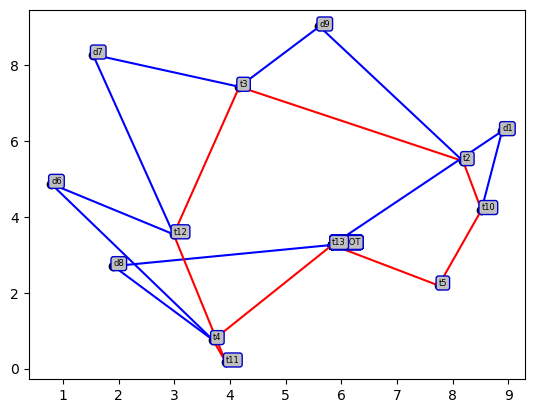

[INFO] Exported: truck_times, drone_times, drone_mission, label (path-only), tsp_used
------------------------------------------------------------------------------------------------------------------------


In [1336]:
# NOTE
# FINAL VERSION UPDATED WITH FIRST 12-CUSTOMER RUN (AT 3/17/2026)
# LABEL PART WAS UPDATED 
# ================================
# TSP-D base model (requires ready tT/dT)
# Greedy partition (MakeFly/PushLeft/PushRight)
# Schedule + True Makespan (truck path + waits + SL + SR)
# Linearized labels along 0 -> ... -> end depot
# ================================

import sys, time as _time
import numpy as _np
import numpy
from collections import OrderedDict, defaultdict
from typing import Dict, Tuple, List

# ---------- You provide ----------
# V1 : List[List[float]]
# tT : dict {(i,j): truck travel time}
# dT : dict {(i,j): drone travel time}
# optional: tsp1 initial tour (Concorde)
# ---------------------------------

# ---------- Reproducibility ----------
SEED = 1923 #SSSS
SAMPLE_RATIO = 0.3  # for tour local search (sampled neighbors)

# ---------- Service times ----------
SL = 1.0   # launch service (0 at depot)
SR = 1.0   # recovery service at rendezvous

# ---------- Mission energy/feasibility limit (time) ----------
E_LIMIT = 20.0 #for 12-customer instances

# ---------- Optional drawing ----------
DRAW_ROUTES = True
sys.path.append("../")
try:
    from route_drawing import drawing_routes_using_labels
except Exception:
    drawing_routes_using_labels = None

try:
    from solving_TSP import two_opt_for_TSP
except Exception:
    def two_opt_for_TSP(V):
        return list(range(len(V)))

# =========================================================
# Travel-time accessors (REQUIRES ready tT/dT)
# =========================================================
def _ensure_travel_times():
    global tT, dT
    assert isinstance(tT, dict) and isinstance(dT, dict), \
        "You must predefine ready dicts tT and dT before running."

def truck_time(i, j):  # symmetric lookup ok
    try: return tT[(i,j)]
    except KeyError: return tT[(j,i)]

def drone_time(i, j):
    try: return dT[(i,j)]
    except KeyError: return dT[(j,i)]

# =========================================================
# Greedy partition: MakeFly / PushLeft / PushRight
# =========================================================
def greedy_partitioning(tsp, depot, V1):
    """
    Build TSP-D partition on a fixed truck-only TSP tour 'tsp'.
    Returns: (tspd_total, label, drone_nodes, drone_mission, operation, flyop, driveop)
    """
    _ensure_travel_times()
    n = len(tsp)
    end_depot = len(V1) - 1
    ND =  {4, 5, depot, end_depot} # disallow depots as drone-only customers 12-customer instances
    #ND = {depot, end_depot}  # disallow depots as drone-only customers

    label = {}
    operation, flyop, driveop = {}, {}, {}
    drone_mission = {}  # d -> (L,R)

    # base truck tour cost around cycle
    tsptotal = 0.0
    for k in range(n):
        i, j = tsp[k], tsp[(k+1)%n]
        label[i] = 'simple'
        tsptotal += truck_time(i, j)
    tspdtotal = tsptotal

    while 'simple' in label.values():
        ms = []

        # 1) Make Fly
        for i in range(n):
            saving = -float('inf')
            u = tsp[i]
            if label[u] == 'simple' and u not in ND:
                L = tsp[i-1]
                R = tsp[(i+1)%n]
                fly_time = drone_time(L,u) + drone_time(u,R)
                if fly_time + SL <= E_LIMIT and truck_time(L,R) <= E_LIMIT:
                    base = truck_time(L,u) + truck_time(u,R)
                    alt  = max(fly_time, truck_time(L,R) + SL + SR)
                    saving = base - alt
            ms.append(saving)

        # 2) Push Left
        for i in range(n):
            saving = -float('inf')
            cur = tsp[i]
            prev = tsp[i-1]
            if label.get(prev) == 'combined' and prev != depot and label.get(cur) == 'simple':
                j = i - 2
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[j-1]] == 'combined' and dronenode is not None:
                        d  = tsp[dronenode]
                        L  = tsp[j-1]
                        R_old = prev
                        R_new = cur
                        base_key = (d,L,R_old)
                        if (d not in ND) and (base_key in operation) and (base_key in driveop):
                            fly_new   = drone_time(L,d) + drone_time(d,R_new)
                            drive_new = driveop[base_key] + truck_time(R_old, R_new)
                            if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                saving = truck_time(R_old, R_new) + operation[base_key] - \
                                         max(fly_new, drive_new + SR)
                        break
                    j -= 1
            ms.append(saving)

        # 3) Push Right
        for i in range(n):
            saving = -float('inf')
            cur = tsp[i]
            nxt = tsp[(i+1)%n]
            if label.get(nxt) == 'combined' and nxt != depot and label.get(cur) == 'simple':
                j = (i+2) % n
                dronenode = None
                while label[tsp[j]] != 'combined':
                    if label[tsp[j]] == 'drone':
                        dronenode = j
                    if label[tsp[(j+1)%n]] == 'combined' and dronenode is not None:
                        d = tsp[dronenode]
                        L_old = nxt
                        R_new = tsp[(j+1)%n]
                        base_key = (d, L_old, R_new)
                        if (d not in ND) and (base_key in operation) and (base_key in driveop):
                            fly_new   = drone_time(cur,d) + drone_time(d,R_new)
                            drive_new = driveop[base_key] + truck_time(cur, L_old)
                            if fly_new + SL <= E_LIMIT and drive_new <= E_LIMIT:
                                saving = truck_time(cur, L_old) + operation[base_key] - \
                                         max(fly_new, drive_new + SR)
                        break
                    j = (j+1) % n
            ms.append(saving)

        idx = int(numpy.argmax(ms))
        if ms[idx] <= 0:
            for u in label:
                if label[u] == 'simple':
                    label[u] = 'combined'
            break

        tspdtotal -= ms[idx]
        block = idx // n
        pos   = idx %  n

        if block == 0:
            # Make Fly
            d = tsp[pos]
            L = tsp[pos-1]
            R = tsp[(pos+1)%n]
            label[d] = 'drone'
            label[L] = 'combined'
            label[R] = 'combined'
            flyop[(d,L,R)]   = drone_time(L,d) + drone_time(d,R)
            driveop[(d,L,R)] = truck_time(L,R)
            operation[(d,L,R)] = max(flyop[(d,L,R)], driveop[(d,L,R)])
            drone_mission[d] = (L,R)

        elif block == 1:
            # Push Left
            label[tsp[pos]] = 'combined'
            label[tsp[(pos-1)%n]] = 'truck'
            j = (pos-2) % n
            dronenode = None
            while label[tsp[j]] != 'combined':
                if label[tsp[j]] == 'drone':
                    dronenode = j
                if label[tsp[j-1]] == 'combined' and dronenode is not None:
                    d = tsp[dronenode]
                    L = tsp[j-1]
                    R_new  = tsp[pos]
                    prev_R = tsp[(pos-1)%n]
                    flyop[(d,L,R_new)]   = drone_time(L,d) + drone_time(d,R_new)
                    driveop[(d,L,R_new)] = driveop[(d,L,prev_R)] + truck_time(prev_R, R_new)
                    operation[(d,L,R_new)] = max(flyop[(d,L,R_new)], driveop[(d,L,R_new)])
                    drone_mission[d] = (L,R_new)
                    break
                j -= 1

        else:
            # Push Right
            label[tsp[pos]] = 'combined'
            label[tsp[(pos+1)%n]] = 'truck'
            j = (pos+2) % n
            dronenode = None
            while label[tsp[j]] != 'combined':
                if label[tsp[j]] == 'drone':
                    dronenode = j
                if label[tsp[(j+1)%n]] == 'combined' and dronenode is not None:
                    d = tsp[dronenode]
                    L_new = tsp[pos]
                    R = tsp[(j+1)%n]
                    next_L = tsp[(pos+1)%n]
                    flyop[(d,L_new,R)]   = drone_time(L_new,d) + drone_time(d,R)
                    driveop[(d,L_new,R)] = driveop[(d,next_L,R)] + truck_time(L_new, next_L)
                    operation[(d,L_new,R)] = max(flyop[(d,L_new,R)], driveop[(d,L_new,R)])
                    drone_mission[d] = (L_new, R)
                    break
                j = (j+1) % n

    dset = {u for u in label if label[u] == 'drone'}
    return tspdtotal, label, dset, drone_mission, operation, flyop, driveop

# =========================================================
# Schedule (truck_times, drone_times)
# =========================================================
def compute_arrival_times(tsp, depot, label, drone_mission):
    truck_path = [u for u in tsp if label.get(u,'combined') != 'drone']
    missions_by_L = defaultdict(list)
    missions_by_R = defaultdict(list)
    for d,(L,R) in drone_mission.items():
        missions_by_L[L].append(d)
        missions_by_R[R].append(d)

    truck_times, drone_times = {}, {}
    drone_R_time = {}

    if not truck_path:
        return truck_times, drone_times

    for u in truck_path:
        drone_times[u] = [0.0, 0.0]

    t = 0.0
    start = truck_path[0]
    truck_times[start] = [t, t]

    # launches at start
    if start in missions_by_L:
        for d in missions_by_L[start]:
            L = start; R = drone_mission[d][1]
            sl = 0.0 if L == depot else SL
            t += sl
            truck_times[L][1] = t
            arrL = truck_times[L][0]
            drone_times[L] = [arrL, t]
            d_arr = t + drone_time(L,d)
            R_arr = d_arr + drone_time(d,R)
            drone_times[d] = [d_arr, d_arr]
            drone_R_time[d] = R_arr

    # traverse
    for k in range(1, len(truck_path)):
        prev = truck_path[k-1]
        cur  = truck_path[k]
        t += truck_time(prev, cur)
        truck_times[cur] = [t, t]

        # recoveries
        if cur in missions_by_R:
            latest = max(drone_R_time[d] for d in missions_by_R[cur] if d in drone_R_time) \
                     if missions_by_R[cur] else t
            if latest > t:
                t = latest
            t += SR
            truck_times[cur][1] = t
            for d in missions_by_R[cur]:
                if d in drone_R_time:
                    drone_times[cur] = [drone_R_time[d], t]

        # launches at cur
        if cur in missions_by_L:
            for d in missions_by_L[cur]:
                L = cur; R = drone_mission[d][1]
                sl = 0.0 if L == depot else SL
                t += sl
                truck_times[L][1] = t
                arrL = truck_times[L][0]
                if L not in drone_times:
                    drone_times[L] = [arrL, t]
                else:
                    if drone_times[L][0] == 0.0:
                        drone_times[L][0] = arrL
                    drone_times[L][1] = max(drone_times[L][1], t)
                d_arr = t + drone_time(L,d)
                R_arr = d_arr + drone_time(d,R)
                drone_times[d] = [d_arr, d_arr]
                drone_R_time[d] = R_arr

    return truck_times, drone_times

# =========================================================
# True makespan (your formula) helpers
# =========================================================
def linearize_between_depots(tour, start_depot, end_depot):
    """Linearize the cycle to  start_depot -> ... -> first hit of end_depot."""
    n = len(tour)
    i = tour.index(start_depot)
    path = [start_depot]
    j = (i + 1) % n
    while tour[j] != end_depot:
        path.append(tour[j])
        j = (j + 1) % n
    path.append(end_depot)
    return path

def truck_path_time_0_to_end(tsp, label, start_depot, end_depot):
    truck_cycle = [u for u in tsp if label.get(u,'combined') != 'drone']
    path = linearize_between_depots(truck_cycle, start_depot, end_depot)
    total = 0.0
    for i in range(1, len(path)):
        total += truck_time(path[i-1], path[i])
    return total, path

def compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=None):
    """
    Return {R: truck wait (sec)} at rendezvous R (excludes SR).
    If 'depot' is given, missions with R == depot are ignored (no waiting at start depot).
    """
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        if depot is not None and R == depot:
            continue
        missions_by_R[R].append((d, L))

    wait = {}
    for R, pairs in missions_by_R.items():
        if R not in truck_times:
            continue
        t_truck_arr = truck_times[R][0]
        latest_R_arr = float("-inf")
        for d, L in pairs:
            tL = drone_times[L][1]
            d_arr = tL + drone_time(L,d)
            R_arr = d_arr + drone_time(d,R)
            latest_R_arr = max(latest_R_arr, R_arr)
        wait[R] = max(0.0, latest_R_arr - t_truck_arr)
    return wait

def count_launches_excluding_depot(drone_mission, depot):
    return sum(1 for d,(L,_) in drone_mission.items() if L != depot)

def true_makespan_from_formula(tsp, label, truck_times, drone_times, drone_mission, depot, end_depot):
    truck_travel_sum, _truck_path = truck_path_time_0_to_end(tsp, label, depot, end_depot)
    waits = compute_truck_waiting_times(truck_times, drone_mission, drone_times, depot=depot)
    total_wait = sum(waits.values())
    launches_excl_depot = count_launches_excluding_depot(drone_mission, depot)
    recoveries = len(drone_mission)
    return truck_travel_sum + total_wait + SL*launches_excl_depot + SR*recoveries

# =========================================================
# Tour LS (sampled neighbors)
# =========================================================
def two_points_move(route, i, j):
    r = route[:]; r[i], r[j] = r[j], r[i]; return r

def two_opt_move(route, i, j):
    if i > j: i, j = j, i
    return route[:i+1] + route[i+1:j+1][::-1] + route[j+1:]

def one_point_move(route, i, j):
    if i == j: return route[:]
    r = route[:]; node = r.pop(i); r.insert(j, node); return r

def _rotate_to_depot(route, depot):
    if route[0] == depot: return route
    k = route.index(depot); return route[k:] + route[:k]

def improve_all(heuristic, route_in, depot, V1, sample_ratio=SAMPLE_RATIO, rng_seed=SEED):
    _ensure_travel_times()
    n = len(route_in)
    route_best = _rotate_to_depot(list(route_in), depot)
    cache = {}
    def eval_route(rt):
        key = tuple(rt)
        if key in cache: return cache[key]
        rt0 = _rotate_to_depot(rt, depot)
        val = heuristic(rt0, depot, V1)[0]
        cache[key] = val
        return val
    f_best = eval_route(route_best)
    if rng_seed is not None:
        _np.random.seed(rng_seed)
    all_pairs = [(i,j) for i in range(n) for j in range(n) if j != i]
    m = len(all_pairs); k = max(1, int(round(sample_ratio*m)))
    improved = True
    while improved:
        improved = False
        idxs = _np.random.choice(m, size=k, replace=False)
        best_neighbor, best_cost = None, f_best
        for p in idxs:
            i,j = all_pairs[p]
            for mv in (two_points_move, two_opt_move, one_point_move):
                cand = _rotate_to_depot(mv(route_best, i, j), depot)
                fc   = eval_route(cand)
                if fc < best_cost - 1e-12:
                    best_neighbor, best_cost = cand, fc
        if best_neighbor is not None:
            route_best, f_best, improved = best_neighbor, best_cost, True
    return route_best

# =========================================================
# Wrapper: seed tour -> LS -> partition -> schedule
# =========================================================
def two_opt_greedy_partitioning_all_improved(V1, depot, tsp_init=None):
    _ensure_travel_times()
    n = len(V1)
    if tsp_init is not None:
        tsp_seed = list(tsp_init)
    else:
        try:
            from __main__ import tsp1
            tsp_seed = list(tsp1)
            print("[INFO] Using Concorde tour (tsp1) as initial tour.")
        except Exception:
            tsp_seed = two_opt_for_TSP(V1)
            print("[INFO] Concorde tsp1 not found; using 2-opt seed.")
    if len(tsp_seed) != n or sorted(tsp_seed) != list(range(n)):
        raise ValueError("Initial tour must be a permutation of 0..n-1 with length len(V1).")
    tsp_seed = _rotate_to_depot(tsp_seed, depot)
    tsp_best = improve_all(greedy_partitioning, tsp_seed, depot, V1,
                           sample_ratio=SAMPLE_RATIO, rng_seed=SEED)
    total_cost, label, drone_nodes, drone_mission, operation, flyop, driveop = greedy_partitioning(
        tsp_best, depot, V1
    )
    truck_times, drone_times = compute_arrival_times(tsp_best, depot, label, drone_mission)
    return (total_cost, label, drone_nodes, drone_mission, truck_times, drone_times), tsp_best

# =========================================================
# MAIN
# =========================================================
def main():
    global V1  # provided externally
    _ensure_travel_times()  # <- requires your tT/dT
    depot = 0
    END_DEPOT = len(V1) - 1
    _np.random.seed(SEED)

    print("-" * 120)
    try:
        from __main__ import tsp1
        tsp_init = tsp1
    except Exception:
        tsp_init = None

    start = _time.time()
    (total_cost,
     label,
     drone_nodes,
     drone_mission,
     truck_times,
     drone_times), tsp_used = two_opt_greedy_partitioning_all_improved(
        V1, depot, tsp_init=tsp_init
    )
    end = _time.time()

    # True makespan (your formula)
    f_true = true_makespan_from_formula(
        tsp_used, label, truck_times, drone_times, drone_mission, depot, END_DEPOT
    )

    print(f"Running time: {end-start:.4f} sec")
    print(f"Heuristic TSP-D cost (truck - ops): {total_cost:.4f}")
    print(f"True makespan from schedule: {f_true:.4f}")
    print(f"# drone customers: {len(drone_nodes)}")
    print("SEED is:", SEED)
    print("SAMPLE_RATIO is:", SAMPLE_RATIO)

    # Show labels along 0 -> ... -> END_DEPOT (PATH-ONLY VERSION)
    tsp_path_0_to_end = linearize_between_depots(tsp_used, depot, END_DEPOT)

    print("Labels along *path* (0 -> ... -> end):")
    for u in tsp_path_0_to_end:
        print(f"{u}: {label[u]}")

    # ALSO show full label dictionary (for debugging clarity)
    print("\nFull label dictionary (entire tour):")
    print(label)

    # Optional drawing
    if DRAW_ROUTES and drawing_routes_using_labels is not None:
        try:
            drawing_routes_using_labels(V1, label, depot, drone_nodes)
        except Exception as e:
            print(f"(Route drawing skipped) {e}")

    # Export for later (e.g., your disruption code)
    globals()["truck_times"] = truck_times
    globals()["drone_times"] = drone_times
    globals()["drone_mission"] = drone_mission

    # IMPORTANT CHANGE: export path-only labels so they match the 0->...->END path
    #globals()["label"] = dict(label_path_only) #previous one
    globals()["label"] = label  # KEEP FULL LABELS

    globals()["tsp_used"] = tsp_used
    print("[INFO] Exported: truck_times, drone_times, drone_mission, label (path-only), tsp_used")
    print("-" * 120)

if __name__ == "__main__":
    main()


In [1338]:
#1111
label

{0: 'combined',
 8: 'drone',
 4: 'combined',
 6: 'drone',
 11: 'truck',
 12: 'combined',
 7: 'drone',
 3: 'combined',
 9: 'drone',
 2: 'combined',
 10: 'combined',
 5: 'truck',
 13: 'truck',
 1: 'drone'}

In [1341]:
#just ran 
#

In [1343]:
truck_times

{0: [0.0, 0.0],
 4: [11.159999999999998, 13.342907465345103],
 11: [15.310907465345103, 15.310907465345103],
 12: [25.678907465345105, 28.396908608251827],
 3: [40.56490860825183, 43.63251438008268],
 2: [57.98451438008268, 58.98451438008268],
 10: [62.87251438008268, 63.87251438008268],
 5: [70.49651438008267, 70.49651438008267],
 13: [77.64851438008267, 77.64851438008267]}

In [1345]:
drone_times

{0: [0.0, 0.0],
 4: [11.342907465345103, 13.342907465345103],
 11: [0.0, 0.0],
 12: [26.396908608251827, 28.396908608251827],
 3: [41.63251438008268, 43.63251438008268],
 2: [54.833063515812775, 58.98451438008268],
 10: [62.87251438008268, 63.87251438008268],
 5: [0.0, 0.0],
 13: [0.0, 0.0],
 8: [6.8051960939822305, 6.8051960939822305],
 6: [21.98986044997312, 21.98986044997312],
 7: [36.894320459119434, 36.894320459119434],
 9: [47.3099269576032, 47.3099269576032],
 1: [67.49420414243035, 67.49420414243035]}

In [1350]:
####YOU CAN SKIP THIS ADDITIONAL 
####YOU CAN SKIP THIS ADDITIONAL 
from collections import defaultdict

def compute_truck_waiting_times(truck_times,
                                drone_mission,
                                drone_times,
                                depot=None):
    """
    Return {R: waiting_time_of_truck_at_R} for all rendezvous nodes R.

    Waiting time excludes the recovery service time SR; it's just the idle time
    before recovery starts (i.e., how long the truck arrives earlier than the drone).

    Parameters
    ----------
    truck_times : dict
        {i: (arrival_time, departure_time)} for truck visits.
    drone_mission : dict
        {d: (L, R)} where L = launch node, d = drone customer, R = rendezvous node.
    drone_times : dict
        {i: (arrival_time, departure_time)} for drone at launch nodes, etc.
    depot : int or None
        Node index of the depot. If given, ANY mission with R == depot is ignored
        (depot is not treated as a rendezvous for waiting-time purposes).
    """
    # group missions by rendezvous R
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        # Skip depot as a rendezvous node if specified
        if depot is not None and R == depot:
            continue
        missions_by_R[R].append((d, L))

    wait = {}

    for R, pairs in missions_by_R.items():
        # If truck never visits this R (shouldn't happen in a valid solution), skip it
        if R not in truck_times:
            continue

        # truck arrival at R
        truck_arrival_R = truck_times[R][0]

        # latest drone arrival among missions ending at R
        latest_drone_arrival_R = float("-inf")
        for d, L in pairs:
            # time drone leaves L
            launch_t = drone_times[L][1]

            # drone arrival at d
            d_arr = launch_t + drone_time(L, d)

            # then drone flies from d to R
            R_arr = d_arr + drone_time(d, R)

            if R_arr > latest_drone_arrival_R:
                latest_drone_arrival_R = R_arr

        # truck waits only if truck_arrival_R is earlier
        wait[R] = max(0.0, latest_drone_arrival_R - truck_arrival_R)

    return wait
#############    
rendezvous_wait = compute_truck_waiting_times(
    truck_times,
    drone_mission,
    drone_times,
    depot=0      # your starting depot node index
)

print("Truck waiting time at rendezvous nodes (seconds):")
total_wait = sum(rendezvous_wait.values())
print(rendezvous_wait, total_wait)



Truck waiting time at rendezvous nodes (seconds):
{12: 0.7180011429067221, 3: 1.0676057718308556, 4: 0.18290746534510482, 2: 0.0} 1.9685143800826825


In [1356]:
'''
import math
from typing import Dict, Tuple, List, Any

EPS = 1e-12

# ============================================
# Basic geometry helpers
# ============================================
def _coords(V1: List[List[float]], node: int) -> Tuple[float, float]:
    x, y = V1[node]
    return float(x), float(y)

def _lininterp(p: Tuple[float,float], q: Tuple[float,float], frac: float) -> Tuple[float,float]:
    return (p[0] + frac*(q[0]-p[0]), p[1] + frac*(q[1]-p[1]))

# ============================================
# Truck status at time t
# ============================================
def _truck_status_at(
    t: float,
    truck_times: Dict[int, List[float]],
    V1: List[List[float]]
) -> Dict[str, Any]:
    """
    Return:
      - where: 'at_node' | 'between_nodes' | 'before_start' | 'after_end' | 'unknown'
      - xy: (x, y) position of truck
      - plus other fields depending on 'where'
    """
    seq = sorted(truck_times.items(), key=lambda kv: kv[1][0])  # [(node, [arr, dep]), ...]
    if not seq:
        return {"where": "unknown"}

    nodes = [n for n, _ in seq]
    arrs  = [times[0] for _, times in seq]
    deps  = [times[1] for _, times in seq]

    # 1) At some node (including waiting/service interval)
    for node, (arr, dep) in seq:
        if arr - EPS <= t <= dep + EPS:
            xy = _coords(V1, node)
            return {"where": "at_node", "node": node, "xy": xy}

    # 2) Before first / after last
    if t < arrs[0] - EPS:
        n0 = nodes[0]
        return {"where": "before_start", "next_node": n0, "xy": _coords(V1, n0)}

    if t > arrs[-1] + EPS:
        nL = nodes[-1]
        return {"where": "after_end", "last_node": nL, "xy": _coords(V1, nL)}

    # 3) Between two arrival times → interpolate along edge
    for k in range(1, len(seq)):
        prev_node, (arr_prev, _) = seq[k-1]
        cur_node,  (arr_cur,  _) = seq[k]
        if arr_prev + EPS < t < arr_cur - EPS and arr_cur > arr_prev + EPS:
            frac = (t - arr_prev) / (arr_cur - arr_prev)
            p = _coords(V1, prev_node)
            q = _coords(V1, cur_node)
            xy = _lininterp(p, q, frac)
            return {
                "where": "between_nodes",
                "edge": (prev_node, cur_node),
                "frac": frac,
                "xy": xy
            }

    # Fallback
    return {"where": "unknown"}

# ============================================
# Drone status at time t (single-drone assumption)
# ============================================
def _drone_status_at(
    t: float,
    drone_mission: Dict[int, Tuple[int,int]],
    drone_times: Dict[int, List[float]],
    V1: List[List[float]]
) -> Dict[str, Any]:
    """
    Single-drone assumption: if a mission is active at time t (in the air), report it.
    If none are airborne, report the "closest" mission in ground state (pre-launch or at/after R).
    """
    active = None

    # Check if drone is airborne on any mission (L -> d or d -> R)
    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            continue

        tL = drone_times[L][1]   # launch (departure from L)
        tD = drone_times[d][0]   # arrival at d (service instantaneous)
        tR = drone_times[R][0]   # arrival at R

        # L -> d leg
        if tL + EPS < t < tD - EPS and tD > tL + EPS:
            frac = (t - tL) / (tD - tL)
            p = _coords(V1, L)
            q = _coords(V1, d)
            xy = _lininterp(p, q, frac)
            active = {
                "where": "in_air",
                "segment": (L, d),
                "phase": "L_to_d",
                "frac": frac,
                "xy": xy,
                "mission_d": d
            }
            break

        # At d (service)
        if abs(t - tD) <= EPS:
            xy = _coords(V1, d)
            active = {
                "where": "at_node",
                "node": d,
                "phase": "service_at_d",
                "xy": xy,
                "mission_d": d
            }
            break

        # d -> R leg
        if tD + EPS < t < tR - EPS and tR > tD + EPS:
            frac = (t - tD) / (tR - tD)
            p = _coords(V1, d)
            q = _coords(V1, R)
            xy = _lininterp(p, q, frac)
            active = {
                "where": "in_air",
                "segment": (d, R),
                "phase": "d_to_R",
                "frac": frac,
                "xy": xy,
                "mission_d": d
            }
            break

    if active is not None:
        return active

    # If not in air, choose a "closest" ground state (pre-launch or at/after R)
    best = None
    best_gap = float("inf")

    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            continue

        tL = drone_times[L][1]
        tD = drone_times[d][0]
        tR = drone_times[R][0]

        if t <= tL + EPS:
            # Not launched yet
            gap = abs(tL - t)
            cand = {
                "where": "ground",
                "phase": "pre_launch",
                "at_node": L,
                "xy": _coords(V1, L),
                "mission_d": d
            }
        elif t >= tR - EPS:
            # Already recovered
            gap = abs(t - tR)
            cand = {
                "where": "ground",
                "phase": "at_or_after_R",
                "at_node": R,
                "xy": _coords(V1, R),
                "mission_d": d
            }
        else:
            # (exactly at d handled above)
            continue

        if gap < best_gap:
            best_gap = gap
            best = cand

    return best if best is not None else {"where": "unknown"}

# ============================================
# Node sets (visited / remaining)
# ============================================
def remaining_truck_nodes_after(
    t: float,
    truck_times: Dict[int, List[float]]
) -> List[int]:
    """Return future truck nodes (original ids) whose arrival time is strictly > t, in visit order."""
    seq = sorted(truck_times.items(), key=lambda kv: kv[1][0])
    return [node for node, (arr, _) in seq if arr > t + EPS]

def visited_truck_nodes_up_to(
    t: float,
    truck_times: Dict[int, List[float]]
) -> List[int]:
    """Return truck nodes whose arrival time is <= t, in visit order."""
    seq = sorted(truck_times.items(), key=lambda kv: kv[1][0])
    return [node for node, (arr, _) in seq if arr <= t + EPS]

def visited_drone_nodes_up_to(
    t: float,
    drone_mission: Dict[int, Tuple[int,int]],
    drone_times: Dict[int, List[float]]
) -> List[int]:
    """
    Return drone customer nodes d that have been served by time t
    (drone arrival at d <= t).
    """
    visited = []
    for d, (L, R) in drone_mission.items():
        if d not in drone_times:
            continue
        tD = drone_times[d][0]
        if tD <= t + EPS:
            visited.append(d)
    return visited

# ============================================
# Main snapshot function
# ============================================
def snapshot_after_disruption(
    t0: float,
    V1: List[List[float]],
    tsp_used: List[int],               # not strictly needed but kept for interface
    truck_times: Dict[int, List[float]],
    drone_times: Dict[int, List[float]],
    drone_mission: Dict[int, Tuple[int,int]]
) -> Dict[str, Any]:
    """
    1) Determine visited truck nodes, visited drone nodes, remaining nodes, remaining truck nodes.
    2) Report truck state at time t0.
    3) Report drone state at time t0.
    """
    # 1a) visited by truck up to t0
    visited_truck = visited_truck_nodes_up_to(t0, truck_times)

    # 1b) visited by drone up to t0
    visited_drone = visited_drone_nodes_up_to(t0, drone_mission, drone_times)

    # 1c) remaining truck nodes (future visits)
    remaining_truck = remaining_truck_nodes_after(t0, truck_times)

    # 1d) remaining nodes overall (not visited by truck or drone), excluding original depot 0
    n_nodes = len(V1)
    visited_union = set(visited_truck) | set(visited_drone)
    remaining_all = [
        u for u in range(n_nodes)
        if (u not in visited_union and u != 0)
    ]
    remaining_all = sorted(remaining_all)

    # 2) truck position
    truck_state = _truck_status_at(t0, truck_times, V1)

    # 3) drone position
    drone_state = _drone_status_at(t0, drone_mission, drone_times, V1)

    # -------- Pretty print snapshot ----------
    print(f"--- Disruption snapshot at t = {t0} ---")
    print("Visited TRUCK nodes up to t0 (including depot):", visited_truck)
    print("Visited DRONE customer nodes up to t0:", visited_drone)
    print("Remaining nodes (not visited by truck or drone, depot 0 removed):", remaining_all)
    print("Remaining TRUCK nodes (future truck visits):", remaining_truck)

    # Truck report
    if truck_state["where"] == "at_node":
        print(f"Truck is at node {truck_state['node']} at {truck_state['xy']}")
    elif truck_state["where"] == "between_nodes":
        u, v = truck_state["edge"]
        print(f"Truck is between node {u} and node {v} at {truck_state['xy']}  "
              f"(frac={truck_state['frac']:.3f})")
    elif truck_state["where"] == "before_start":
        print(f"Truck has not started; next node {truck_state['next_node']} at {truck_state['xy']}")
    elif truck_state["where"] == "after_end":
        print(f"Truck has finished; last node {truck_state['last_node']} at {truck_state['xy']}")
    else:
        print("Truck state: unknown")

    # Drone report
    if drone_state["where"] == "in_air":
        seg = drone_state["segment"]
        phase = drone_state["phase"]
        print(f"Drone is IN AIR on segment {seg[0]} → {seg[1]} ({phase}); "
              f"emergency-landing location {drone_state['xy']}")
    elif drone_state["where"] == "at_node":
        print(f"Drone is at node {drone_state['node']} ({drone_state['phase']}); "
              f"location {drone_state['xy']}")
    elif drone_state["where"] == "ground":
        print(f"Drone is on the ground: {drone_state['phase']} at node "
              f"{drone_state['at_node']} at {drone_state['xy']}")
    else:
        print("Drone state: unknown")

    return {
        "visited_truck_nodes": visited_truck,
        "visited_drone_nodes": visited_drone,
        "remaining_nodes": remaining_all,
        "remaining_truck_nodes": remaining_truck,
        "truck_state": truck_state,
        "drone_state": drone_state,
    }

# ============================================
# Build reduced instance after disruption (with DRN)
# ============================================
TRUCK_SPEED = 25.0  # mph (or consistent units)
DRONE_SPEED = 35.0  # mph

def build_reduced_instance_after_disruption(
    t0: float,
    V1: List[List[float]],
    tsp_used: List[int],
    truck_times: Dict[int, List[float]],
    drone_times: Dict[int, List[float]],
    drone_mission: Dict[int, Tuple[int,int]],
) -> Dict[str, Any]:
    """
    - Uses snapshot_after_disruption to get current state.
    - Creates a reduced instance:

        * New truck node id: 0 at current truck location.
        * Remaining customer nodes (original ids) from snapshot["remaining_nodes"].
        * PLUS a DRN (drone rescue node):

            - If drone is IN AIR:
                - DRN is a NEW node with coords = emergency landing location.
                - DRN id = min(removed_truck ∪ removed_drone \ {0}).
                - If that set is empty, DRN id = len(V1).

            - If drone is at a node (service_at_d OR ground at L/R):
                - DRN is that node id (existing).
                - Ensure DRN is included in remaining nodes.

        * Builds tT2, dT2 over these nodes:
            - Truck: Manhattan distance / TRUCK_SPEED.
            - Drone: Euclidean distance / DRONE_SPEED.

    Returns dict with:
      - V2_coords: dict[orig_id] -> (x,y) with new truck at id 0
      - tT2, dT2: dict[(orig_i,orig_j)] -> travel time
      - node_order: list of orig_ids
      - new_index_of: mapping orig_id -> new_index
      - V2_list, tT2_list, dT2_list (0..n-1 based)
      - DRN: the drone rescue node id (orig id in this reduced instance)
      - DRN_new_index: its index in node_order
    """
    # 1) Snapshot
    snap = snapshot_after_disruption(
        t0, V1, tsp_used, truck_times, drone_times, drone_mission
    )

    remaining_nodes = list(snap["remaining_nodes"])   # original ids (excluding old depot 0)
    truck_state = snap["truck_state"]
    drone_state = snap["drone_state"]
    visited_truck = snap["visited_truck_nodes"]
    visited_drone = snap["visited_drone_nodes"]

    if truck_state["where"] not in ("at_node", "between_nodes"):
        raise RuntimeError(f"Unexpected truck_state at t0={t0}: {truck_state}")

    # 2) Determine DRN (drone rescue node) and its coordinates
    DRN = None
    DRN_xy = None

    if drone_state["where"] == "in_air":
        # New artificial rescue node at emergency landing location
        DRN_xy = drone_state["xy"]

        # "Removed" = visited truck + visited drone (everything not in remaining_all)
        removed = (set(visited_truck) | set(visited_drone)) - {0}
        if removed:
            DRN = min(removed)
        else:
            DRN = len(V1)  # fallback

        # Ensure DRN is listed among remaining nodes
        if DRN not in remaining_nodes:
            remaining_nodes.append(DRN)

    elif drone_state["where"] == "at_node":
        # DRN is the current node d
        DRN = drone_state["node"]
        DRN_xy = drone_state["xy"]
        if DRN not in remaining_nodes and DRN != 0:
            remaining_nodes.append(DRN)

    elif drone_state["where"] == "ground":
        # DRN is L or R (at_node field)
        DRN = drone_state["at_node"]
        DRN_xy = drone_state["xy"]
        if DRN not in remaining_nodes and DRN != 0:
            remaining_nodes.append(DRN)

    # Sort and deduplicate
    remaining_nodes = sorted(set(remaining_nodes))

    # 3) New coordinates dictionary (keyed by original ids, plus 0 for truck)
    V2_coords: Dict[int, Tuple[float, float]] = {}

    # 3a) new truck location becomes node 0
    truck_xy = truck_state["xy"]
    V2_coords[0] = (float(truck_xy[0]), float(truck_xy[1]))

    # 3b) add all remaining nodes with their original coordinates
    for u in remaining_nodes:
        # Safety: if u is beyond original V1 (only possible in weird fallbacks), skip
        if u < len(V1):
            x, y = V1[u]
            V2_coords[u] = (float(x), float(y))

    # 3c) override DRN coords if we created an artificial landing node
    if DRN is not None and DRN_xy is not None:
        V2_coords[DRN] = (float(DRN_xy[0]), float(DRN_xy[1]))

    # 4) Build travel-time dictionaries on these nodes (truck + drone)
    nodes2 = sorted(V2_coords.keys())  # [0, ...]
    tT2: Dict[Tuple[int,int], float] = {}
    dT2: Dict[Tuple[int,int], float] = {}

    for i in nodes2:
        xi, yi = V2_coords[i]
        for j in nodes2:
            if i == j:
                continue
            xj, yj = V2_coords[j]

            # Truck: Manhattan distance → time
            manhattan_dist = abs(xi - xj) + abs(yi - yj)
            truck_time_ij = manhattan_dist / TRUCK_SPEED

            # Drone: Euclidean distance → time
            euclid_dist = math.hypot(xi - xj, yi - yj)
            drone_time_ij = euclid_dist / DRONE_SPEED

            tT2[(i, j)] = truck_time_ij
            dT2[(i, j)] = drone_time_ij

    # 5) Optional: build 0..n-1 indexing for solvers
    node_order: List[int] = nodes2          # new_index -> original_id
    new_index_of: Dict[int, int] = {orig: k for k, orig in enumerate(node_order)}
    V2_list: List[Tuple[float, float]] = [V2_coords[orig] for orig in node_order]

    tT2_list = {}
    dT2_list = {}
    for i_orig in nodes2:
        i_new = new_index_of[i_orig]
        for j_orig in nodes2:
            if i_orig == j_orig:
                continue
            j_new = new_index_of[j_orig]
            tT2_list[(i_new, j_new)] = tT2[(i_orig, j_orig)]
            dT2_list[(i_new, j_new)] = dT2[(i_orig, j_orig)]

    # DRN’s index in 0..n-1 representation (if any)
    DRN_new_index = None
    if DRN is not None and DRN in new_index_of:
        DRN_new_index = new_index_of[DRN]

    # 6) Summary print
    print("\n=== Reduced instance after disruption ===")
    print("New truck node id: 0, location:", V2_coords[0])
    print("Number of remaining customer/DRN nodes (excluding new truck 0):", len(V2_coords) - 1)
    print("Total nodes in V2 (including new truck 0):", len(V2_coords))
    if DRN is not None:
        print(f"DRN (drone rescue node) original id: {DRN}, coords: {V2_coords[DRN]}")
        print("DRN new index in 0..n-1 representation:", DRN_new_index)
    else:
        print("DRN (drone rescue node): None")

    # Uncomment this if you want to see the full key set for debugging:
    # print("V2_coords keys:", sorted(V2_coords.keys()))

    return {
        "V2_coords": V2_coords,
        "tT2": tT2,
        "dT2": dT2,
        "node_order": node_order,
        "new_index_of": new_index_of,
        "V2_list": V2_list,
        "tT2_list": tT2_list,
        "dT2_list": dT2_list,
        "DRN": DRN,
        "DRN_new_index": DRN_new_index,
        "snapshot": snap,  # include full snapshot for convenience
    }

# ===== Example usage =====
t0 = 30
result = build_reduced_instance_after_disruption(t0, V1, tsp_used, truck_times, drone_times, drone_mission)
V2_coords = result["V2_coords"]
tT2 = result["tT2"]
dT2 = result["dT2"]
DRN = result["DRN"]
DRN_new_index = result["DRN_new_index"]
DRN = DRN_new_index
print("DRN =", DRN)
'''

'\nimport math\nfrom typing import Dict, Tuple, List, Any\n\nEPS = 1e-12\n\n# ============================================\n# Basic geometry helpers\n# ============================================\ndef _coords(V1: List[List[float]], node: int) -> Tuple[float, float]:\n    x, y = V1[node]\n    return float(x), float(y)\n\ndef _lininterp(p: Tuple[float,float], q: Tuple[float,float], frac: float) -> Tuple[float,float]:\n    return (p[0] + frac*(q[0]-p[0]), p[1] + frac*(q[1]-p[1]))\n\n# ============================================\n# Truck status at time t\n# ============================================\ndef _truck_status_at(\n    t: float,\n    truck_times: Dict[int, List[float]],\n    V1: List[List[float]]\n) -> Dict[str, Any]:\n    """\n    Return:\n      - where: \'at_node\' | \'between_nodes\' | \'before_start\' | \'after_end\' | \'unknown\'\n      - xy: (x, y) position of truck\n      - plus other fields depending on \'where\'\n    """\n    seq = sorted(truck_times.items(), key=lambd

In [1359]:
####NEW UPDATED CODE FOR DETERMINING THE TRUCK AND THE DRONE LOCATION AFTER THE DISRUPTION
##AS OF 3/16/2026
import math
from typing import Dict, Tuple, List, Any

EPS = 1e-12

# ============================================
# Basic geometry helpers
# ============================================
def _coords(V1: List[List[float]], node: int) -> Tuple[float, float]:
    x, y = V1[node]
    return float(x), float(y)


def _lininterp(
    p: Tuple[float, float],
    q: Tuple[float, float],
    frac: float
) -> Tuple[float, float]:
    return (
        p[0] + frac * (q[0] - p[0]),
        p[1] + frac * (q[1] - p[1])
    )


# ============================================
# Truck status at time t
# ============================================
def _truck_status_at(
    t: float,
    truck_times: Dict[int, List[float]],
    V1: List[List[float]]
) -> Dict[str, Any]:
    """
    Return:
      - where: 'at_node' | 'between_nodes' | 'before_start' | 'after_end' | 'unknown'
      - xy: (x, y) position of truck
    """
    seq = sorted(truck_times.items(), key=lambda kv: kv[1][0])  # [(node, [arr, dep]), ...]

    if not seq:
        return {"where": "unknown"}

    nodes = [n for n, _ in seq]
    arrs = [times[0] for _, times in seq]

    # 1) Truck is at a node (including waiting/service interval)
    for node, (arr, dep) in seq:
        if arr - EPS <= t <= dep + EPS:
            return {
                "where": "at_node",
                "node": node,
                "xy": _coords(V1, node)
            }

    # 2) Before start
    if t < arrs[0] - EPS:
        return {
            "where": "before_start",
            "next_node": nodes[0],
            "xy": _coords(V1, nodes[0])
        }

    # 3) After end
    if t > arrs[-1] + EPS:
        return {
            "where": "after_end",
            "last_node": nodes[-1],
            "xy": _coords(V1, nodes[-1])
        }

    # 4) Truck is traveling: from departure of prev node to arrival of current node
    for k in range(1, len(seq)):
        prev_node, (_, dep_prev) = seq[k - 1]
        cur_node, (arr_cur, _) = seq[k]

        if dep_prev + EPS < t < arr_cur - EPS and arr_cur > dep_prev + EPS:
            frac = (t - dep_prev) / (arr_cur - dep_prev)
            p = _coords(V1, prev_node)
            q = _coords(V1, cur_node)
            xy = _lininterp(p, q, frac)

            return {
                "where": "between_nodes",
                "edge": (prev_node, cur_node),
                "frac": frac,
                "xy": xy
            }

    return {"where": "unknown"}


# ============================================
# Build ordered drone missions from schedule
# ============================================
def _ordered_missions(
    drone_mission: Dict[int, Tuple[int, int]],
    drone_times: Dict[int, List[float]]
) -> List[Dict[str, Any]]:
    """
    Returns missions sorted by launch time.
    """
    missions = []

    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            continue

        missions.append({
            "d": d,
            "L": L,
            "R": R,
            "tL": drone_times[L][1],  # launch time
            "tD": drone_times[d][0],  # arrival at drone customer
            "tR": drone_times[R][0],  # arrival at rendezvous
        })

    missions.sort(key=lambda m: (m["tL"], m["tD"], m["tR"], m["d"]))
    return missions


# ============================================
# Drone status at time t
# ============================================
def _drone_status_at(
    t: float,
    drone_mission: Dict[int, Tuple[int, int]],
    drone_times: Dict[int, List[float]],
    truck_times: Dict[int, List[float]],
    V1: List[List[float]],
    label: Dict[int, str]
) -> Dict[str, Any]:
    """
    Possible outputs:
      - {'where': 'in_air', ...}
      - {'where': 'at_node', ...}
      - {'where': 'on_truck', ...}
      - {'where': 'unknown'}
    """
    missions = _ordered_missions(drone_mission, drone_times)
    truck_state = _truck_status_at(t, truck_times, V1)

    # No mission at all -> drone is on truck
    if not missions:
        if "xy" in truck_state:
            return {
                "where": "on_truck",
                "phase": "no_missions",
                "xy": truck_state["xy"],
                "truck_state": truck_state
            }
        return {"where": "unknown"}

    # Before first launch -> drone is on truck
    if t <= missions[0]["tL"] + EPS:
        if "xy" in truck_state:
            return {
                "where": "on_truck",
                "phase": "before_first_launch",
                "xy": truck_state["xy"],
                "truck_state": truck_state
            }

    # Check every mission
    for idx, m in enumerate(missions):
        d = m["d"]
        L = m["L"]
        R = m["R"]
        tL = m["tL"]
        tD = m["tD"]
        tR = m["tR"]

        # Leg L -> d
        if tL + EPS < t < tD - EPS and tD > tL + EPS:
            frac = (t - tL) / (tD - tL)
            xy = _lininterp(_coords(V1, L), _coords(V1, d), frac)
            return {
                "where": "in_air",
                "segment": (L, d),
                "phase": "L_to_d",
                "frac": frac,
                "xy": xy,
                "mission_d": d
            }

        # Exactly at drone customer d
        if abs(t - tD) <= EPS:
            return {
                "where": "at_node",
                "node": d,
                "phase": "service_at_d",
                "xy": _coords(V1, d),
                "mission_d": d
            }

        # Leg d -> R
        if tD + EPS < t < tR - EPS and tR > tD + EPS:
            frac = (t - tD) / (tR - tD)
            xy = _lininterp(_coords(V1, d), _coords(V1, R), frac)
            return {
                "where": "in_air",
                "segment": (d, R),
                "phase": "d_to_R",
                "frac": frac,
                "xy": xy,
                "mission_d": d
            }

        # After recovery of this mission and before next launch -> drone is on truck
        next_tL = missions[idx + 1]["tL"] if idx + 1 < len(missions) else float("inf")
        if tR - EPS <= t <= next_tL + EPS:
            if "xy" in truck_state:
                return {
                    "where": "on_truck",
                    "phase": "after_recovery_before_next_launch",
                    "recovered_from_mission_d": d,
                    "recovery_node": R,
                    "xy": truck_state["xy"],
                    "truck_state": truck_state
                }

    # Fallback: if not airborne and truck exists, drone is on truck
    if "xy" in truck_state:
        return {
            "where": "on_truck",
            "phase": "fallback_on_truck",
            "xy": truck_state["xy"],
            "truck_state": truck_state
        }

    return {"where": "unknown"}


# ============================================
# Visited / remaining sets
# ============================================
def remaining_truck_nodes_after(
    t: float,
    truck_times: Dict[int, List[float]]
) -> List[int]:
    seq = sorted(truck_times.items(), key=lambda kv: kv[1][0])
    return [node for node, (arr, _) in seq if arr > t + EPS]


def visited_truck_nodes_up_to(
    t: float,
    truck_times: Dict[int, List[float]]
) -> List[int]:
    seq = sorted(truck_times.items(), key=lambda kv: kv[1][0])
    return [node for node, (arr, _) in seq if arr <= t + EPS]


def visited_drone_nodes_up_to(
    t: float,
    drone_mission: Dict[int, Tuple[int, int]],
    drone_times: Dict[int, List[float]]
) -> List[int]:
    """
    Drone customer nodes served by time t.
    """
    visited = []
    for d in drone_mission:
        if d in drone_times and drone_times[d][0] <= t + EPS:
            visited.append(d)
    return visited


# ============================================
# Snapshot at disruption time
# ============================================
def snapshot_after_disruption(
    t0: float,
    V1: List[List[float]],
    tsp_used: List[int],
    truck_times: Dict[int, List[float]],
    drone_times: Dict[int, List[float]],
    drone_mission: Dict[int, Tuple[int, int]],
    label: Dict[int, str]
) -> Dict[str, Any]:

    visited_truck = visited_truck_nodes_up_to(t0, truck_times)
    visited_drone = visited_drone_nodes_up_to(t0, drone_mission, drone_times)
    remaining_truck = remaining_truck_nodes_after(t0, truck_times)

    n_nodes = len(V1)
    visited_union = set(visited_truck) | set(visited_drone)
    remaining_all = sorted(
        u for u in range(n_nodes)
        if u != 0 and u not in visited_union
    )

    truck_state = _truck_status_at(t0, truck_times, V1)
    drone_state = _drone_status_at(
        t0, drone_mission, drone_times, truck_times, V1, label
    )

    print(f"--- Disruption snapshot at t = {t0} ---")
    print("Visited TRUCK nodes up to t0 (including depot):", visited_truck)
    print("Visited DRONE customer nodes up to t0:", visited_drone)
    print("Remaining nodes (not visited by truck or drone, depot 0 removed):", remaining_all)
    print("Remaining TRUCK nodes (future truck visits):", remaining_truck)

    # Truck
    if truck_state["where"] == "at_node":
        print(f"Truck is at node {truck_state['node']} at {truck_state['xy']}")
    elif truck_state["where"] == "between_nodes":
        u, v = truck_state["edge"]
        print(
            f"Truck is between node {u} and node {v} at {truck_state['xy']} "
            f"(frac={truck_state['frac']:.3f})"
        )
    elif truck_state["where"] == "before_start":
        print(f"Truck has not started; next node {truck_state['next_node']} at {truck_state['xy']}")
    elif truck_state["where"] == "after_end":
        print(f"Truck has finished; last node {truck_state['last_node']} at {truck_state['xy']}")
    else:
        print("Truck state: unknown")

    # Drone
    if drone_state["where"] == "in_air":
        a, b = drone_state["segment"]
        print(
            f"Drone is IN AIR on segment {a} -> {b} "
            f"({drone_state['phase']}); emergency-landing location {drone_state['xy']}"
        )
    elif drone_state["where"] == "at_node":
        print(
            f"Drone is at node {drone_state['node']} "
            f"({drone_state['phase']}); location {drone_state['xy']}"
        )
    elif drone_state["where"] == "on_truck":
        print(f"Drone is ON THE TRUCK at {drone_state['xy']}")
    else:
        print("Drone state: unknown")

    return {
        "visited_truck_nodes": visited_truck,
        "visited_drone_nodes": visited_drone,
        "remaining_nodes": remaining_all,
        "remaining_truck_nodes": remaining_truck,
        "truck_state": truck_state,
        "drone_state": drone_state,
    }


# ============================================
# Build reduced instance after disruption
# ============================================
TRUCK_SPEED = 25.0
DRONE_SPEED = 35.0


def build_reduced_instance_after_disruption(
    t0: float,
    V1: List[List[float]],
    tsp_used: List[int],
    truck_times: Dict[int, List[float]],
    drone_times: Dict[int, List[float]],
    drone_mission: Dict[int, Tuple[int, int]],
    label: Dict[int, str]
) -> Dict[str, Any]:
    """
    If drone is on truck at disruption time:
        DRN = 0
    """
    snap = snapshot_after_disruption(
        t0=t0,
        V1=V1,
        tsp_used=tsp_used,
        truck_times=truck_times,
        drone_times=drone_times,
        drone_mission=drone_mission,
        label=label
    )

    remaining_nodes = list(snap["remaining_nodes"])
    truck_state = snap["truck_state"]
    drone_state = snap["drone_state"]
    visited_truck = snap["visited_truck_nodes"]
    visited_drone = snap["visited_drone_nodes"]

    if truck_state["where"] not in ("at_node", "between_nodes"):
        raise RuntimeError(f"Unexpected truck_state at t0={t0}: {truck_state}")

    truck_xy = truck_state["xy"]
    DRN = None
    DRN_xy = None

    # Case 1: drone is in air -> create rescue node
    if drone_state["where"] == "in_air":
        DRN_xy = drone_state["xy"]
        removed = (set(visited_truck) | set(visited_drone)) - {0}
        DRN = min(removed) if removed else len(V1)

        if DRN not in remaining_nodes:
            remaining_nodes.append(DRN)

    # Case 2: drone is exactly at a customer node
    elif drone_state["where"] == "at_node":
        DRN = drone_state["node"]
        DRN_xy = drone_state["xy"]

        if DRN != 0 and DRN not in remaining_nodes:
            remaining_nodes.append(DRN)

    # Case 3: drone is on truck
    elif drone_state["where"] == "on_truck":
        DRN = 0
        DRN_xy = truck_xy

    remaining_nodes = sorted(set(remaining_nodes))

    # Coordinates dictionary
    V2_coords: Dict[int, Tuple[float, float]] = {}
    V2_coords[0] = (float(truck_xy[0]), float(truck_xy[1]))

    for u in remaining_nodes:
        if u < len(V1):
            x, y = V1[u]
            V2_coords[u] = (float(x), float(y))

    if DRN is not None and DRN_xy is not None:
        V2_coords[DRN] = (float(DRN_xy[0]), float(DRN_xy[1]))

    # Travel-time dictionaries
    nodes2 = sorted(V2_coords.keys())
    tT2: Dict[Tuple[int, int], float] = {}
    dT2: Dict[Tuple[int, int], float] = {}

    for i in nodes2:
        xi, yi = V2_coords[i]
        for j in nodes2:
            if i == j:
                continue

            xj, yj = V2_coords[j]

            manhattan_dist = abs(xi - xj) + abs(yi - yj)
            euclid_dist = math.hypot(xi - xj, yi - yj)

            tT2[(i, j)] = manhattan_dist / TRUCK_SPEED
            dT2[(i, j)] = euclid_dist / DRONE_SPEED

    # Reindexed 0..n-1 version
    node_order = nodes2
    new_index_of = {orig: k for k, orig in enumerate(node_order)}
    V2_list = [V2_coords[orig] for orig in node_order]

    tT2_list = {}
    dT2_list = {}

    for i_orig in nodes2:
        i_new = new_index_of[i_orig]
        for j_orig in nodes2:
            if i_orig == j_orig:
                continue
            j_new = new_index_of[j_orig]
            tT2_list[(i_new, j_new)] = tT2[(i_orig, j_orig)]
            dT2_list[(i_new, j_new)] = dT2[(i_orig, j_orig)]

    DRN_new_index = new_index_of[DRN] if DRN is not None and DRN in new_index_of else None

    print("\n=== Reduced instance after disruption ===")
    print("New truck node id: 0, location:", V2_coords[0])
    print("Number of remaining customer/DRN nodes (excluding new truck 0):", len(V2_coords) - 1)
    print("Total nodes in V2 (including new truck 0):", len(V2_coords))

    if DRN is not None:
        print(f"DRN (drone rescue node) original id: {DRN}, coords: {V2_coords[DRN]}")
        print("DRN new index in 0..n-1 representation:", DRN_new_index)
    else:
        print("DRN (drone rescue node): None")

    return {
        "V2_coords": V2_coords,
        "tT2": tT2,
        "dT2": dT2,
        "node_order": node_order,
        "new_index_of": new_index_of,
        "V2_list": V2_list,
        "tT2_list": tT2_list,
        "dT2_list": dT2_list,
        "DRN": DRN,
        "DRN_new_index": DRN_new_index,
        "snapshot": snap,
    }


# ============================================
# Example usage
# ============================================
t0 = 15 #Disruption Start Time DST

result = build_reduced_instance_after_disruption(
    t0=t0,
    V1=V1,
    tsp_used=tsp_used,
    truck_times=truck_times,
    drone_times=drone_times,
    drone_mission=drone_mission,
    label=label
)

V2_coords = result["V2_coords"]
tT2 = result["tT2"]
dT2 = result["dT2"]
DRN = result["DRN"]
DRN_new_index = result["DRN_new_index"]

print("DRN =", DRN)
print("DRN_new_index =", DRN_new_index)

--- Disruption snapshot at t = 15 ---
Visited TRUCK nodes up to t0 (including depot): [0, 4]
Visited DRONE customer nodes up to t0: [8]
Remaining nodes (not visited by truck or drone, depot 0 removed): [1, 2, 3, 5, 6, 7, 9, 10, 11, 12, 13]
Remaining TRUCK nodes (future truck visits): [11, 12, 3, 2, 10, 5, 13]
Truck is between node 4 and node 11 at (3.8936642698021475, 0.2532090470292738) (frac=0.842)
Drone is IN AIR on segment 4 -> 6 (L_to_d); emergency-landing location (3.1423308089660913, 1.539552256721548)

=== Reduced instance after disruption ===
New truck node id: 0, location: (3.8936642698021475, 0.2532090470292738)
Number of remaining customer/DRN nodes (excluding new truck 0): 12
Total nodes in V2 (including new truck 0): 13
DRN (drone rescue node) original id: 4, coords: (3.1423308089660913, 1.539552256721548)
DRN new index in 0..n-1 representation: 4
DRN = 4
DRN_new_index = 4


In [1362]:
V2 = V2_coords
V2

{0: (3.8936642698021475, 0.2532090470292738),
 1: (8.89, 6.26),
 2: (8.19, 5.47),
 3: (4.17, 7.43),
 4: (3.1423308089660913, 1.539552256721548),
 5: (7.75, 2.19),
 6: (0.79, 4.87),
 7: (1.54, 8.28),
 9: (5.61, 9.02),
 10: (8.52, 4.18),
 11: (3.93, 0.16),
 12: (2.99, 3.54),
 13: (5.84, 3.26)}

In [1367]:
import math
from typing import Dict, Tuple, List

# Use same speeds as in the reduced-instance builder
TRUCK_SPEED = 25.0
DRONE_SPEED = 35.0

def build_compact_from_V2_coords(
    V2_coords: Dict[int, Tuple[float, float]]
):
    """
    Input:
      - V2_coords: {orig_id -> (x,y)} including
          0 = new truck location at disruption time
          DRN = drone rescue node (e.g., 1 in your run)
          all remaining customers (original IDs)

    Output:
      - V2_compact: list[(x,y)] indexed by compact id 0..n-1
      - tT2_compact: dict[(i,j)] = truck time between compact nodes i,j
      - dT2_compact: dict[(i,j)] = drone time between compact nodes i,j
      - old2new: mapping orig_id -> compact_id
      - new2old: mapping compact_id -> orig_id
    """

    # 1) Fix an ordering of original IDs
    node_order: List[int] = sorted(V2_coords.keys())  # e.g. [0,1,2,3,...]
    n = len(node_order)

    # 2) Build mappings between original and compact IDs
    old2new: Dict[int, int] = {old_id: new_id for new_id, old_id in enumerate(node_order)}
    new2old: Dict[int, int] = {new_id: old_id for old_id, new_id in old2new.items()}

    # 3) Build V2_compact as a list of coords in compact index order
    V2_compact: List[Tuple[float, float]] = [None] * n
    for new_id in range(n):
        old_id = new2old[new_id]
        V2_compact[new_id] = V2_coords[old_id]

    # 4) Build compact travel-time matrices
    tT2_compact: Dict[Tuple[int, int], float] = {}
    dT2_compact: Dict[Tuple[int, int], float] = {}

    for i in range(n):
        xi, yi = V2_compact[i]
        for j in range(n):
            if i == j:
                continue
            xj, yj = V2_compact[j]

            # Truck: Manhattan distance / TRUCK_SPEED
            manhattan_dist = abs(xi - xj) + abs(yi - yj)
            tT2_compact[(i, j)] = manhattan_dist / TRUCK_SPEED

            # Drone: Euclidean distance / DRONE_SPEED
            euclid_dist = math.hypot(xi - xj, yi - yj)
            dT2_compact[(i, j)] = euclid_dist / DRONE_SPEED

    return V2_compact, tT2_compact, dT2_compact, old2new, new2old

# ---------- Example usage after your existing code ----------
# result = build_reduced_instance_after_disruption(...)
# V2_coords = result["V2_coords"]

V2_compact, tT2_compact, dT2_compact, old2new, new2old = build_compact_from_V2_coords(V2_coords)

# Now you can plug:
#   V1 = V2_compact
#   tT = tT2_compact
#   dT = dT2_compact
# into your disruption TSP-D code, which expects compact IDs 0..n-1.


In [1369]:
V2_compact ##AAAA

[(3.8936642698021475, 0.2532090470292738),
 (8.89, 6.26),
 (8.19, 5.47),
 (4.17, 7.43),
 (3.1423308089660913, 1.539552256721548),
 (7.75, 2.19),
 (0.79, 4.87),
 (1.54, 8.28),
 (5.61, 9.02),
 (8.52, 4.18),
 (3.93, 0.16),
 (2.99, 3.54),
 (5.84, 3.26)]

In [1371]:
 #tT2_compact

In [1373]:
#dT2_compact

In [1375]:
from typing import Set, Dict, List

def update_ND_to_compact(
    ND_orig_base: Set[int],
    visited_truck: List[int],
    visited_drone: List[int],
    old2new: Dict[int, int],
    truck_orig: int,
    end_depot_orig: int,
    drn_orig: int,
) -> Set[int]:
    """
    Input:
      - ND_orig_base: original ND set (original node IDs), e.g. {4,5,10,15,20}
      - visited_truck: truck-visited original node IDs up to t0
      - visited_drone: drone-visited original node IDs up to t0
      - old2new: mapping from original node ID -> compact node ID
      - truck_orig: original ID of the *new* truck node in V2_coords (here: 0)
      - end_depot_orig: original ID of the final depot (here: 101)
      - drn_orig: original ID of the DRN node (here: result["DRN"], e.g. 1)

    Behavior:
      1) Start with ND_orig_base and FORCE-ADD:
            - truck_orig
            - end_depot_orig
            - drn_orig
      2) Remove ND nodes that are already visited (truck or drone),
         EXCEPT these three special nodes (they must stay in ND).
      3) Drop any ND nodes that are not in old2new
         (i.e., not present in the reduced instance).
      4) Map the remaining ND nodes to compact IDs.

    Output:
      - ND_compact: ND set in compact node IDs.
    """

    # 0) Build full original ND including special nodes
    ND_orig = set(ND_orig_base)
    ND_orig.add(truck_orig)
    ND_orig.add(end_depot_orig)
    ND_orig.add(drn_orig)

    visited_union = set(visited_truck) | set(visited_drone)

    # Special nodes that we keep even if they appear in visited_union
    special_nodes = {truck_orig, end_depot_orig, drn_orig}

    # 1) Filter ND_orig:
    #    - must be in reduced instance (u in old2new)
    #    - if visited, only kept if in special_nodes
    remaining_ND_orig = {
        u for u in ND_orig
        if (u in old2new) and (u not in visited_union or u in special_nodes)
    }

    # 2) Map to compact IDs
    ND_compact: Set[int] = {old2new[u] for u in remaining_ND_orig}

    return ND_compact

# ---------- Example usage ----------

# Your original ND (from base instance, without depots/DRN/new truck)
ND_orig_base = {4, 5}

# From your disruption result:
snap = result["snapshot"]
visited_truck = snap["visited_truck_nodes"]
visited_drone = snap["visited_drone_nodes"]

# From the compact builder:
# V2_compact, tT2_compact, dT2_compact, old2new, new2old = build_compact_from_V2_coords(V2_coords)

# Special nodes in ORIGINAL ID space for the disrupted instance:
truck_orig = 0          # new truck node (you created this in V2_coords)
end_depot_orig = 101    # final depot in original instance (100-customer case)
drn_orig = result["DRN"]  # DRN original id, e.g. 1 in your run

ND_compact = update_ND_to_compact(
    ND_orig_base,
    visited_truck,
    visited_drone,
    old2new,
    truck_orig,
    end_depot_orig,
    drn_orig,
)

print("ND_orig_base (original IDs, before adding special nodes):", ND_orig_base)
print("ND_compact (compact IDs, including truck, final depot, DRN):", ND_compact)


ND_orig_base (original IDs, before adding special nodes): {4, 5}
ND_compact (compact IDs, including truck, final depot, DRN): {0, 4, 5}


In [1382]:
def drone_customers_before_disruption(t0, drone_mission, drone_times, EPS=1e-12):
    """
    Returns:
        visited_drones  -> list of drone customer node IDs visited by time t0
        DroneBefDis     -> count of visited drone customers
    """
    
    visited_drones = []

    # iterate only over nodes that actually have drone missions
    for d in drone_mission:
        if d in drone_times:
            arrival_time = drone_times[d][0]  # arrival at drone customer
            if arrival_time <= t0 + EPS:      # served before disruption
                visited_drones.append(d)

    DroneBefDis = len(visited_drones)

    return visited_drones, DroneBefDis


# ===== Example usage =====
visited_drone_list, DroneBefDis = drone_customers_before_disruption(
    t0, drone_mission, drone_times
)

print("Visited drone customers before disruption:", visited_drone_list)
print("Number of drone customers before disruption:", DroneBefDis)


Visited drone customers before disruption: [8]
Number of drone customers before disruption: 1


In [1384]:
DroneBefDis

1

In [1390]:
import numpy as np
import pandas as pd

# V2_compact is a list of (x, y) in compact-id order: 0..n-1
coords = np.array(V2_compact)   # shape (n, 2)
n = len(coords)

# Pairwise Manhattan distances
diff = np.abs(coords[:, None, :] - coords[None, :, :]).sum(axis=2)

# Round to 2 decimals, multiply by 100, convert to int
dist_matrix = np.rint(diff * 100).astype(int)

# DataFrame indexed by compact node IDs 0..n-1
compact_ids = list(range(n))
df1 = pd.DataFrame(dist_matrix, index=compact_ids, columns=compact_ids)

df1


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,0,1100,951,745,204,579,772,1038,1048,855,13,419,495
1,1100,0,149,589,1047,521,949,937,604,245,1106,862,605
2,951,149,0,598,898,372,800,946,613,162,957,713,456
3,745,589,598,0,692,882,594,348,303,760,751,507,584
4,204,1047,898,692,0,526,568,834,995,802,217,215,442
5,579,521,372,882,526,0,964,1230,897,276,585,611,298
6,772,949,800,594,568,964,0,416,897,842,785,353,666
7,1038,937,946,348,834,1230,416,0,481,1108,1051,619,932
8,1048,604,613,303,995,897,897,481,0,775,1054,810,599
9,855,245,162,760,802,276,842,1108,775,0,861,617,360


In [1393]:
#updated up to here 

In [1397]:
import pandas as pd
import numpy as np

# df1 is your existing Manhattan distance matrix on COMPACT IDs 0..n-1
df2 = df1.copy()

BIG = 9000

# Current size (number of compact nodes, including truck + customers + final depot)
n = df2.shape[0]

# We assume:
#   - truck is node 0
#   - current final depot is the LAST compact index (n-1)
truck_node = 0
old_final_depot = n - 1

# In the *new* matrix:
#   - dummy node will have ID = n-1
#   - final depot will have ID = n
dummy = n - 1
final_depot = n

# New total number of nodes after adding dummy + moving final depot
N_new = n + 1
new_nodes = list(range(N_new))  # 0, 1, ..., n

# Initialize expanded matrix
new_mat = np.zeros((N_new, N_new), dtype=int)

# -----------------------------------------------------
# 1) Copy original distances with remapping of final depot
# -----------------------------------------------------
# Mapping rule:
#   - old nodes 0 .. (n-2)  -> same indices 0 .. (n-2)
#   - old node (n-1) (final depot) -> new index = final_depot (n)
for i_old in range(n):
    for j_old in range(n):

        if i_old < old_final_depot:
            i_new = i_old
        else:
            i_new = final_depot  # old final depot

        if j_old < old_final_depot:
            j_new = j_old
        else:
            j_new = final_depot

        new_mat[i_new, j_new] = int(df2.iloc[i_old, j_old])

# -----------------------------------------------------
# 2) Overwrite row/column for the dummy node
# -----------------------------------------------------
for j in range(N_new):
    # Distance dummy <-> dummy
    if j == dummy:
        new_mat[dummy, j] = 0
        new_mat[j, dummy] = 0
    # Distance dummy <-> truck OR dummy <-> final depot = 0
    elif j in (truck_node, final_depot):
        new_mat[dummy, j] = 0
        new_mat[j, dummy] = 0
    # Distance dummy <-> all other nodes = BIG
    else:
        new_mat[dummy, j] = BIG
        new_mat[j, dummy] = BIG

# -----------------------------------------------------
# 3) Build final DataFrame with compact indices
# -----------------------------------------------------
df_dummy = pd.DataFrame(new_mat, index=new_nodes, columns=new_nodes)

df_dummy


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0,1100,951,745,204,579,772,1038,1048,855,13,419,0,495
1,1100,0,149,589,1047,521,949,937,604,245,1106,862,9000,605
2,951,149,0,598,898,372,800,946,613,162,957,713,9000,456
3,745,589,598,0,692,882,594,348,303,760,751,507,9000,584
4,204,1047,898,692,0,526,568,834,995,802,217,215,9000,442
5,579,521,372,882,526,0,964,1230,897,276,585,611,9000,298
6,772,949,800,594,568,964,0,416,897,842,785,353,9000,666
7,1038,937,946,348,834,1230,416,0,481,1108,1051,619,9000,932
8,1048,604,613,303,995,897,897,481,0,775,1054,810,9000,599
9,855,245,162,760,802,276,842,1108,775,0,861,617,9000,360


In [1128]:
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT

In [1265]:
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT
#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT

In [1399]:
#ONE STEP BEFORE GOING TO CONCORDE

#DON'T FORGET TO CHANGE THE FILENAME OF TSPLIB FORMAT

import pandas as pd
import numpy as np
import os

def write_tsplib_from_df(df, filename="disrupted_instance.tsp",
                         name="DISRUPTED_TSP", extra_comment=None,
                         folder_path=None):
    """
    Write a TSPLIB TSP file from a square distance matrix (pandas DataFrame).
    If folder_path is provided, the file is saved there.

    TSPLIB nodes are 1..n.
    Row i in the file corresponds to df.index[i-1].
    """

    # If a custom directory is provided, create it
    if folder_path is not None:
        os.makedirs(folder_path, exist_ok=True)
        fullpath = os.path.join(folder_path, filename)
    else:
        fullpath = filename  # save in working directory

    nodes = list(df.index)
    n = len(nodes)

    # Try to infer dummy + final depot from df index:
    # by our construction: dummy = second-to-last index, final depot = last index
    dummy_id = nodes[-2]
    final_depot_id = nodes[-1]
    truck_start_id = 0  # in compact instance, truck is always node 0

    with open(fullpath, "w") as f:
        f.write(f"NAME: {name}\n")
        f.write("TYPE: TSP\n")

        # Optional custom comment from caller
        if extra_comment:
            f.write(f"COMMENT: {extra_comment}\n")

        # Comment describing Hamiltonian-path trick with dummy
        f.write(
            "COMMENT: Hamiltonian path encoded as TSP using a dummy node.\n"
        )
        f.write(
            f"COMMENT: In this matrix (compact IDs), start truck node = {truck_start_id}, "
            f"final depot = {final_depot_id}, dummy node = {dummy_id}.\n"
        )

        # Mapping from TSPLIB indices 1..n to df indices (compact IDs)
        mapping_str = " ".join(f"{i+1}->{nodes[i]}" for i in range(n))
        f.write("COMMENT: TSPLIB node i corresponds to compact node: " + mapping_str + "\n")

        f.write(f"DIMENSION: {n}\n")
        f.write("EDGE_WEIGHT_TYPE: EXPLICIT\n")
        f.write("EDGE_WEIGHT_FORMAT: FULL_MATRIX\n")
        f.write("EDGE_WEIGHT_SECTION\n")

        # Write matrix (integers only)
        for i in range(n):
            row_vals = " ".join(str(int(df.iloc[i, j])) for j in range(n))
            f.write(row_vals + "\n")

        f.write("EOF\n")

    print(f"TSPLIB file successfully saved to:\n  {fullpath}")

# --------------------------------------------------------------------
# Use the function on your dummy-augmented distance matrix df_dummy
# (built earlier from the compact instance)
# --------------------------------------------------------------------
folder = r"H:\Documents\recourse model\MEETING 2026\March182026"
#H:\Documents\recourse model\MEETING 2026\March182026
write_tsplib_from_df(
    df_dummy,
    filename="disrupted12custv60DST15R55_truck_dummy_compact.tsp",
    name="DISRUPTED_TRUCK_DUMMY_COMPACT",
    extra_comment="TSP with dummy node for Hamiltonian path in the disrupted compact instance.",
    folder_path=folder
)


TSPLIB file successfully saved to:
  H:\Documents\recourse model\MEETING 2026\March182026\disrupted12custv60DST15R55_truck_dummy_compact.tsp


In [1269]:
##GO TO THE CONCORDE AND GET CONCORDE SOLUTION
##GO TO THE CONCORDE AND GET CONCORDE SOLUTION
##GO TO THE CONCORDE AND GET CONCORDE SOLUTION
##after this point TSPLIB format is saved and ready to be run in Concorde
##GO TO THE CONCORDE AND GET CONCORDE SOLUTION

In [1405]:
import re
import requests
from typing import Dict, List, Tuple

# =========================================================
# USER INPUT / INSTANCE INFO
# =========================================================

# 1) NEOS/Concorde result URL
URL = "https://neos-server.org/neos/jobs/18600000/18600111.html"  # <-- replace if needed

# 2) Compact instance info (must already exist in your environment):
#    - V2_compact : list of (x,y) for REAL nodes (no dummy), indexed 0..n_compact-1
#    - df_dummy   : distance matrix INCLUDING dummy, indices:
#                   [0, 1, ..., n_compact-1, dummy_compact]
n_compact = len(V2_compact)          # number of REAL compact nodes
TRUCK_COMPACT = 0                    # truck location at disruption
FINAL_DEPOT_COMPACT = n_compact - 1  # final depot = last real node

# Dummy node is the extra row/col in df_dummy (e.g., index n_compact)
dummy_compact = max(df_dummy.index)  # should be n_compact


# =========================================================
# HELPERS: FETCH + PARSE CONCORDE OUTPUT
# =========================================================

def fetch_text(url: str) -> str:
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    return resp.text


def parse_edges(text: str) -> List[Tuple[int, int, int]]:
    """
    Parse NEOS Concorde result lines of the form:
        u v w
    and return (u, v, w) triples.
    u, v are Concorde city labels (0..N-1).
    """
    edges = []
    for line in text.splitlines():
        m = re.match(r'^\s*(\d+)\s+(\d+)\s+(-?\d+)\s*$', line)
        if m:
            u, v, w = int(m.group(1)), int(m.group(2)), int(m.group(3))
            edges.append((u, v, w))
    if not edges:
        raise ValueError("No 'u v w' lines found in the NEOS page.")
    return edges


def edges_to_cycle_order(edges_w: List[Tuple[int, int, int]]) -> List[int]:
    """
    Convert directed edges u->v (one outgoing per node) into a TSP cycle
    in Concorde labels (0..N-1).
    """
    succ: Dict[int, int] = {}
    for u, v, _ in edges_w:
        succ[u] = v

    n = len(succ)
    start = min(succ.keys())
    order = [start]
    while True:
        nxt = succ[order[-1]]
        if nxt == start:
            break
        order.append(nxt)
        if len(order) > n + 1:
            raise ValueError("Cycle reconstruction exceeded node count; check input.")
    if len(order) != n:
        raise ValueError(
            f"Cycle length ({len(order)}) != number of nodes ({n}); something is off."
        )
    return order


# =========================================================
# CORE: CYCLE (COMPACT IDS) → HAMILTONIAN PATH (COMPACT)
# =========================================================

def concorde_cycle_to_hp_compact(
    cycle_compact: List[int],
    truck_compact: int,
    depot_compact: int,
    dummy_compact: int,
) -> List[int]:
    """
    Given a TSP *cycle* in COMPACT IDS (including dummy),
    construct a Hamiltonian path (list of compact IDs) that:

      - starts at truck_compact,
      - ends   at depot_compact,
      - visits every NON-dummy node exactly once,
      - completely excludes dummy_compact.

    Tries both directions around the cycle and picks the one that works.
    """
    N = len(cycle_compact)
    if dummy_compact not in cycle_compact:
        raise ValueError("dummy_compact not found in cycle_compact.")

    n_non_dummy = N - 1  # all except dummy

    # index of truck in cycle_compact
    try:
        idx_start = cycle_compact.index(truck_compact)
    except ValueError:
        raise ValueError(f"truck_compact ({truck_compact}) not found in cycle_compact.")

    def try_direction(delta: int) -> List[int] | None:
        """
        delta = +1 (forward) or -1 (backward along cycle).
        """
        idx = idx_start
        path = [truck_compact]
        visited = {truck_compact}
        steps = 0

        while steps < 2 * N and len(path) < n_non_dummy:
            idx = (idx + delta) % N
            node = cycle_compact[idx]
            steps += 1

            if node == dummy_compact:
                # skip dummy entirely
                continue
            if node in visited:
                # repeated real node → invalid
                return None

            path.append(node)
            visited.add(node)

        # valid only if we used all non-dummy nodes and ended at depot
        if len(path) == n_non_dummy and path[0] == truck_compact and path[-1] == depot_compact:
            return path
        return None

    # Try forward then backward
    path_fwd = try_direction(+1)
    if path_fwd is not None:
        return path_fwd

    path_bwd = try_direction(-1)
    if path_bwd is not None:
        return path_bwd

    raise ValueError(
        "Could not build a Hamiltonian path (truck -> depot, all non-dummy nodes) "
        "using either forward or backward direction."
    )


# =========================================================
# MAIN: COMPUTE hp_compact ONLY
# =========================================================
if __name__ == "__main__":
    # 1) TSPLIB node order (Concorde label ℓ -> compact ID = df_dummy.index[ℓ])
    nodes_tsplib: List[int] = list(df_dummy.index)

    # 2) Fetch NEOS HTML and parse edges
    txt = fetch_text(URL)
    edge_list_w = parse_edges(txt)

    # 3) Reconstruct the TSP cycle in Concorde labels
    cycle_labels = edges_to_cycle_order(edge_list_w)

    # 4) Map cycle from Concorde labels -> COMPACT IDS (these include the dummy)
    cycle_compact = [nodes_tsplib[label] for label in cycle_labels]

    # 5) Build Hamiltonian path in COMPACT IDS
    hp_compact = concorde_cycle_to_hp_compact(
        cycle_compact=cycle_compact,
        truck_compact=TRUCK_COMPACT,
        depot_compact=FINAL_DEPOT_COMPACT,
        dummy_compact=dummy_compact,
    )

    # 6) Sanity checks: hp_compact must visit all REAL nodes exactly once
    assert set(hp_compact) == set(range(len(V2_compact))), \
        f"hp_compact nodes {set(hp_compact)} != real nodes {set(range(len(V2_compact)))}"

    assert len(hp_compact) == len(V2_compact), \
        f"hp_compact length {len(hp_compact)} != len(V2_compact) {len(V2_compact)}"

    # 7) Final output: ONLY hp_compact
    print("hp_compact =", hp_compact)


hp_compact = [0, 10, 4, 11, 6, 7, 3, 8, 1, 2, 9, 5, 12]


In [1407]:
#hp_compactR11 = [0, 10, 4, 11, 6, 7, 3, 8, 1, 2, 9, 5, 12]

In [1409]:
#hp_compactR22 = [0, 10, 4, 11, 6, 7, 3, 8, 1, 2, 9, 5, 12]


In [1411]:
#hp_compactR33 = [0, 10, 4, 11, 6, 7, 3, 8, 1, 2, 9, 5, 12]

In [1413]:
#hp_compactR44 = [0, 11, 4, 8, 6, 7, 3, 9, 1, 2, 10, 5, 12]


In [1415]:
#hp_compactR55 = [0, 10, 4, 11, 6, 7, 3, 8, 1, 2, 9, 5, 12]

In [1418]:
#hp_compact

In [1420]:
len(hp_compact)

13

In [1422]:
len(V2_compact)

13

In [1492]:
Reg3 = []

for (x, y) in V2_compact:  # each node is a tuple (x,y)

    if 0 <= x <= 3.333:
        Reg3.append(1)

    elif 3.333 < x <= 6.66:
        Reg3.append(2)

    elif 6.66 < x <= 10:
        Reg3.append(3)

    else:
        Reg3.append(None)   # optional: if outside region definitions
Reg3


[2, 3, 3, 2, 1, 3, 1, 1, 2, 3, 2, 1, 2]

In [1494]:
#9999 BBBB
#TCon =  [[0, 0], [0,10],[10,20],[20,30]]#disruption duration 30
TCon =  [[0, 0], [0,20],[20,40],[40, 60]]#disruption duration 60


#TCon =  [[0, 0], [0,36],[36,72],[72,108],[108,144],[144,180]]#disruption duration 
#TOTAL DISRUPTION
#TCon =  [[0, 0], [0,30],[0,30],[0,30]]
#TCon =  [[0, 0], [0,0],[0,0],[0,0]]#TOTAL1
#TCon =  [[0, 0], [0,120],[0,120],[0,120],[0,120],[0,120]]#TOTAL1
#TCon =  [[0, 0], [0,180],[0,180],[0,180],[0,180],[0,180]]#TOTAL1

In [1496]:
#
TCon 

[[0, 0], [0, 20], [20, 40], [40, 60]]

In [1499]:
len(Reg3)

13

In [1500]:
V1 = V2_compact

In [1501]:
Reg = Reg3

In [1502]:
tsp1 = hp_compact

In [1503]:
### BELOW is the new disruption coding
### LAST ONE IS THE WORKING DISRUPTION CODING
####started v109 12/22/2025 5:11 Charleston

In [1504]:
#len(V2_compact)
#TCon
#len(hp_compact)
#tT2
ND_compact

{0, 4, 5}

In [1505]:
DRN

4

In [1506]:
# 1) Geometry of remaining nodes after disruption
V2_compact  # list[(x,y)], length n

alpha = 1.0

# 2) Travel times (minutes)
tT_compact = compute_truck_times_manhattan(V2_compact)
dT_compact = compute_drone_times_euclidean(V2_compact, alpha=1.0)

# 3) Regions & disruption windows
Reg3  # list[int] of length n, Reg3[i] = region index (0 = no region)
TCon  # dict or list-like, e.g. TCon[r] = (start, end) in minutes

# 4) Concorde-based Hamiltonian path on compact ids
hp_compact  # list[int], permutation of 0..n-1, starts at 0, ends at n-1

# 5) Drone rescue node (if used)
DRN  # or some compact id, or None if you don’t want a rescue constraint

# 6) Forbidden drone customers (optional)
ND_compact # example; you already have this


{0, 4, 5}

In [1507]:
def total_truck_time_for_route(route, tT1):
    """
    Compute total pure truck-only travel time (minutes)
    for a given route using precomputed truck times.

    Parameters
    ----------
    route : list[int]
        Ordered list of node indices (e.g., hp_compact)
    tT : dict
        Truck travel time dictionary {(i,j): time_in_minutes}

    Returns
    -------
    float
        Total truck travel time in minutes
    """
    total_time = 0.0
    for k in range(len(route) - 1):
        i = route[k]
        j = route[k + 1]
        total_time += tT1[(i, j)]
    return total_time


In [1508]:
TruckOnlyT1 = 0
TruckOnlyT1= total_truck_time_for_route(hp_compact, tT_compact)
TruckOnlyT1

80.4949074653451

In [1509]:
TruckOnlyTotal = TruckOnlyT1 + t0
TruckOnlyTotal, t0

(95.4949074653451, 15)

In [1510]:
#drone_times

------------------------------------------------------------------------------------------------------------------------
[INFO] Disrupted instance in compact IDs 0..12
[INFO] #remaining nodes: 13
[INFO] ND (forbidden drone nodes): [0, 4, 5, 12]
Heuristic TSP-D cost (truck - ops): 91.0224
True makespan from schedule: 79.1349
# drone customers: 1
Drone customers (compact IDs): [1]
Labels along tour (visit order, compact IDs):
# Drone customers before Disruption:  1
.................
SEED is: 1923
Running time: 0.0702 sec
Total True makespan from schedule: 94.1349
Total # Drone customers :  2
Truck Only :  95.4949074653451
.................
TCon is:  [[0, 0], [0, 20], [20, 40], [40, 60]]
OrderedDict([(0, 'combined'), (10, 'combined'), (4, 'combined'), (11, 'combined'), (6, 'combined'), (7, 'combined'), (3, 'combined'), (8, 'combined'), (2, 'combined'), (9, 'combined'), (5, 'truck'), (1, 'drone'), (12, 'combined')])


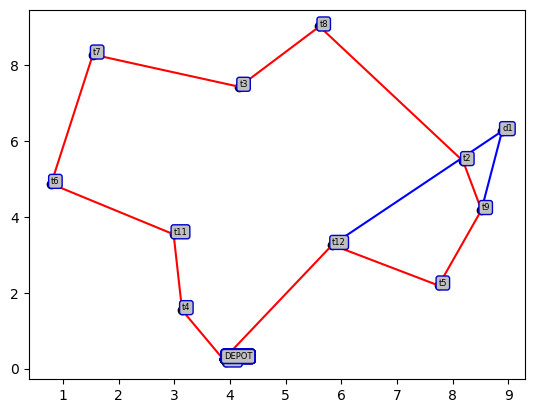

[INFO] Exported: truck_times, drone_times, label, drone_mission, tsp_used
------------------------------------------------------------------------------------------------------------------------


In [1511]:
"""
Disruption TSP-D heuristic on the COMPACT instance.

Inputs expected in the global namespace BEFORE running main():

    V2_compact : list[(x,y)]
        Coordinates of remaining nodes, indexed by compact id 0..n-1.
        Node 0     = truck location at disruption time.
        Node n-1   = final depot (original depot).

    tT_compact : dict[(i,j)] -> float
        Truck travel times (minutes) between compact nodes i,j.

    dT_compact : dict[(i,j)] -> float
        Drone travel times (minutes) between compact nodes i,j.

    Reg3 : list[int] of length n
        Reg3[i] = disruption region index of node i (0 = no region).

    TCon : dict/list-like
        TCon[r] = (start_time, end_time) disruption window for region r>0.

    hp_compact : list[int]
        Hamiltonian path in compact ids that starts at 0 and ends at n-1,
        visiting every node exactly once. Used as the INITIAL TOUR for the
        disruption heuristic.

    DRN : int or None
        Compact id of Drone Rescue Node (emergency landing location),
        or None if no rescue constraint.

    ND_compact : set[int], optional
        Additional compact node ids that must NEVER be drone-only customers.
        If missing, only {0, n-1, DRN} are forbidden.

Outputs written to globals AFTER main():

    truck_times   : dict[i] = [arrival, departure] for truck
    drone_times   : dict[i] = [arrival, departure] for drone (launch/R)
    drone_mission : dict[d] = (L, R) for drone customers
    label         : dict[i] in {"combined", "truck", "drone"}
    tsp_used      : final TSP tour used for partitioning (compact ids)
"""

import math
import numpy as np
import time as _time
from collections import defaultdict, OrderedDict

# =========================================================
# Global parameters / toggles
# =========================================================
#SEED
SAMPLE_RATIO = 1

DRAW_ROUTES = True  # set False if you don't want plotting

LS_EPS = 1e-9
LS_MAX_PASSES = 60
LS_MAX_SECONDS = 360.0
LS_MAX_NEIGHBOR_EVALS = 200000

PART_ATTEMPT_MULT = 10   # for inner attempt cap in greedy_partitioning

TRUCK_SPEED = 25.0
DRONE_SPEED = 35.0

# these will be set in main()
V1 = None      # compact coords
Reg = None     # compact regions
tT = None      # truck time dict
dT = None      # drone time dict
tsp1 = None    # initial tour (hp_compact)
# DRN is expected to be defined by you before calling main()

# =========================================================
# Optional drawing import
# =========================================================
try:
    from route_drawing import drawing_routes_using_labels
except Exception:
    drawing_routes_using_labels = None

# =========================================================
# Fallback 2-opt (only used if tsp_init is None)
# =========================================================
try:
    from solving_TSP import two_opt_for_TSP
except Exception:
    def two_opt_for_TSP(V):
        return list(range(len(V)))

# =========================================================
# Basic guards / helpers
# =========================================================
def _ensure_travel_times():
    global tT, dT
    if not isinstance(tT, dict) or not isinstance(dT, dict):
        raise RuntimeError("tT and dT must be defined as dicts before running.")


def get_forbidden_drone_nodes():
    """
    Build ND set: nodes that can NEVER be drone-only customers.

    - Always forbid:
        * depot (0),
        * final depot (n-1),
        * DRN (if any).
    - If ND_compact exists in globals, include it as well.
    """
    global V1, DRN
    n = len(V1)
    last_idx = n - 1

    base = set()
    if "ND_compact" in globals():
        base |= set(ND_compact)

    base.add(0)          # depot / current truck node
    base.add(last_idx)   # final depot

    if DRN is not None:
        base.add(DRN)

    return base

# =========================================================
# Robust travel-time accessors (compact ids)
# =========================================================
def truck_time(i, j):
    """
    Truck travel time lookup:

      1) tT[(i,j)]
      2) tT[(j,i)]
      3) recompute from geometry (Manhattan / TRUCK_SPEED) in minutes
    """
    global tT, V1

    if (i, j) in tT:
        return tT[(i, j)]
    if (j, i) in tT:
        return tT[(j, i)]

    xi, yi = V1[i]
    xj, yj = V1[j]
    manhattan = abs(xi - xj) + abs(yi - yj)
    val = (manhattan / TRUCK_SPEED) * 60.0
    tT[(i, j)] = val
    tT[(j, i)] = val
    return val


def drone_time(i, j):
    """
    Drone travel time lookup:

      1) dT[(i,j)]
      2) dT[(j,i)]
      3) recompute from geometry (Euclidean / DRONE_SPEED) in minutes
    """
    global dT, V1

    if (i, j) in dT:
        return dT[(i, j)]
    if (j, i) in dT:
        return dT[(j, i)]

    xi, yi = V1[i]
    xj, yj = V1[j]
    euclid = math.hypot(xi - xj, yi - yj)
    val = (euclid / DRONE_SPEED) * 60.0
    dT[(i, j)] = val
    dT[(j, i)] = val
    return val

# =========================================================
# Disruption checks
# =========================================================
def is_in_disruption(region_idx, t):
    """
    True if time t is inside the disruption window of region_idx.
    Region 0 / None = no disruption.
    """
    if region_idx is None or region_idx <= 0:
        return False
    start, end = TCon[region_idx]
    return (t >= start) and (t <= end)


def disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
    """
    Check:
      (1) Region-based disruption:
          launch, service, rendezvous times must NOT be inside disruption.
      (2) DRN constraints:
          - no launch from DRN
          - all launches after truck arrival at DRN
    """
    global Reg, DRN

    # 1) region-based disruption
    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            return False

        if is_in_disruption(Reg[L], drone_times[L][1]):
            return False
        if is_in_disruption(Reg[d], drone_times[d][0]):
            return False
        if is_in_disruption(Reg[R], drone_times[R][0]):
            return False

    # 2) DRN constraints
    if DRN is not None:
        if DRN not in truck_times:
            return False
        rescue_arrival = truck_times[DRN][0]

        for d, (L, R) in drone_mission.items():
            if L == DRN:
                return False
            if L not in drone_times:
                return False
            launch_time = drone_times[L][1]
            if launch_time < rescue_arrival - 1e-9:
                return False

    return True

# =========================================================
# Arrival / departure times
# =========================================================
def compute_arrival_times(tsp, depot, label, drone_mission):
    """
    Compute arrival/dep times for TRUCK and DRONE on compact instance.

    - Launch at L: SL=1 (0 if L==depot)
    - Recovery at R: SR=1
    - Drone-only customer: 0 service time
    """
    _ensure_travel_times()

    SL_default = 1.0
    SR = 1.0

    # Truck path = tsp without pure-drone nodes (path order, NO wrap)
    truck_path = [u for u in tsp if label.get(u, "combined") != "drone"]

    missions_by_L = defaultdict(list)
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        missions_by_L[L].append(d)
        missions_by_R[R].append(d)

    truck_times = {}
    drone_times = {}
    drone_R_time = {}

    if not truck_path:
        return truck_times, drone_times

    for u in truck_path:
        drone_times[u] = [0.0, 0.0]

    t = 0.0
    start = truck_path[0]
    truck_times[start] = [t, t]

    # Recovery at start
    if start in missions_by_R:
        known = [drone_R_time[d] for d in missions_by_R[start] if d in drone_R_time]
        if known:
            latest = max(known)
            if latest > t:
                t = latest
            t += SR
            truck_times[start][1] = t
            for d in missions_by_R[start]:
                if d in drone_R_time:
                    drone_times[start] = [drone_R_time[d], t]

    # Launch(es) at start
    if start in missions_by_L:
        for d in missions_by_L[start]:
            L = start
            R = drone_mission[d][1]
            SL = 0.0 if L == depot else SL_default
            t += SL
            truck_times[L][1] = t

            arrL = truck_times[L][0]
            drone_times[L] = [arrL, t]

            d_arr = t + drone_time(L, d)
            R_arr = d_arr + drone_time(d, R)
            drone_times[d] = [d_arr, d_arr]
            drone_R_time[d] = R_arr

    # Traverse truck path
    for idx in range(1, len(truck_path)):
        prev = truck_path[idx - 1]
        cur = truck_path[idx]

        t += truck_time(prev, cur)
        truck_times[cur] = [t, t]

        if cur in missions_by_R:
            known = [drone_R_time[d] for d in missions_by_R[cur] if d in drone_R_time]
            if known:
                latest = max(known)
                if latest > t:
                    t = latest
                t += SR
                truck_times[cur][1] = t
                for d in missions_by_R[cur]:
                    if d in drone_R_time:
                        drone_times[cur] = [drone_R_time[d], t]

        if cur in missions_by_L:
            for d in missions_by_L[cur]:
                L = cur
                R = drone_mission[d][1]
                SL = 0.0 if L == depot else SL_default
                t += SL
                truck_times[L][1] = t

                arrL = truck_times[L][0]
                if L not in drone_times:
                    drone_times[L] = [arrL, t]
                else:
                    if drone_times[L][0] == 0.0:
                        drone_times[L][0] = arrL
                    drone_times[L][1] = max(drone_times[L][1], t)

                d_arr = t + drone_time(L, d)
                R_arr = d_arr + drone_time(d, R)
                drone_times[d] = [d_arr, d_arr]
                drone_R_time[d] = R_arr

    return truck_times, drone_times


def compute_true_makespan(truck_times, drone_times):
    max_t = 0.0
    for a, d in truck_times.values():
        max_t = max(max_t, a, d)
    for a, d in drone_times.values():
        max_t = max(max_t, a, d)
    return max_t

# =========================================================
# Greedy partitioning with disruption + DRN
# =========================================================
def greedy_partitioning(tsp, depot, alpha=1.0):
    """
    Main greedy partitioning:
      - Make Fly
      - Push Left
      - Push Right
    with:
      - energy limit e=40
      - region-based disruption constraints
      - DRN constraints
      - ND set forbidding some nodes as drone-only

    NOTE: tsp is treated as a CYCLE inside this function (via % n1),
    but the truck schedule uses it as a PATH from tsp[0] to tsp[-1].
    """
    _ensure_travel_times()
    ND = get_forbidden_drone_nodes()
    e = 20.0

    label = {}
    operation, flyop, driveop = {}, {}, {}
    drone_mission = {}

    tsptotal = 0.0
    n1 = len(tsp)
    for k in range(n1):
        i = tsp[k]
        j = tsp[(k + 1) % n1]   # cycle edge for cost/savings
        label[i] = "simple"
        tsptotal += truck_time(i, j)
    # label for last node (in case n1==1 this is already set, otherwise okay)
    label[tsp[-1]] = label.get(tsp[-1], "simple")

    n = len(label)
    tspdtotal = tsptotal

    truck_times = {}
    drone_times = {}
    done = False

    while "simple" in label.values() and not done:
        banned = set()
        attempts = 0
        MAX_ATTEMPTS = max(5, PART_ATTEMPT_MULT * n)

        while True:
            attempts += 1
            if attempts > MAX_ATTEMPTS:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                    print("[WARN] Final partition violates disruption constraints (attempt cap).")
                done = True
                break

            ms = []
            idx_map = []

            # 1) Make Fly
            for pos in range(n1):
                if (0, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((0, pos))
                    continue

                saving = -float("inf")
                u = tsp[pos]

                if label[u] == "simple" and u not in ND and u != depot:
                    L = tsp[pos - 1]
                    R = tsp[(pos + 1) % n1]

                    if DRN is not None and L == DRN:
                        ms.append(-float("inf"))
                        idx_map.append((0, pos))
                        continue

                    fly_time = drone_time(L, u) + drone_time(u, R)
                    if fly_time + 1.0 <= e and truck_time(L, R) <= e:
                        base = truck_time(L, u) + truck_time(u, R)
                        alt = max(fly_time, truck_time(L, R) + 2.0)
                        saving = base - alt

                ms.append(saving)
                idx_map.append((0, pos))

            # 2) Push Left
            for pos in range(n1):
                if (1, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((1, pos))
                    continue

                saving = -float("inf")
                cur = tsp[pos]
                prev = tsp[pos - 1]

                if label.get(prev) == "combined" and prev != depot and label.get(cur) == "simple":
                    j = pos - 2
                    dronenode = None
                    while label[tsp[j]] != "combined":
                        if label[tsp[j]] == "drone":
                            dronenode = j
                        if label[tsp[j - 1]] == "combined" and dronenode is not None:
                            d = tsp[dronenode]
                            L = tsp[j - 1]

                            if DRN is not None and L == DRN:
                                break

                            R_old = prev
                            R_new = cur
                            base_key = (d, L, R_old)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                fly_new = drone_time(L, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(R_old, R_new)
                                if fly_new + 1.0 <= e and drive_new <= e:
                                    saving = truck_time(R_old, R_new) + operation[base_key] - \
                                             max(fly_new, drive_new + 2.0)
                            break
                        j -= 1

                ms.append(saving)
                idx_map.append((1, pos))

            # 3) Push Right
            for pos in range(n1):
                if (2, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((2, pos))
                    continue

                saving = -float("inf")
                cur = tsp[pos]
                nxt = tsp[(pos + 1) % n1]

                if label.get(nxt) == "combined" and nxt != depot and label.get(cur) == "simple":
                    j = (pos + 2) % n1
                    dronenode = None
                    while label[tsp[j]] != "combined":
                        if label[tsp[j]] == "drone":
                            dronenode = j
                        if label[tsp[(j + 1) % n1]] == "combined" and dronenode is not None:
                            d = tsp[dronenode]
                            L_old = nxt
                            R = tsp[(j + 1) % n1]

                            if DRN is not None and (L_old == DRN or cur == DRN):
                                break

                            R_new = R
                            base_key = (d, L_old, R_new)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                fly_new = drone_time(cur, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(cur, L_old)
                                if fly_new + 1.0 <= e and drive_new <= e:
                                    saving = truck_time(cur, L_old) + operation[base_key] - \
                                             max(fly_new, drive_new + 2.0)
                            break
                        j = (j + 1) % n1

                ms.append(saving)
                idx_map.append((2, pos))

            idx = int(np.argmax(ms))
            best_saving = ms[idx]

            if best_saving <= 0:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                    print("[WARN] Final partition violates disruption constraints.")
                done = True
                break

            block, pos = idx_map[idx]

            # backup
            label_b = dict(label)
            drone_b = dict(drone_mission)
            op_b = dict(operation)
            flyop_b = dict(flyop)
            driveop_b = dict(driveop)
            tspd_b = tspdtotal

            # apply
            if block == 0:
                d = tsp[pos]
                L = tsp[pos - 1]
                R = tsp[(pos + 1) % n1]

                if DRN is not None and L == DRN:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                label[d] = "drone"
                label[L] = "combined"
                label[R] = "combined"
                flyop.setdefault((d, L, R), drone_time(L, d) + drone_time(d, R))
                driveop.setdefault((d, L, R), truck_time(L, R))
                operation[(d, L, R)] = max(flyop[(d, L, R)], driveop[(d, L, R)])
                drone_mission[d] = (L, R)

            elif block == 1:
                label[tsp[pos]] = "combined"
                label[tsp[(pos - 1) % n1]] = "truck"
                j = (pos - 2) % n1
                dronenode = None
                while label[tsp[j]] != "combined":
                    if label[tsp[j]] == "drone":
                        dronenode = j
                    if label[tsp[j - 1]] == "combined" and dronenode is not None:
                        d = tsp[dronenode]
                        L = tsp[j - 1]

                        if DRN is not None and L == DRN:
                            break

                        R_new = tsp[pos]
                        prev_R = tsp[(pos - 1) % n1]
                        flyop[(d, L, R_new)] = drone_time(L, d) + drone_time(d, R_new)
                        driveop[(d, L, R_new)] = driveop[(d, L, prev_R)] + truck_time(prev_R, R_new)
                        operation[(d, L, R_new)] = max(flyop[(d, L, R_new)], driveop[(d, L, R_new)])
                        drone_mission[d] = (L, R_new)
                        break
                    j -= 1

            else:
                label[tsp[pos]] = "combined"
                label[tsp[(pos + 1) % n1]] = "truck"
                j = (pos + 2) % n1
                dronenode = None
                while label[tsp[j]] != "combined":
                    if label[tsp[j]] == "drone":
                        dronenode = j
                    if label[tsp[(j + 1) % n1]] == "combined" and dronenode is not None:
                        d = tsp[dronenode]
                        L_new = tsp[pos]

                        if DRN is not None and L_new == DRN:
                            break

                        R = tsp[(j + 1) % n1]
                        next_L = tsp[(pos + 1) % n1]
                        flyop[(d, L_new, R)] = drone_time(L_new, d) + drone_time(d, R)
                        driveop[(d, L_new, R)] = driveop[(d, next_L, R)] + truck_time(L_new, next_L)
                        operation[(d, L_new, R)] = max(flyop[(d, L_new, R)], driveop[(d, L_new, R)])
                        drone_mission[d] = (L_new, R)
                        break
                    j = (j + 1) % n1

            tspdtotal -= best_saving

            truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
            if disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                break
            else:
                label = label_b
                drone_mission = drone_b
                operation = op_b
                flyop = flyop_b
                driveop = driveop_b
                tspdtotal = tspd_b
                banned.add((block, pos))

    dset = {u for u in label if label[u] == "drone"}
    return tspdtotal, label, dset, drone_mission, truck_times, drone_times

# =========================================================
# Move operators + local search (with endpoints pinned)
# =========================================================
def two_points_move(route, i, j):
    if i == j:
        return route[:]
    r = route[:]
    r[i], r[j] = r[j], r[i]
    return r


def two_opt_move(route, i, j):
    if i == j:
        return route[:]
    if i > j:
        i, j = j, i
    return route[:i+1] + route[i+1:j+1][::-1] + route[j+1:]


def one_point_move(route, i, j):
    if i == j:
        return route[:]
    r = route[:]
    node = r.pop(i)
    r.insert(j, node)
    return r


def _rotate_to_depot(route, depot):
    """
    Kept for compatibility, but NOT used in local search anymore.
    """
    if route[0] == depot:
        return route
    k = route.index(depot)
    return route[k:] + route[:k]


def improve_all(heuristic, route_in, depot, sample_ratio=SAMPLE_RATIO, rng_seed=SEED):
    """
    Generic local search wrapper:

      - Uses random sampling of pairs (i,j) with sample_ratio.
      - Applies 3 move operators.
      - Evaluates using the given heuristic (here: greedy_partitioning).

    IMPORTANT for disruption:
      - route_in is treated as a PATH.
      - We KEEP route_in[0] == depot.
      - We KEEP route_in[-1] == final depot (n-1).
      - We only move nodes in positions 1..n-2.
    """
    _ensure_travel_times()

    route_best = list(route_in)
    n = len(route_best)

    assert route_best[0] == depot, "route_in must start at depot in disruption mode."
    # final depot is whatever is currently last; we pin that position
    pinned_end = route_best[-1]

    cache = {}

    def eval_route(rt):
        # endpoints must remain pinned
        assert rt[0] == depot
        assert rt[-1] == pinned_end
        key = tuple(rt)
        if key in cache:
            return cache[key]
        # NO rotation here: treat as given path
        val = heuristic(rt, depot, alpha=1.0)[0]
        cache[key] = val
        return val

    f_best = eval_route(route_best)

    if rng_seed is not None:
        np.random.seed(rng_seed)

    # interior indices only: keep endpoints fixed in place
    interior = list(range(1, n - 1))
    all_pairs = [(i, j) for i in interior for j in interior if j != i]
    m = len(all_pairs)

    if m == 0:
        # nothing to move (n <= 2), just return
        return route_best

    k = int(round(sample_ratio * m))
    if k <= 0:
        k = 1
    if k > m:
        k = m

    start_time = _time.time()
    passes = 0
    neighbor_evals = 0

    improved = True
    while improved:
        passes += 1
        if passes > LS_MAX_PASSES:
            break
        if LS_MAX_SECONDS is not None and (_time.time() - start_time) > LS_MAX_SECONDS:
            break

        improved = False
        idxs = np.random.choice(m, size=k, replace=False)
        best_neighbor = None
        best_cost = f_best

        for p in idxs:
            i, j = all_pairs[p]
            for mv in (two_points_move, two_opt_move, one_point_move):
                cand = mv(route_best, i, j)

                # enforce endpoints pinned
                if cand[0] != depot or cand[-1] != pinned_end:
                    continue

                neighbor_evals += 1
                fc = eval_route(cand)
                if fc < best_cost - LS_EPS:
                    best_neighbor = cand
                    best_cost = fc

                if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
                    break
            if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
                break

        if best_neighbor is not None:
            route_best = best_neighbor
            f_best = best_cost
            improved = True

        if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
            break

    return route_best


def two_opt_greedy_partitioning_all_improved(V, depot, alpha, tsp_init=None):
    """
    Wrapper:
      - If tsp_init is given (like hp_compact), we use it as the INITIAL PATH
        and run local search improve_all on it (endpoints pinned).
      - If tsp_init is None, we build a 2-opt TSP and improve it
        (not used in your disruption pipeline).
    """
    _ensure_travel_times()

    n = len(V)
    if tsp_init is not None:
        tsp_seed = list(tsp_init)
        assert tsp_seed[0] == depot, "hp_compact / tsp_init must start at depot."
        assert len(tsp_seed) == n, "tsp_init must visit all nodes."
        assert sorted(tsp_seed) == list(range(n)), "tsp_init must be a permutation of 0..n-1."
        tsp_best = improve_all(greedy_partitioning, tsp_seed, depot,
                               sample_ratio=SAMPLE_RATIO, rng_seed=SEED)
    else:
        tsp_seed = two_opt_for_TSP(V)
        if len(tsp_seed) != n or sorted(tsp_seed) != list(range(n)):
            raise ValueError("Initial tour must be a permutation of 0..n-1.")
        tsp_seed = _rotate_to_depot(tsp_seed, depot)
        tsp_best = improve_all(greedy_partitioning, tsp_seed, depot,
                               sample_ratio=SAMPLE_RATIO, rng_seed=SEED)

    res = greedy_partitioning(tsp_best, depot, alpha)
    return res, tsp_best

# =========================================================
# MAIN
# =========================================================
def main():
    """
    Attach V2_compact, Reg3, tT_compact, dT_compact, hp_compact, DRN, ND_compact
    to global names. Then run TSP-D disruption heuristic on compact instance.
    """
    global V1, Reg, tT, dT, tsp1, new2old

    V1 = V2_compact
    Reg = list(Reg3)
    tT = dict(tT_compact)
    dT = dict(dT_compact)
    tsp1 = list(hp_compact)

    n = len(V1)
    depot = 0
    alpha = 1.0

    # sanity checks
    assert len(tsp1) == n, "hp_compact length must equal number of compact nodes."
    assert sorted(tsp1) == list(range(n)), "hp_compact must be a permutation of 0..n-1."
    assert tsp1[0] == 0, "hp_compact must start at node 0 (truck at disruption)."
    assert tsp1[-1] == n - 1, "hp_compact must end at node n-1 (final depot)."

    new2old = {i: i for i in range(n)}

    _ensure_travel_times()

    ND = get_forbidden_drone_nodes()
    print("-" * 120)
    print(f"[INFO] Disrupted instance in compact IDs 0..{n-1}")
    print(f"[INFO] #remaining nodes: {n}")
    print(f"[INFO] ND (forbidden drone nodes): {sorted(ND)}")

    tsp_init = tsp1

    start = _time.time()
    (total_cost,
     label,
     drone_nodes,
     drone_mission,
     truck_times,
     drone_times), tsp_used = two_opt_greedy_partitioning_all_improved(
        V1, depot, alpha, tsp_init=tsp_init
    )
    end = _time.time()

    makespan = compute_true_makespan(truck_times, drone_times)
    #print(f"Running time: {end-start:.4f} sec")
    print(f"Heuristic TSP-D cost (truck - ops): {total_cost:.4f}")
    print(f"True makespan from schedule: {makespan:.4f}")
    print(f"# drone customers: {len(drone_nodes)}")
    print(f"Drone customers (compact IDs): {sorted(drone_nodes)}")

    ordered_labels = OrderedDict((u, label[u]) for u in tsp_used)
    print("Labels along tour (visit order, compact IDs):")
    print("# Drone customers before Disruption: ", DroneBefDis)  # your diagnostics
    print(".................")
    print("SEED is:", SEED)
    print(f"Running time: {end-start:.4f} sec")
    print("Total True makespan from schedule:", round(makespan, 4) + t0)
    print("Total # Drone customers : ", DroneBefDis + len(drone_nodes))
    print("Truck Only : ", TruckOnlyTotal) #ABAB
    print(".................")
    print("TCon is: ", TCon)                                     # your diagnostics
    print(ordered_labels)

    assert tsp_used[0] == 0, "Final tour does not start at 0 (should not happen)."
    assert tsp_used[-1] == n - 1, "Final tour does not end at n-1 (should not happen)."

    if DRAW_ROUTES and drawing_routes_using_labels is not None:
        try:
            drawing_routes_using_labels(V1, label, depot, drone_nodes)
        except Exception as e:
            print(f"(Route drawing skipped) {e}")

    globals()["truck_times"] = truck_times
    globals()["drone_times"] = drone_times
    globals()["label"] = label
    globals()["drone_mission"] = drone_mission
    globals()["tsp_used"] = tsp_used
    print("[INFO] Exported: truck_times, drone_times, label, drone_mission, tsp_used")
    print("-" * 120)

# Auto-run main if executed
if __name__ == "__main__":
    main()


In [1512]:
##2222
TCon

[[0, 0], [0, 20], [20, 40], [40, 60]]

In [1513]:
drone_times

{0: [0.0, 0.0],
 10: [0.0, 0.0],
 4: [0.0, 0.0],
 11: [0.0, 0.0],
 6: [0.0, 0.0],
 7: [0.0, 0.0],
 3: [0.0, 0.0],
 8: [0.0, 0.0],
 2: [0.0, 0.0],
 9: [63.3589074653451, 64.3589074653451],
 5: [0.0, 0.0],
 12: [75.31455514790953, 79.1349074653451],
 1: [67.98059722769277, 67.98059722769277]}

In [1514]:
drone_mission

{1: (9, 12)}

------------------------------------------------------------------------------------------------------------------------
[INFO] Disrupted instance in compact IDs 0..12
[INFO] #remaining nodes: 13
[INFO] ND (forbidden drone nodes): [0, 4, 5, 12]
Heuristic TSP-D cost (truck - ops): 79.1349
True makespan from schedule: 79.1349
# drone customers: 1
Drone customers (compact IDs): [1]
Labels along path (visit order, compact IDs):
# Drone customers before Disruption:  1
.................
SEED is: 1923
Running time: 0.0754 sec
Total True makespan from schedule: 94.1349
Total # Drone customers :  2
Truck Only :  95.4949074653451
.................
TCon is:  [[0, 0], [0, 20], [20, 40], [40, 60]]
OrderedDict([(0, 'combined'), (10, 'combined'), (4, 'combined'), (11, 'combined'), (6, 'combined'), (7, 'combined'), (3, 'combined'), (8, 'combined'), (2, 'combined'), (9, 'combined'), (5, 'truck'), (1, 'drone'), (12, 'combined')])


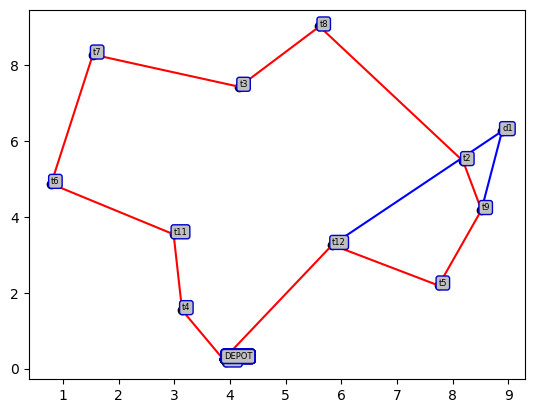

[INFO] Exported: truck_times, drone_times, label, drone_mission, tsp_used
------------------------------------------------------------------------------------------------------------------------


In [1515]:
"""
Disruption TSP-D heuristic on the COMPACT instance.

Inputs expected in the global namespace BEFORE running main():

    V2_compact : list[(x,y)]
        Coordinates of remaining nodes, indexed by compact id 0..n-1.
        Node 0     = truck location at disruption time.
        Node n-1   = final depot (original depot).

    tT_compact : dict[(i,j)] -> float
        Truck travel times (minutes) between compact nodes i,j.

    dT_compact : dict[(i,j)] -> float
        Drone travel times (minutes) between compact nodes i,j.

    Reg3 : list[int] of length n
        Reg3[i] = disruption region index of node i (0 = no region).

    TCon : dict/list-like
        TCon[r] = (start_time, end_time) disruption window for region r>0.

    hp_compact : list[int]
        Hamiltonian PATH in compact ids that starts at 0 and ends at n-1,
        visiting every node exactly once. Used as the INITIAL PATH for the
        disruption heuristic.

    DRN : int or None
        Compact id of Drone Rescue Node, or None if no rescue constraint.

    ND_compact : set[int], optional
        Additional compact node ids that must NEVER be drone-only customers.
        If missing, only {0, n-1, DRN} are forbidden.

Outputs written to globals AFTER main():

    truck_times   : dict[i] = [arrival, departure] for truck
    drone_times   : dict[i] = [arrival, departure] for drone (launch/R)
    drone_mission : dict[d] = (L, R) for drone customers
    label         : dict[i] in {"combined", "truck", "drone"}
    tsp_used      : final TSP path used for partitioning (compact ids)
"""

import math
import numpy as np
import time as _time
from collections import defaultdict, OrderedDict

# =========================================================
# Global parameters / toggles
# =========================================================
# SEED should already exist in your notebook/script
SAMPLE_RATIO = 1

DRAW_ROUTES = True

LS_EPS = 1e-9
LS_MAX_PASSES = 60
LS_MAX_SECONDS = 360.0
LS_MAX_NEIGHBOR_EVALS = 200000

PART_ATTEMPT_MULT = 10

TRUCK_SPEED = 25.0
DRONE_SPEED = 35.0

# these will be set in main()
V1 = None
Reg = None
tT = None
dT = None
tsp1 = None
# DRN is expected to be defined before calling main()

# =========================================================
# Optional drawing import
# =========================================================
try:
    from route_drawing import drawing_routes_using_labels
except Exception:
    drawing_routes_using_labels = None

# =========================================================
# Fallback 2-opt (only used if tsp_init is None)
# =========================================================
try:
    from solving_TSP import two_opt_for_TSP
except Exception:
    def two_opt_for_TSP(V):
        return list(range(len(V)))

# =========================================================
# Basic guards / helpers
# =========================================================
def _ensure_travel_times():
    global tT, dT
    if not isinstance(tT, dict) or not isinstance(dT, dict):
        raise RuntimeError("tT and dT must be defined as dicts before running.")


def get_forbidden_drone_nodes():
    """
    Build ND set: nodes that can NEVER be drone-only customers.

    Always forbid:
      - depot (0)
      - final depot (n-1)
      - DRN (if any)

    Also include ND_compact if provided externally.
    """
    global V1, DRN

    n = len(V1)
    last_idx = n - 1

    base = set()
    if "ND_compact" in globals():
        base |= set(ND_compact)

    base.add(0)
    base.add(last_idx)

    if DRN is not None:
        base.add(DRN)

    return base

# =========================================================
# Robust travel-time accessors (compact ids)
# =========================================================
def truck_time(i, j):
    """
    Truck travel time lookup:
      1) tT[(i,j)]
      2) tT[(j,i)]
      3) recompute from geometry (Manhattan / TRUCK_SPEED) in minutes
    """
    global tT, V1

    if (i, j) in tT:
        return tT[(i, j)]
    if (j, i) in tT:
        return tT[(j, i)]

    xi, yi = V1[i]
    xj, yj = V1[j]
    manhattan = abs(xi - xj) + abs(yi - yj)
    val = (manhattan / TRUCK_SPEED) * 60.0
    tT[(i, j)] = val
    tT[(j, i)] = val
    return val


def drone_time(i, j):
    """
    Drone travel time lookup:
      1) dT[(i,j)]
      2) dT[(j,i)]
      3) recompute from geometry (Euclidean / DRONE_SPEED) in minutes
    """
    global dT, V1

    if (i, j) in dT:
        return dT[(i, j)]
    if (j, i) in dT:
        return dT[(j, i)]

    xi, yi = V1[i]
    xj, yj = V1[j]
    euclid = math.hypot(xi - xj, yi - yj)
    val = (euclid / DRONE_SPEED) * 60.0
    dT[(i, j)] = val
    dT[(j, i)] = val
    return val

# =========================================================
# Disruption checks
# =========================================================
def is_in_disruption(region_idx, t):
    """
    True if time t is inside the disruption window of region_idx.
    Region 0 / None = no disruption.
    """
    if region_idx is None or region_idx <= 0:
        return False
    start, end = TCon[region_idx]
    return (t >= start) and (t <= end)


def disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
    """
    Check:
      (1) Region-based disruption:
          launch, service, rendezvous times must NOT be inside disruption.
      (2) DRN constraints:
          - no launch from DRN
          - all launches after truck arrival at DRN
    """
    global Reg, DRN

    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            return False

        if is_in_disruption(Reg[L], drone_times[L][1]):
            return False
        if is_in_disruption(Reg[d], drone_times[d][0]):
            return False
        if is_in_disruption(Reg[R], drone_times[R][0]):
            return False

    if DRN is not None:
        if DRN not in truck_times:
            return False

        rescue_arrival = truck_times[DRN][0]

        for d, (L, R) in drone_mission.items():
            if L == DRN:
                return False
            if L not in drone_times:
                return False
            launch_time = drone_times[L][1]
            if launch_time < rescue_arrival - 1e-9:
                return False

    return True

# =========================================================
# Arrival / departure times
# =========================================================
def compute_arrival_times(tsp, depot, label, drone_mission):
    """
    Compute arrival/dep times for TRUCK and DRONE on compact instance.

    - Launch at L: SL = 1 (0 if L == depot)
    - Recovery at R: SR = 1
    - Drone-only customer: 0 service time
    """
    _ensure_travel_times()

    SL_default = 1.0
    SR = 1.0

    truck_path = [u for u in tsp if label.get(u, "combined") != "drone"]

    missions_by_L = defaultdict(list)
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        missions_by_L[L].append(d)
        missions_by_R[R].append(d)

    truck_times = {}
    drone_times = {}
    drone_R_time = {}

    if not truck_path:
        return truck_times, drone_times

    for u in truck_path:
        drone_times[u] = [0.0, 0.0]

    t = 0.0
    start = truck_path[0]
    truck_times[start] = [t, t]

    if start in missions_by_R:
        known = [drone_R_time[d] for d in missions_by_R[start] if d in drone_R_time]
        if known:
            latest = max(known)
            if latest > t:
                t = latest
            t += SR
            truck_times[start][1] = t
            for d in missions_by_R[start]:
                if d in drone_R_time:
                    drone_times[start] = [drone_R_time[d], t]

    if start in missions_by_L:
        for d in missions_by_L[start]:
            L = start
            R = drone_mission[d][1]
            SL = 0.0 if L == depot else SL_default
            t += SL
            truck_times[L][1] = t

            arrL = truck_times[L][0]
            drone_times[L] = [arrL, t]

            d_arr = t + drone_time(L, d)
            R_arr = d_arr + drone_time(d, R)
            drone_times[d] = [d_arr, d_arr]
            drone_R_time[d] = R_arr

    for idx in range(1, len(truck_path)):
        prev = truck_path[idx - 1]
        cur = truck_path[idx]

        t += truck_time(prev, cur)
        truck_times[cur] = [t, t]

        if cur in missions_by_R:
            known = [drone_R_time[d] for d in missions_by_R[cur] if d in drone_R_time]
            if known:
                latest = max(known)
                if latest > t:
                    t = latest
                t += SR
                truck_times[cur][1] = t
                for d in missions_by_R[cur]:
                    if d in drone_R_time:
                        drone_times[cur] = [drone_R_time[d], t]

        if cur in missions_by_L:
            for d in missions_by_L[cur]:
                L = cur
                R = drone_mission[d][1]
                SL = 0.0 if L == depot else SL_default
                t += SL
                truck_times[L][1] = t

                arrL = truck_times[L][0]
                if L not in drone_times:
                    drone_times[L] = [arrL, t]
                else:
                    if drone_times[L][0] == 0.0:
                        drone_times[L][0] = arrL
                    drone_times[L][1] = max(drone_times[L][1], t)

                d_arr = t + drone_time(L, d)
                R_arr = d_arr + drone_time(d, R)
                drone_times[d] = [d_arr, d_arr]
                drone_R_time[d] = R_arr

    return truck_times, drone_times


def compute_true_makespan(truck_times, drone_times):
    max_t = 0.0
    for a, d in truck_times.values():
        max_t = max(max_t, a, d)
    for a, d in drone_times.values():
        max_t = max(max_t, a, d)
    return max_t

# =========================================================
# Path-based helpers for greedy partitioning
# =========================================================
def _find_left_mission_block(tsp, label, pos):
    """
    For PUSH LEFT:
    Find mission block immediately to the left of pos:
        L ... d ... R_old
    where R_old = tsp[pos-1] is currently combined.

    Returns:
        (d, L, R_old) or None
    """
    if pos <= 1:
        return None

    R_old = tsp[pos - 1]
    if label.get(R_old) != "combined":
        return None

    dronenode_idx = None
    j = pos - 2

    while j >= 0 and label.get(tsp[j]) != "combined":
        if label.get(tsp[j]) == "drone":
            dronenode_idx = j
        j -= 1

    if j >= 0 and dronenode_idx is not None:
        L = tsp[j]
        d = tsp[dronenode_idx]
        return d, L, R_old

    return None


def _find_right_mission_block(tsp, label, pos):
    """
    For PUSH RIGHT:
    Find mission block immediately to the right of pos:
        L_old ... d ... R
    where L_old = tsp[pos+1] is currently combined.

    Returns:
        (d, L_old, R) or None
    """
    n1 = len(tsp)
    if pos >= n1 - 2:
        return None

    L_old = tsp[pos + 1]
    if label.get(L_old) != "combined":
        return None

    dronenode_idx = None
    j = pos + 2

    while j < n1 and label.get(tsp[j]) != "combined":
        if label.get(tsp[j]) == "drone":
            dronenode_idx = j
        j += 1

    if j < n1 and dronenode_idx is not None:
        R = tsp[j]
        d = tsp[dronenode_idx]
        return d, L_old, R

    return None

# =========================================================
# Greedy partitioning with disruption + DRN (PATH VERSION)
# =========================================================
def greedy_partitioning(tsp, depot, alpha=1.0):
    """
    Main greedy partitioning on a PATH:
      - Make Fly
      - Push Left
      - Push Right

    Constraints:
      - energy limit e = 20
      - region-based disruption constraints
      - DRN constraints
      - ND set forbidding some nodes as drone-only

    IMPORTANT:
      tsp is treated as a PATH from tsp[0] to tsp[-1].
      No wrap-around / no modulo indexing is used here.
    """
    _ensure_travel_times()
    ND = get_forbidden_drone_nodes()
    e = 20.0

    label = {u: "simple" for u in tsp}
    operation, flyop, driveop = {}, {}, {}
    drone_mission = {}

    n1 = len(tsp)

    tsptotal = 0.0
    for k in range(n1 - 1):
        tsptotal += truck_time(tsp[k], tsp[k + 1])

    tspdtotal = tsptotal
    truck_times = {}
    drone_times = {}
    done = False

    if n1 < 3:
        for u in label:
            label[u] = "combined"
        truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
        dset = {u for u in label if label[u] == "drone"}
        return tspdtotal, label, dset, drone_mission, truck_times, drone_times

    while "simple" in label.values() and not done:
        banned = set()
        attempts = 0
        MAX_ATTEMPTS = max(5, PART_ATTEMPT_MULT * len(label))

        while True:
            attempts += 1

            if attempts > MAX_ATTEMPTS:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                    print("[WARN] Final partition violates disruption constraints (attempt cap).")
                done = True
                break

            ms = []
            idx_map = []

            # 1) Make Fly
            for pos in range(1, n1 - 1):
                if (0, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((0, pos))
                    continue

                saving = -float("inf")
                u = tsp[pos]

                if label[u] == "simple" and u not in ND and u != depot:
                    L = tsp[pos - 1]
                    R = tsp[pos + 1]

                    if DRN is not None and L == DRN:
                        ms.append(-float("inf"))
                        idx_map.append((0, pos))
                        continue

                    fly_time = drone_time(L, u) + drone_time(u, R)
                    drive_time = truck_time(L, R)

                    if fly_time + 1.0 <= e and drive_time <= e:
                        base = truck_time(L, u) + truck_time(u, R)
                        alt = max(fly_time, drive_time + 2.0)
                        saving = base - alt

                ms.append(saving)
                idx_map.append((0, pos))

            # 2) Push Left
            for pos in range(1, n1 - 1):
                if (1, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((1, pos))
                    continue

                saving = -float("inf")
                cur = tsp[pos]
                prev = tsp[pos - 1]

                if label.get(prev) == "combined" and label.get(cur) == "simple" and prev != depot:
                    found = _find_left_mission_block(tsp, label, pos)
                    if found is not None:
                        d, L, R_old = found

                        if DRN is None or L != DRN:
                            base_key = (d, L, R_old)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                R_new = cur
                                fly_new = drone_time(L, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(R_old, R_new)

                                if fly_new + 1.0 <= e and drive_new <= e:
                                    saving = (
                                        truck_time(R_old, R_new) + operation[base_key]
                                        - max(fly_new, drive_new + 2.0)
                                    )

                ms.append(saving)
                idx_map.append((1, pos))

            # 3) Push Right
            for pos in range(1, n1 - 1):
                if (2, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((2, pos))
                    continue

                saving = -float("inf")
                cur = tsp[pos]

                found = _find_right_mission_block(tsp, label, pos)
                if label.get(cur) == "simple" and found is not None:
                    d, L_old, R = found

                    if DRN is None or (L_old != DRN and cur != DRN):
                        base_key = (d, L_old, R)
                        if (d not in ND) and (base_key in operation) and (base_key in driveop):
                            L_new = cur
                            fly_new = drone_time(L_new, d) + drone_time(d, R)
                            drive_new = driveop[base_key] + truck_time(L_new, L_old)

                            if fly_new + 1.0 <= e and drive_new <= e:
                                saving = (
                                    truck_time(L_new, L_old) + operation[base_key]
                                    - max(fly_new, drive_new + 2.0)
                                )

                ms.append(saving)
                idx_map.append((2, pos))

            if not ms:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                done = True
                break

            idx = int(np.argmax(ms))
            best_saving = ms[idx]

            if best_saving <= 0:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                    print("[WARN] Final partition violates disruption constraints.")
                done = True
                break

            block, pos = idx_map[idx]

            label_b = dict(label)
            drone_b = dict(drone_mission)
            op_b = dict(operation)
            flyop_b = dict(flyop)
            driveop_b = dict(driveop)
            tspd_b = tspdtotal

            if block == 0:
                d = tsp[pos]
                L = tsp[pos - 1]
                R = tsp[pos + 1]

                if DRN is not None and L == DRN:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                label[d] = "drone"
                label[L] = "combined"
                label[R] = "combined"

                flyop[(d, L, R)] = drone_time(L, d) + drone_time(d, R)
                driveop[(d, L, R)] = truck_time(L, R)
                operation[(d, L, R)] = max(flyop[(d, L, R)], driveop[(d, L, R)])
                drone_mission[d] = (L, R)

            elif block == 1:
                found = _find_left_mission_block(tsp, label, pos)
                if found is None:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                d, L, R_old = found
                R_new = tsp[pos]

                if DRN is not None and L == DRN:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                label[R_new] = "combined"
                label[R_old] = "truck"

                flyop[(d, L, R_new)] = drone_time(L, d) + drone_time(d, R_new)
                driveop[(d, L, R_new)] = driveop[(d, L, R_old)] + truck_time(R_old, R_new)
                operation[(d, L, R_new)] = max(flyop[(d, L, R_new)], driveop[(d, L, R_new)])
                drone_mission[d] = (L, R_new)

            else:
                found = _find_right_mission_block(tsp, label, pos)
                if found is None:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                d, L_old, R = found
                L_new = tsp[pos]

                if DRN is not None and L_new == DRN:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                label[L_new] = "combined"
                label[L_old] = "truck"

                flyop[(d, L_new, R)] = drone_time(L_new, d) + drone_time(d, R)
                driveop[(d, L_new, R)] = driveop[(d, L_old, R)] + truck_time(L_new, L_old)
                operation[(d, L_new, R)] = max(flyop[(d, L_new, R)], driveop[(d, L_new, R)])
                drone_mission[d] = (L_new, R)

            tspdtotal -= best_saving

            truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)

            if disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                break
            else:
                label = label_b
                drone_mission = drone_b
                operation = op_b
                flyop = flyop_b
                driveop = driveop_b
                tspdtotal = tspd_b
                banned.add((block, pos))

    dset = {u for u in label if label[u] == "drone"}
    return tspdtotal, label, dset, drone_mission, truck_times, drone_times

# =========================================================
# Move operators + local search (with endpoints pinned)
# =========================================================
def two_points_move(route, i, j):
    if i == j:
        return route[:]
    r = route[:]
    r[i], r[j] = r[j], r[i]
    return r


def two_opt_move(route, i, j):
    if i == j:
        return route[:]
    if i > j:
        i, j = j, i
    return route[:i+1] + route[i+1:j+1][::-1] + route[j+1:]


def one_point_move(route, i, j):
    if i == j:
        return route[:]
    r = route[:]
    node = r.pop(i)
    r.insert(j, node)
    return r


def _rotate_to_depot(route, depot):
    """
    Kept for compatibility, but not used in local search anymore.
    """
    if route[0] == depot:
        return route
    k = route.index(depot)
    return route[k:] + route[:k]


def improve_all(heuristic, route_in, depot, sample_ratio=SAMPLE_RATIO, rng_seed=SEED):
    """
    Generic local search wrapper:
      - route_in is treated as a PATH
      - keep route_in[0] == depot
      - keep route_in[-1] == final depot
      - only move positions 1..n-2
    """
    _ensure_travel_times()

    route_best = list(route_in)
    n = len(route_best)

    assert route_best[0] == depot, "route_in must start at depot in disruption mode."
    pinned_end = route_best[-1]

    cache = {}

    def eval_route(rt):
        assert rt[0] == depot
        assert rt[-1] == pinned_end
        key = tuple(rt)
        if key in cache:
            return cache[key]
        val = heuristic(rt, depot, alpha=1.0)[0]
        cache[key] = val
        return val

    f_best = eval_route(route_best)

    if rng_seed is not None:
        np.random.seed(rng_seed)

    interior = list(range(1, n - 1))
    all_pairs = [(i, j) for i in interior for j in interior if j != i]
    m = len(all_pairs)

    if m == 0:
        return route_best

    k = int(round(sample_ratio * m))
    if k <= 0:
        k = 1
    if k > m:
        k = m

    start_time = _time.time()
    passes = 0
    neighbor_evals = 0

    improved = True
    while improved:
        passes += 1
        if passes > LS_MAX_PASSES:
            break
        if LS_MAX_SECONDS is not None and (_time.time() - start_time) > LS_MAX_SECONDS:
            break

        improved = False
        idxs = np.random.choice(m, size=k, replace=False)
        best_neighbor = None
        best_cost = f_best

        for p in idxs:
            i, j = all_pairs[p]
            for mv in (two_points_move, two_opt_move, one_point_move):
                cand = mv(route_best, i, j)

                if cand[0] != depot or cand[-1] != pinned_end:
                    continue

                neighbor_evals += 1
                fc = eval_route(cand)
                if fc < best_cost - LS_EPS:
                    best_neighbor = cand
                    best_cost = fc

                if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
                    break
            if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
                break

        if best_neighbor is not None:
            route_best = best_neighbor
            f_best = best_cost
            improved = True

        if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
            break

    return route_best


def two_opt_greedy_partitioning_all_improved(V, depot, alpha, tsp_init=None):
    """
    Wrapper:
      - If tsp_init is given, use it as the initial PATH
      - Otherwise build a TSP seed and improve it
    """
    _ensure_travel_times()

    n = len(V)
    if tsp_init is not None:
        tsp_seed = list(tsp_init)
        assert tsp_seed[0] == depot, "hp_compact / tsp_init must start at depot."
        assert len(tsp_seed) == n, "tsp_init must visit all nodes."
        assert sorted(tsp_seed) == list(range(n)), "tsp_init must be a permutation of 0..n-1."
        tsp_best = improve_all(
            greedy_partitioning,
            tsp_seed,
            depot,
            sample_ratio=SAMPLE_RATIO,
            rng_seed=SEED
        )
    else:
        tsp_seed = two_opt_for_TSP(V)
        if len(tsp_seed) != n or sorted(tsp_seed) != list(range(n)):
            raise ValueError("Initial tour must be a permutation of 0..n-1.")
        tsp_seed = _rotate_to_depot(tsp_seed, depot)
        tsp_best = improve_all(
            greedy_partitioning,
            tsp_seed,
            depot,
            sample_ratio=SAMPLE_RATIO,
            rng_seed=SEED
        )

    res = greedy_partitioning(tsp_best, depot, alpha)
    return res, tsp_best

# =========================================================
# MAIN
# =========================================================
def main():
    """
    Attach V2_compact, Reg3, tT_compact, dT_compact, hp_compact, DRN, ND_compact
    to global names. Then run TSP-D disruption heuristic on compact instance.
    """
    global V1, Reg, tT, dT, tsp1, new2old

    V1 = V2_compact
    Reg = list(Reg3)
    tT = dict(tT_compact)
    dT = dict(dT_compact)
    tsp1 = list(hp_compact)

    n = len(V1)
    depot = 0
    alpha = 1.0

    assert len(tsp1) == n, "hp_compact length must equal number of compact nodes."
    assert sorted(tsp1) == list(range(n)), "hp_compact must be a permutation of 0..n-1."
    assert tsp1[0] == 0, "hp_compact must start at node 0 (truck at disruption)."
    assert tsp1[-1] == n - 1, "hp_compact must end at node n-1 (final depot)."

    new2old = {i: i for i in range(n)}

    _ensure_travel_times()

    ND = get_forbidden_drone_nodes()
    print("-" * 120)
    print(f"[INFO] Disrupted instance in compact IDs 0..{n-1}")
    print(f"[INFO] #remaining nodes: {n}")
    print(f"[INFO] ND (forbidden drone nodes): {sorted(ND)}")

    tsp_init = tsp1

    start = _time.time()
    (
        total_cost,
        label,
        drone_nodes,
        drone_mission,
        truck_times,
        drone_times
    ), tsp_used = two_opt_greedy_partitioning_all_improved(
        V1, depot, alpha, tsp_init=tsp_init
    )
    end = _time.time()

    makespan = compute_true_makespan(truck_times, drone_times)

    print(f"Heuristic TSP-D cost (truck - ops): {total_cost:.4f}")
    print(f"True makespan from schedule: {makespan:.4f}")
    print(f"# drone customers: {len(drone_nodes)}")
    print(f"Drone customers (compact IDs): {sorted(drone_nodes)}")

    ordered_labels = OrderedDict((u, label[u]) for u in tsp_used)
    print("Labels along path (visit order, compact IDs):")
    print("# Drone customers before Disruption: ", DroneBefDis)
    print(".................")
    print("SEED is:", SEED)
    print(f"Running time: {end-start:.4f} sec")
    print("Total True makespan from schedule:", round(makespan, 4) + t0)
    print("Total # Drone customers : ", DroneBefDis + len(drone_nodes))
    print("Truck Only : ", TruckOnlyTotal)
    print(".................")
    print("TCon is: ", TCon)
    print(ordered_labels)

    assert tsp_used[0] == 0, "Final path does not start at 0 (should not happen)."
    assert tsp_used[-1] == n - 1, "Final path does not end at n-1 (should not happen)."

    if DRAW_ROUTES and drawing_routes_using_labels is not None:
        try:
            drawing_routes_using_labels(V1, label, depot, drone_nodes)
        except Exception as e:
            print(f"(Route drawing skipped) {e}")

    globals()["truck_times"] = truck_times
    globals()["drone_times"] = drone_times
    globals()["label"] = label
    globals()["drone_mission"] = drone_mission
    globals()["tsp_used"] = tsp_used

    print("[INFO] Exported: truck_times, drone_times, label, drone_mission, tsp_used")
    print("-" * 120)


if __name__ == "__main__":
    main()
### Main fix made The biggest fix is in `greedy_partitioning()`: - it now treats `tsp` as a **path** - it does **not** use `% n1` - it does **not** wrap from the last node back to the first node - `Make Fly` only checks interior nodes - `Push Left` and `Push Right` search inside the path only ### Why this matters Your disrupted compact instance starts at: ```python 0 ``` and ends at: ```python n - 1 ``` so it must be handled as a **path**, not a cycle. If you want, I can next give you a second version with a few extra debug prints added inside `greedy_partitioning()` so you can see exactly why a candidate drone move is rejected. I need the file not this text please give me the file link not the text again.  +#+#+#+#+#+ to=container.exec մեկնաբանություն  ฝ่ายขายออนไลน์  大发极速_timeout 120000  大发游戏官网 to=container.exec code={


In [1516]:
DRN

4

------------------------------------------------------------------------------------------------------------------------
[INFO] Disrupted instance in compact IDs 0..12
[INFO] #remaining nodes: 13
[INFO] ND (forbidden drone nodes): [0, 4, 5, 12]
Heuristic TSP-D cost (truck - ops): 79.1349
True makespan from schedule: 79.1349
# drone customers: 1
Drone customers (compact IDs): [1]
Labels along path (visit order, compact IDs):
# Drone customers before Disruption:  1
.................
SEED is: 1923
Running time: 0.0273 sec
Total True makespan from schedule: 94.1349
Total # Drone customers :  2
Truck Only :  95.4949074653451
TCon is:  [[0, 0], [0, 20], [20, 40], [40, 60]]
SAMPLE_RATIO is:  0.3
.................
OrderedDict([(0, 'combined'), (10, 'combined'), (4, 'combined'), (11, 'combined'), (6, 'combined'), (7, 'combined'), (3, 'combined'), (8, 'combined'), (2, 'combined'), (9, 'combined'), (5, 'truck'), (1, 'drone'), (12, 'combined')])


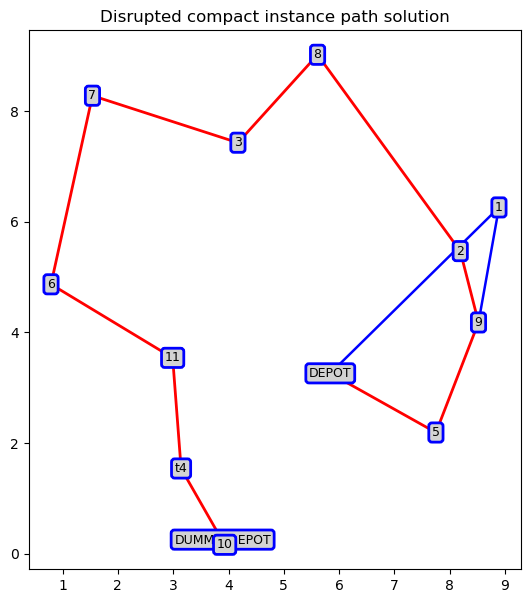

[INFO] Exported: truck_times, drone_times, label, drone_mission, tsp_used
------------------------------------------------------------------------------------------------------------------------


In [1517]:
"""
Disruption TSP-D heuristic on the COMPACT instance (PATH version).

Key fix in this version:
- The disrupted compact instance is treated as a PATH, not a cycle.
- Node 0 is the truck position at disruption time and is labeled "DUMMY_DEPOT".
- The true final depot is node n-1 and is labeled "DEPOT".
- The route drawing does NOT return from the last node back to node 0.
"""

import math
import numpy as np
import time as _time
from collections import defaultdict, OrderedDict

# =========================================================
# Global parameters / toggles
# =========================================================
# SEED should already exist in your notebook/script
SAMPLE_RATIO = 0.3

DRAW_ROUTES = True

LS_EPS = 1e-9
LS_MAX_PASSES = 60
LS_MAX_SECONDS = 360.0
LS_MAX_NEIGHBOR_EVALS = 200000

PART_ATTEMPT_MULT = 10

TRUCK_SPEED = 25.0
DRONE_SPEED = 35.0

# these will be set in main()
V1 = None
Reg = None
tT = None
dT = None
tsp1 = None
# DRN is expected to be defined before calling main()

# =========================================================
# Optional drawing imports
# =========================================================
try:
    import matplotlib.pyplot as plt
except Exception:
    plt = None

# =========================================================
# Fallback 2-opt (only used if tsp_init is None)
# =========================================================
try:
    from solving_TSP import two_opt_for_TSP
except Exception:
    def two_opt_for_TSP(V):
        return list(range(len(V)))

# =========================================================
# Basic guards / helpers
# =========================================================
def _ensure_travel_times():
    global tT, dT
    if not isinstance(tT, dict) or not isinstance(dT, dict):
        raise RuntimeError("tT and dT must be defined as dicts before running.")


def get_forbidden_drone_nodes():
    """
    Build ND set: nodes that can NEVER be drone-only customers.

    Always forbid:
      - dummy depot / current truck location (0)
      - final depot (n-1)
      - DRN (if any)

    Also include ND_compact if provided externally.
    """
    global V1, DRN

    n = len(V1)
    last_idx = n - 1

    base = set()
    if "ND_compact" in globals():
        base |= set(ND_compact)

    base.add(0)
    base.add(last_idx)

    if DRN is not None:
        base.add(DRN)

    return base

# =========================================================
# Robust travel-time accessors (compact ids)
# =========================================================
def truck_time(i, j):
    """
    Truck travel time lookup:
      1) tT[(i,j)]
      2) tT[(j,i)]
      3) recompute from geometry (Manhattan / TRUCK_SPEED) in minutes
    """
    global tT, V1

    if (i, j) in tT:
        return tT[(i, j)]
    if (j, i) in tT:
        return tT[(j, i)]

    xi, yi = V1[i]
    xj, yj = V1[j]
    manhattan = abs(xi - xj) + abs(yi - yj)
    val = (manhattan / TRUCK_SPEED) * 60.0
    tT[(i, j)] = val
    tT[(j, i)] = val
    return val


def drone_time(i, j):
    """
    Drone travel time lookup:
      1) dT[(i,j)]
      2) dT[(j,i)]
      3) recompute from geometry (Euclidean / DRONE_SPEED) in minutes
    """
    global dT, V1

    if (i, j) in dT:
        return dT[(i, j)]
    if (j, i) in dT:
        return dT[(j, i)]

    xi, yi = V1[i]
    xj, yj = V1[j]
    euclid = math.hypot(xi - xj, yi - yj)
    val = (euclid / DRONE_SPEED) * 60.0
    dT[(i, j)] = val
    dT[(j, i)] = val
    return val

# =========================================================
# Disruption checks
# =========================================================
def is_in_disruption(region_idx, t):
    """
    True if time t is inside the disruption window of region_idx.
    Region 0 / None = no disruption.
    """
    if region_idx is None or region_idx <= 0:
        return False
    start, end = TCon[region_idx]
    return (t >= start) and (t <= end)


def disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
    """
    Check:
      (1) Region-based disruption:
          launch, service, rendezvous times must NOT be inside disruption.
      (2) DRN constraints:
          - no launch from DRN
          - all launches after truck arrival at DRN
    """
    global Reg, DRN

    for d, (L, R) in drone_mission.items():
        if L not in drone_times or d not in drone_times or R not in drone_times:
            return False

        if is_in_disruption(Reg[L], drone_times[L][1]):
            return False
        if is_in_disruption(Reg[d], drone_times[d][0]):
            return False
        if is_in_disruption(Reg[R], drone_times[R][0]):
            return False

    if DRN is not None:
        if DRN not in truck_times:
            return False

        rescue_arrival = truck_times[DRN][0]

        for d, (L, R) in drone_mission.items():
            if L == DRN:
                return False
            if L not in drone_times:
                return False
            launch_time = drone_times[L][1]
            if launch_time < rescue_arrival - 1e-9:
                return False

    return True

# =========================================================
# Arrival / departure times
# =========================================================
def compute_arrival_times(tsp, depot, label, drone_mission):
    """
    Compute arrival/dep times for TRUCK and DRONE on compact instance.

    - Launch at L: SL = 1 (0 if L == depot)
    - Recovery at R: SR = 1
    - Drone-only customer: 0 service time
    """
    _ensure_travel_times()

    SL_default = 1.0
    SR = 1.0

    truck_path = [u for u in tsp if label.get(u, "combined") != "drone"]

    missions_by_L = defaultdict(list)
    missions_by_R = defaultdict(list)
    for d, (L, R) in drone_mission.items():
        missions_by_L[L].append(d)
        missions_by_R[R].append(d)

    truck_times = {}
    drone_times = {}
    drone_R_time = {}

    if not truck_path:
        return truck_times, drone_times

    for u in truck_path:
        drone_times[u] = [0.0, 0.0]

    t = 0.0
    start = truck_path[0]
    truck_times[start] = [t, t]

    if start in missions_by_R:
        known = [drone_R_time[d] for d in missions_by_R[start] if d in drone_R_time]
        if known:
            latest = max(known)
            if latest > t:
                t = latest
            t += SR
            truck_times[start][1] = t
            for d in missions_by_R[start]:
                if d in drone_R_time:
                    drone_times[start] = [drone_R_time[d], t]

    if start in missions_by_L:
        for d in missions_by_L[start]:
            L = start
            R = drone_mission[d][1]
            SL = 0.0 if L == depot else SL_default
            t += SL
            truck_times[L][1] = t

            arrL = truck_times[L][0]
            drone_times[L] = [arrL, t]

            d_arr = t + drone_time(L, d)
            R_arr = d_arr + drone_time(d, R)
            drone_times[d] = [d_arr, d_arr]
            drone_R_time[d] = R_arr

    for idx in range(1, len(truck_path)):
        prev = truck_path[idx - 1]
        cur = truck_path[idx]

        t += truck_time(prev, cur)
        truck_times[cur] = [t, t]

        if cur in missions_by_R:
            known = [drone_R_time[d] for d in missions_by_R[cur] if d in drone_R_time]
            if known:
                latest = max(known)
                if latest > t:
                    t = latest
                t += SR
                truck_times[cur][1] = t
                for d in missions_by_R[cur]:
                    if d in drone_R_time:
                        drone_times[cur] = [drone_R_time[d], t]

        if cur in missions_by_L:
            for d in missions_by_L[cur]:
                L = cur
                R = drone_mission[d][1]
                SL = 0.0 if L == depot else SL_default
                t += SL
                truck_times[L][1] = t

                arrL = truck_times[L][0]
                if L not in drone_times:
                    drone_times[L] = [arrL, t]
                else:
                    if drone_times[L][0] == 0.0:
                        drone_times[L][0] = arrL
                    drone_times[L][1] = max(drone_times[L][1], t)

                d_arr = t + drone_time(L, d)
                R_arr = d_arr + drone_time(d, R)
                drone_times[d] = [d_arr, d_arr]
                drone_R_time[d] = R_arr

    return truck_times, drone_times


def compute_true_makespan(truck_times, drone_times):
    max_t = 0.0
    for a, d in truck_times.values():
        max_t = max(max_t, a, d)
    for a, d in drone_times.values():
        max_t = max(max_t, a, d)
    return max_t

# =========================================================
# Path-based helpers for greedy partitioning
# =========================================================
def _find_left_mission_block(tsp, label, pos):
    """
    For PUSH LEFT:
    Find mission block immediately to the left of pos:
        L ... d ... R_old
    where R_old = tsp[pos-1] is currently combined.

    Returns:
        (d, L, R_old) or None
    """
    if pos <= 1:
        return None

    R_old = tsp[pos - 1]
    if label.get(R_old) != "combined":
        return None

    dronenode_idx = None
    j = pos - 2

    while j >= 0 and label.get(tsp[j]) != "combined":
        if label.get(tsp[j]) == "drone":
            dronenode_idx = j
        j -= 1

    if j >= 0 and dronenode_idx is not None:
        L = tsp[j]
        d = tsp[dronenode_idx]
        return d, L, R_old

    return None


def _find_right_mission_block(tsp, label, pos):
    """
    For PUSH RIGHT:
    Find mission block immediately to the right of pos:
        L_old ... d ... R
    where L_old = tsp[pos+1] is currently combined.

    Returns:
        (d, L_old, R) or None
    """
    n1 = len(tsp)
    if pos >= n1 - 2:
        return None

    L_old = tsp[pos + 1]
    if label.get(L_old) != "combined":
        return None

    dronenode_idx = None
    j = pos + 2

    while j < n1 and label.get(tsp[j]) != "combined":
        if label.get(tsp[j]) == "drone":
            dronenode_idx = j
        j += 1

    if j < n1 and dronenode_idx is not None:
        R = tsp[j]
        d = tsp[dronenode_idx]
        return d, L_old, R

    return None

# =========================================================
# Greedy partitioning with disruption + DRN (PATH VERSION)
# =========================================================
def greedy_partitioning(tsp, depot, alpha=1.0):
    """
    Main greedy partitioning on a PATH:
      - Make Fly
      - Push Left
      - Push Right

    Constraints:
      - energy limit e = 20
      - region-based disruption constraints
      - DRN constraints
      - ND set forbidding some nodes as drone-only

    IMPORTANT:
      tsp is treated as a PATH from tsp[0] to tsp[-1].
      No wrap-around / no modulo indexing is used here.
    """
    _ensure_travel_times()
    ND = get_forbidden_drone_nodes()
    e = 20.0

    label = {u: "simple" for u in tsp}
    operation, flyop, driveop = {}, {}, {}
    drone_mission = {}

    n1 = len(tsp)

    tsptotal = 0.0
    for k in range(n1 - 1):
        tsptotal += truck_time(tsp[k], tsp[k + 1])

    tspdtotal = tsptotal
    truck_times = {}
    drone_times = {}
    done = False

    if n1 < 3:
        for u in label:
            label[u] = "combined"
        truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
        dset = {u for u in label if label[u] == "drone"}
        return tspdtotal, label, dset, drone_mission, truck_times, drone_times

    while "simple" in label.values() and not done:
        banned = set()
        attempts = 0
        MAX_ATTEMPTS = max(5, PART_ATTEMPT_MULT * len(label))

        while True:
            attempts += 1

            if attempts > MAX_ATTEMPTS:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                    print("[WARN] Final partition violates disruption constraints (attempt cap).")
                done = True
                break

            ms = []
            idx_map = []

            # 1) Make Fly
            for pos in range(1, n1 - 1):
                if (0, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((0, pos))
                    continue

                saving = -float("inf")
                u = tsp[pos]

                if label[u] == "simple" and u not in ND and u != depot:
                    L = tsp[pos - 1]
                    R = tsp[pos + 1]

                    if DRN is not None and L == DRN:
                        ms.append(-float("inf"))
                        idx_map.append((0, pos))
                        continue

                    fly_time = drone_time(L, u) + drone_time(u, R)
                    drive_time = truck_time(L, R)

                    if fly_time + 1.0 <= e and drive_time <= e:
                        base = truck_time(L, u) + truck_time(u, R)
                        alt = max(fly_time, drive_time + 2.0)
                        saving = base - alt

                ms.append(saving)
                idx_map.append((0, pos))

            # 2) Push Left
            for pos in range(1, n1 - 1):
                if (1, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((1, pos))
                    continue

                saving = -float("inf")
                cur = tsp[pos]
                prev = tsp[pos - 1]

                if label.get(prev) == "combined" and label.get(cur) == "simple" and prev != depot:
                    found = _find_left_mission_block(tsp, label, pos)
                    if found is not None:
                        d, L, R_old = found

                        if DRN is None or L != DRN:
                            base_key = (d, L, R_old)
                            if (d not in ND) and (base_key in operation) and (base_key in driveop):
                                R_new = cur
                                fly_new = drone_time(L, d) + drone_time(d, R_new)
                                drive_new = driveop[base_key] + truck_time(R_old, R_new)

                                if fly_new + 1.0 <= e and drive_new <= e:
                                    saving = (
                                        truck_time(R_old, R_new) + operation[base_key]
                                        - max(fly_new, drive_new + 2.0)
                                    )

                ms.append(saving)
                idx_map.append((1, pos))

            # 3) Push Right
            for pos in range(1, n1 - 1):
                if (2, pos) in banned:
                    ms.append(-float("inf"))
                    idx_map.append((2, pos))
                    continue

                saving = -float("inf")
                cur = tsp[pos]

                found = _find_right_mission_block(tsp, label, pos)
                if label.get(cur) == "simple" and found is not None:
                    d, L_old, R = found

                    if DRN is None or (L_old != DRN and cur != DRN):
                        base_key = (d, L_old, R)
                        if (d not in ND) and (base_key in operation) and (base_key in driveop):
                            L_new = cur
                            fly_new = drone_time(L_new, d) + drone_time(d, R)
                            drive_new = driveop[base_key] + truck_time(L_new, L_old)

                            if fly_new + 1.0 <= e and drive_new <= e:
                                saving = (
                                    truck_time(L_new, L_old) + operation[base_key]
                                    - max(fly_new, drive_new + 2.0)
                                )

                ms.append(saving)
                idx_map.append((2, pos))

            if not ms:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                done = True
                break

            idx = int(np.argmax(ms))
            best_saving = ms[idx]

            if best_saving <= 0:
                for u in label:
                    if label[u] == "simple":
                        label[u] = "combined"
                truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)
                if not disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                    print("[WARN] Final partition violates disruption constraints.")
                done = True
                break

            block, pos = idx_map[idx]

            label_b = dict(label)
            drone_b = dict(drone_mission)
            op_b = dict(operation)
            flyop_b = dict(flyop)
            driveop_b = dict(driveop)
            tspd_b = tspdtotal

            if block == 0:
                d = tsp[pos]
                L = tsp[pos - 1]
                R = tsp[pos + 1]

                if DRN is not None and L == DRN:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                label[d] = "drone"
                label[L] = "combined"
                label[R] = "combined"

                flyop[(d, L, R)] = drone_time(L, d) + drone_time(d, R)
                driveop[(d, L, R)] = truck_time(L, R)
                operation[(d, L, R)] = max(flyop[(d, L, R)], driveop[(d, L, R)])
                drone_mission[d] = (L, R)

            elif block == 1:
                found = _find_left_mission_block(tsp, label, pos)
                if found is None:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                d, L, R_old = found
                R_new = tsp[pos]

                if DRN is not None and L == DRN:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                label[R_new] = "combined"
                label[R_old] = "truck"

                flyop[(d, L, R_new)] = drone_time(L, d) + drone_time(d, R_new)
                driveop[(d, L, R_new)] = driveop[(d, L, R_old)] + truck_time(R_old, R_new)
                operation[(d, L, R_new)] = max(flyop[(d, L, R_new)], driveop[(d, L, R_new)])
                drone_mission[d] = (L, R_new)

            else:
                found = _find_right_mission_block(tsp, label, pos)
                if found is None:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                d, L_old, R = found
                L_new = tsp[pos]

                if DRN is not None and L_new == DRN:
                    banned.add((block, pos))
                    label = label_b
                    drone_mission = drone_b
                    operation = op_b
                    flyop = flyop_b
                    driveop = driveop_b
                    tspdtotal = tspd_b
                    continue

                label[L_new] = "combined"
                label[L_old] = "truck"

                flyop[(d, L_new, R)] = drone_time(L_new, d) + drone_time(d, R)
                driveop[(d, L_new, R)] = driveop[(d, L_old, R)] + truck_time(L_new, L_old)
                operation[(d, L_new, R)] = max(flyop[(d, L_new, R)], driveop[(d, L_new, R)])
                drone_mission[d] = (L_new, R)

            tspdtotal -= best_saving

            truck_times, drone_times = compute_arrival_times(tsp, depot, label, drone_mission)

            if disruption_constraints_satisfied(drone_mission, truck_times, drone_times):
                break
            else:
                label = label_b
                drone_mission = drone_b
                operation = op_b
                flyop = flyop_b
                driveop = driveop_b
                tspdtotal = tspd_b
                banned.add((block, pos))

    dset = {u for u in label if label[u] == "drone"}
    return tspdtotal, label, dset, drone_mission, truck_times, drone_times

# =========================================================
# Move operators + local search (with endpoints pinned)
# =========================================================
def two_points_move(route, i, j):
    if i == j:
        return route[:]
    r = route[:]
    r[i], r[j] = r[j], r[i]
    return r


def two_opt_move(route, i, j):
    if i == j:
        return route[:]
    if i > j:
        i, j = j, i
    return route[:i+1] + route[i+1:j+1][::-1] + route[j+1:]


def one_point_move(route, i, j):
    if i == j:
        return route[:]
    r = route[:]
    node = r.pop(i)
    r.insert(j, node)
    return r


def _rotate_to_depot(route, depot):
    """
    Kept for compatibility, but not used in local search anymore.
    """
    if route[0] == depot:
        return route
    k = route.index(depot)
    return route[k:] + route[:k]


def improve_all(heuristic, route_in, depot, sample_ratio=SAMPLE_RATIO, rng_seed=SEED):
    """
    Generic local search wrapper:
      - route_in is treated as a PATH
      - keep route_in[0] == depot
      - keep route_in[-1] == final depot
      - only move positions 1..n-2
    """
    _ensure_travel_times()

    route_best = list(route_in)
    n = len(route_best)

    assert route_best[0] == depot, "route_in must start at depot in disruption mode."
    pinned_end = route_best[-1]

    cache = {}

    def eval_route(rt):
        assert rt[0] == depot
        assert rt[-1] == pinned_end
        key = tuple(rt)
        if key in cache:
            return cache[key]
        val = heuristic(rt, depot, alpha=1.0)[0]
        cache[key] = val
        return val

    f_best = eval_route(route_best)

    if rng_seed is not None:
        np.random.seed(rng_seed)

    interior = list(range(1, n - 1))
    all_pairs = [(i, j) for i in interior for j in interior if j != i]
    m = len(all_pairs)

    if m == 0:
        return route_best

    k = int(round(sample_ratio * m))
    if k <= 0:
        k = 1
    if k > m:
        k = m

    start_time = _time.time()
    passes = 0
    neighbor_evals = 0

    improved = True
    while improved:
        passes += 1
        if passes > LS_MAX_PASSES:
            break
        if LS_MAX_SECONDS is not None and (_time.time() - start_time) > LS_MAX_SECONDS:
            break

        improved = False
        idxs = np.random.choice(m, size=k, replace=False)
        best_neighbor = None
        best_cost = f_best

        for p in idxs:
            i, j = all_pairs[p]
            for mv in (two_points_move, two_opt_move, one_point_move):
                cand = mv(route_best, i, j)

                if cand[0] != depot or cand[-1] != pinned_end:
                    continue

                neighbor_evals += 1
                fc = eval_route(cand)
                if fc < best_cost - LS_EPS:
                    best_neighbor = cand
                    best_cost = fc

                if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
                    break
            if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
                break

        if best_neighbor is not None:
            route_best = best_neighbor
            f_best = best_cost
            improved = True

        if neighbor_evals >= LS_MAX_NEIGHBOR_EVALS:
            break

    return route_best


def two_opt_greedy_partitioning_all_improved(V, depot, alpha, tsp_init=None):
    """
    Wrapper:
      - If tsp_init is given, use it as the initial PATH
      - Otherwise build a TSP seed and improve it
    """
    _ensure_travel_times()

    n = len(V)
    if tsp_init is not None:
        tsp_seed = list(tsp_init)
        assert tsp_seed[0] == depot, "hp_compact / tsp_init must start at depot."
        assert len(tsp_seed) == n, "tsp_init must visit all nodes."
        assert sorted(tsp_seed) == list(range(n)), "tsp_init must be a permutation of 0..n-1."
        tsp_best = improve_all(
            greedy_partitioning,
            tsp_seed,
            depot,
            sample_ratio=SAMPLE_RATIO,
            rng_seed=SEED
        )
    else:
        tsp_seed = two_opt_for_TSP(V)
        if len(tsp_seed) != n or sorted(tsp_seed) != list(range(n)):
            raise ValueError("Initial tour must be a permutation of 0..n-1.")
        tsp_seed = _rotate_to_depot(tsp_seed, depot)
        tsp_best = improve_all(
            greedy_partitioning,
            tsp_seed,
            depot,
            sample_ratio=SAMPLE_RATIO,
            rng_seed=SEED
        )

    res = greedy_partitioning(tsp_best, depot, alpha)
    return res, tsp_best

# =========================================================
# Path-aware drawing
# =========================================================
def draw_routes_path(V, tsp, label, depot, drone_nodes):
    """
    Draw the compact disrupted solution as a PATH, not a cycle.

    - Node 0 is labeled DUMMY_DEPOT.
    - Node n-1 is labeled DEPOT.
    - Truck path is drawn only from first to last visited truck node.
    - No return edge to node 0.
    """
    if plt is None:
        print("(Route drawing skipped) matplotlib is not available.")
        return

    n = len(V)
    last_idx = n - 1

    fig, ax = plt.subplots(figsize=(10, 7))

    # truck path only (no wrap-around)
    truck_path = [u for u in tsp if label.get(u, "combined") != "drone"]
    for k in range(len(truck_path) - 1):
        i = truck_path[k]
        j = truck_path[k + 1]
        xi, yi = V[i]
        xj, yj = V[j]
        ax.plot([xi, xj], [yi, yj], color="red", linewidth=2)

    # drone missions
    for d in sorted(drone_nodes):
        if "drone_mission" in globals() and d in drone_mission:
            L, R = drone_mission[d]
            xL, yL = V[L]
            xd, yd = V[d]
            xR, yR = V[R]
            ax.plot([xL, xd], [yL, yd], color="blue", linewidth=1.8)
            ax.plot([xd, xR], [yd, yR], color="blue", linewidth=1.8)

    # nodes
    for i, (x, y) in enumerate(V):
        ax.scatter(x, y, s=70, facecolor="lightgray", edgecolor="blue", linewidth=2, zorder=3)

        if i == 0:
            txt = "DUMMY_DEPOT"
        elif i == last_idx:
            txt = "DEPOT"
        else:
            txt = f"t{i}" if i == DRN else str(i)

        ax.text(
            x, y, txt,
            fontsize=9,
            ha="center",
            va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc="lightgray", ec="blue", lw=2)
        )

    ax.set_title("Disrupted compact instance path solution")
    ax.set_aspect("equal", adjustable="box")
    plt.show()

# =========================================================
# MAIN
# =========================================================
def main():
    """
    Attach V2_compact, Reg3, tT_compact, dT_compact, hp_compact, DRN, ND_compact
    to global names. Then run TSP-D disruption heuristic on compact instance.
    """
    global V1, Reg, tT, dT, tsp1, new2old

    V1 = V2_compact
    Reg = list(Reg3)
    tT = dict(tT_compact)
    dT = dict(dT_compact)
    tsp1 = list(hp_compact)

    n = len(V1)
    depot = 0
    alpha = 1.0

    assert len(tsp1) == n, "hp_compact length must equal number of compact nodes."
    assert sorted(tsp1) == list(range(n)), "hp_compact must be a permutation of 0..n-1."
    assert tsp1[0] == 0, "hp_compact must start at node 0 (dummy depot / truck at disruption)."
    assert tsp1[-1] == n - 1, "hp_compact must end at node n-1 (final depot)."

    new2old = {i: i for i in range(n)}

    _ensure_travel_times()

    ND = get_forbidden_drone_nodes()
    print("-" * 120)
    print(f"[INFO] Disrupted instance in compact IDs 0..{n-1}")
    print(f"[INFO] #remaining nodes: {n}")
    print(f"[INFO] ND (forbidden drone nodes): {sorted(ND)}")

    tsp_init = tsp1

    start = _time.time()
    (
        total_cost,
        label,
        drone_nodes,
        drone_mission,
        truck_times,
        drone_times
    ), tsp_used = two_opt_greedy_partitioning_all_improved(
        V1, depot, alpha, tsp_init=tsp_init
    )
    end = _time.time()

    makespan = compute_true_makespan(truck_times, drone_times)

    print(f"Heuristic TSP-D cost (truck - ops): {total_cost:.4f}")
    print(f"True makespan from schedule: {makespan:.4f}")
    print(f"# drone customers: {len(drone_nodes)}")
    print(f"Drone customers (compact IDs): {sorted(drone_nodes)}")

    ordered_labels = OrderedDict((u, label[u]) for u in tsp_used)
    print("Labels along path (visit order, compact IDs):")
    print("# Drone customers before Disruption: ", DroneBefDis)
    print(".................")
    print("SEED is:", SEED)
    print(f"Running time: {end-start:.4f} sec")
    print("Total True makespan from schedule:", round(makespan, 4) + t0)
    print("Total # Drone customers : ", DroneBefDis + len(drone_nodes))
    print("Truck Only : ", TruckOnlyTotal)
    print("TCon is: ", TCon)
    print("SAMPLE_RATIO is: ", SAMPLE_RATIO)
    print(".................")
    print(ordered_labels)

    assert tsp_used[0] == 0, "Final path does not start at 0 (should not happen)."
    assert tsp_used[-1] == n - 1, "Final path does not end at n-1 (should not happen)."

    if DRAW_ROUTES:
        try:
            draw_routes_path(V1, tsp_used, label, depot, drone_nodes)
        except Exception as e:
            print(f"(Route drawing skipped) {e}")

    globals()["truck_times"] = truck_times
    globals()["drone_times"] = drone_times
    globals()["label"] = label
    globals()["drone_mission"] = drone_mission
    globals()["tsp_used"] = tsp_used

    print("[INFO] Exported: truck_times, drone_times, label, drone_mission, tsp_used")
    print("-" * 120)


if __name__ == "__main__":
    main()
